In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vrindabhatia108/reviews-dataset/Reviews.csv


In [2]:
!pip install -q transformers torch datasets pandas tqdm

In [3]:
import transformers
import torch
import pandas

In [4]:
import os

print(os.listdir('/kaggle/input/datasets/vrindabhatia108/reviews-dataset'))

['Reviews.csv']


In [5]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/kaggle/input/datasets/vrindabhatia108/reviews-dataset/Reviews.csv')
print(f'Total reviews: {len(df)}')
print(df.columns.tolist())
print(df.head(3))

Total reviews: 568454
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']
   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought several of the Vitality canned d...  
1      Not as Advertised  Product arrived labeled as Jumbo Salted Peanut...  
2  "Delight" says it all  This is a confection that

# Preprocess & Filter Complaints

In [6]:
import re

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^\w\s.,!?\'\\-]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df = df.rename(columns={
    'UserId': 'user_id',
    'ProductId': 'product_id',
    'Score': 'rating',
    'Text': 'review_text',
    'Summary': 'review_summary'
})
df = df.dropna(subset=['review_text', 'rating'])
df['review_text'] = df['review_text'].apply(clean_text)
df = df[df['review_text'].str.len() > 20]

complaints_df = df[df['rating'] <= 2].copy().reset_index(drop=True)
print(f'Complaint reviews: {len(complaints_df)}')

SAMPLE_SIZE = 5000
sample_df = complaints_df.sample(n=min(SAMPLE_SIZE, len(complaints_df)), random_state=42).reset_index(drop=True)
print(f'Sample size: {len(sample_df)}')

Complaint reviews: 82034
Sample size: 5000


# Sentiment Classification

In [7]:
from transformers import pipeline
from tqdm import tqdm

sentiment_pipe = pipeline(
    'text-classification',
    model='distilbert-base-uncased-finetuned-sst-2-english',
    truncation=True, max_length=512, device=0
)

def run_batch(pipe, texts, batch_size=64, desc=''):
    results = []
    for i in tqdm(range(0, len(texts), batch_size), desc=desc):
        results.extend(pipe(texts[i:i+batch_size], truncation=True, max_length=512))
    return results

texts = sample_df['review_text'].tolist()
sentiment_results = run_batch(sentiment_pipe, texts, desc='Sentiment')

sample_df['sentiment_label'] = [r['label'] for r in sentiment_results]
sample_df['sentiment_score'] = [round(r['score'], 4) for r in sentiment_results]
print(sample_df[['sentiment_label', 'sentiment_score']].head())

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sentiment: 100%|██████████| 79/79 [00:30<00:00,  2.63it/s]

  sentiment_label  sentiment_score
0        NEGATIVE           0.9759
1        NEGATIVE           0.9987
2        NEGATIVE           0.9996
3        NEGATIVE           0.9631
4        NEGATIVE           0.8333


# Emotion & Intensity

In [8]:
emotion_pipe = pipeline(
    'text-classification',
    model='j-hartmann/emotion-english-distilroberta-base',
    truncation=True, max_length=512, device=0
)

emotion_results = run_batch(emotion_pipe, texts, desc='Emotion')

sample_df['emotion_label'] = [r['label'] for r in emotion_results]
sample_df['emotion_score'] = [round(r['score'], 4) for r in emotion_results]

high_intensity = {'anger', 'disgust', 'fear', 'sadness'}
sample_df['intensity'] = sample_df.apply(
    lambda row: min(round(row['emotion_score'] * 1.2, 4), 1.0)
    if row['emotion_label'].lower() in high_intensity
    else round(row['emotion_score'] * 0.8, 4), axis=1
)

print(sample_df['emotion_label'].value_counts())

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Emotion: 100%|██████████| 79/79 [00:31<00:00,  2.52it/s]

emotion_label
disgust     1955
neutral     1630
sadness      552
surprise     474
anger        155
joy          142
fear          92
Name: count, dtype: int64


# Aspect Extraction (ABSA)

In [9]:
from collections import Counter

ASPECT_KEYWORDS = {
    'quality':   ['quality','material','build','broke','cheap','durable','defective','flimsy','damaged','faulty'],
    'delivery':  ['shipping','delivery','arrived','late','delayed','package','days','weeks','shipped','tracking'],
    'price':     ['price','expensive','overpriced','cost','worth','value','money','refund','charged'],
    'service':   ['service','support','customer','response','seller','return','refund','help','contact','reply'],
    'packaging': ['packaging','box','wrapped','damaged','broken','crushed','opened','seal'],
    'usability': ['use','works','instructions','setup','install','function','difficult','confusing']
}

def extract_aspects(text):
    text_lower = text.lower()
    found = [a for a, kws in ASPECT_KEYWORDS.items() if any(k in text_lower for k in kws)]
    return found if found else ['general']

sample_df['aspects'] = sample_df['review_text'].apply(extract_aspects)
sample_df['primary_aspect'] = sample_df['aspects'].apply(lambda x: x[0])
sample_df['aspects_str'] = sample_df['aspects'].apply(lambda x: '|'.join(x))

all_aspects = [a for sub in sample_df['aspects'] for a in sub]
print(Counter(all_aspects).most_common())

[('usability', 1746), ('general', 1425), ('delivery', 1339), ('price', 1305), ('packaging', 1041), ('service', 776), ('quality', 681)]


# User Complaint Profiles

In [10]:
def build_user_profile(group):
    all_asp = [a for sub in group['aspects'] for a in sub]
    asp_counts = Counter(all_asp)
    return pd.Series({
        'num_complaints':      len(group),
        'avg_rating':          round(group['rating'].mean(), 2),
        'avg_intensity':       round(group['intensity'].mean(), 4),
        'dominant_emotion':    group['emotion_label'].mode()[0],
        'dominant_aspect':     asp_counts.most_common(1)[0][0] if asp_counts else 'general',
        'aspects_all':         '|'.join(set(all_asp)),
        'sentiment_neg_ratio': round((group['sentiment_label']=='NEGATIVE').sum()/len(group), 4)
    })

user_profiles = sample_df.groupby('user_id').apply(build_user_profile).reset_index()
print(f'User profiles: {len(user_profiles)}')
print(user_profiles.head())

User profiles: 4553
              user_id  num_complaints  avg_rating  avg_intensity  \
0  #oc-R1522DF2LUL4G1               1         1.0         0.9668   
1  #oc-R18WQYZLWDZTSW               1         1.0         0.7568   
2  #oc-R1L7FHRQYER2JG               1         2.0         0.8338   
3  #oc-R1YD35BFIT2RUP               1         1.0         1.0000   
4  #oc-R2H7Z7E2A1H0F3               1         1.0         1.0000   

  dominant_emotion dominant_aspect aspects_all  sentiment_neg_ratio  
0          disgust         general     general                  1.0  
1          neutral         quality     quality                  0.0  
2          disgust           price       price                  1.0  
3          disgust       packaging   packaging                  1.0  
4          disgust       usability   usability                  1.0  


#  Save Outputs

In [11]:
sample_df.to_csv('complaint_reviews_annotated.csv', index=False)
user_profiles.to_csv('user_complaint_profiles.csv', index=False)
complaints_df[['user_id','product_id','rating']].to_csv('user_item_ratings.csv', index=False)
print('Done. 3 files saved')

Done. 3 files saved


#  Plots (Thesis Figures)

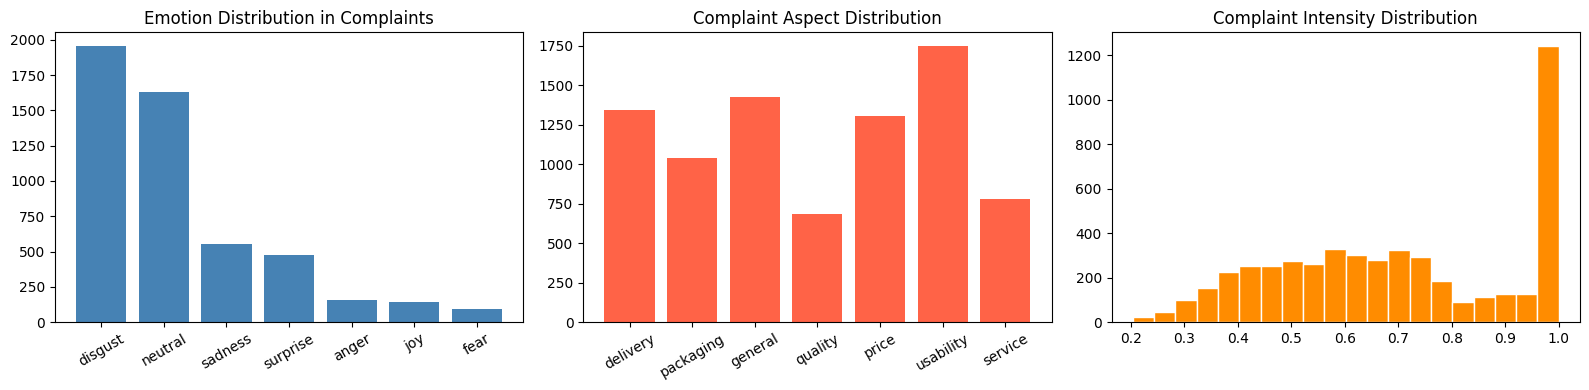

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

emotion_counts = sample_df['emotion_label'].value_counts()
axes[0].bar(emotion_counts.index, emotion_counts.values, color='steelblue')
axes[0].set_title('Emotion Distribution in Complaints')
axes[0].tick_params(axis='x', rotation=30)

asp_counts = Counter(all_aspects)
axes[1].bar(asp_counts.keys(), asp_counts.values(), color='tomato')
axes[1].set_title('Complaint Aspect Distribution')
axes[1].tick_params(axis='x', rotation=30)

axes[2].hist(sample_df['intensity'], bins=20, color='darkorange', edgecolor='white')
axes[2].set_title('Complaint Intensity Distribution')

plt.tight_layout()
plt.savefig('day1_plots.png', dpi=150)
plt.show()

In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import time
print('OK')

OK


# LOAD AND SAMPLE DATA

In [2]:
ratings_df    = pd.read_csv('/kaggle/working/user_item_ratings.csv')
user_profiles = pd.read_csv('/kaggle/working/user_complaint_profiles.csv')

# Keep only users with at least 3 reviews — reduces matrix size dramatically
user_counts = ratings_df['user_id'].value_counts()
active_users = user_counts[user_counts >= 3].index
ratings_df = ratings_df[ratings_df['user_id'].isin(active_users)].reset_index(drop=True)

# Also keep only products with at least 3 reviews
product_counts = ratings_df['product_id'].value_counts()
active_products = product_counts[product_counts >= 3].index
ratings_df = ratings_df[ratings_df['product_id'].isin(active_products)].reset_index(drop=True)

print(f'Filtered ratings: {len(ratings_df)}')
print(f'Unique users:     {ratings_df["user_id"].nunique()}')
print(f'Unique products:  {ratings_df["product_id"].nunique()}')

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/user_item_ratings.csv'

# ENCODE AND SPLIT

In [3]:
user_enc    = LabelEncoder()
product_enc = LabelEncoder()

ratings_df['user_idx']    = user_enc.fit_transform(ratings_df['user_id'])
ratings_df['product_idx'] = product_enc.fit_transform(ratings_df['product_id'])

n_users    = ratings_df['user_idx'].nunique()
n_products = ratings_df['product_idx'].nunique()
print(f'Matrix size: {n_users} x {n_products}')
print(f'Estimated dense matrix MB: {n_users * n_products * 8 / 1e6:.1f} MB')

train_df, test_df = train_test_split(ratings_df, test_size=0.2, random_state=42)

train_matrix = csr_matrix(
    (train_df['rating'].astype(float),
     (train_df['user_idx'], train_df['product_idx'])),
    shape=(n_users, n_products)
)
print(f'Train: {len(train_df)}, Test: {len(test_df)}')

NameError: name 'ratings_df' is not defined

# TRAIN BASELINE SVD

In [4]:
k = 30  # reduced from 50 to save memory

print('Training Baseline SVD...')
start = time.time()
U, sigma, Vt = svds(train_matrix.astype(float), k=k)
print(f'Done in {time.time()-start:.1f}s')
print(f'U: {U.shape}, Vt: {Vt.shape}')

# Do NOT build full dense matrix — predict only what we need
def predict_for_pairs(U, sigma, Vt, user_idxs, product_idxs):
    # Predict ratings for specific (user, product) pairs only
    user_factors    = U[user_idxs] * sigma  # (n, k)
    product_factors = Vt[:, product_idxs].T  # (n, k)
    return np.sum(user_factors * product_factors, axis=1)

def predict_top_k_per_user(U, sigma, Vt, user_idxs, k=10):
    # Returns top-k product indices per user without building full matrix
    user_factors = U[user_idxs] * sigma       # (n_users, k)
    scores       = user_factors @ Vt          # (n_users, n_products)
    return np.argsort(scores, axis=1)[:, ::-1][:, :k]

print('Baseline ready')

Training Baseline SVD...


NameError: name 'train_matrix' is not defined

# EVALUATE BASELINE SVD

In [18]:
def rmse(preds, actuals):
    return np.sqrt(np.mean((preds - actuals) ** 2))

def mae(preds, actuals):
    return np.mean(np.abs(preds - actuals))

def precision_recall_at_k_sparse(U, sigma, Vt, df, k=10, batch_size=500):
    precisions, recalls = [], []
    unique_users = df['user_idx'].unique()

    for i in range(0, len(unique_users), batch_size):
        batch_users = unique_users[i:i+batch_size]
        top_k_all   = predict_top_k_per_user(U, sigma, Vt, batch_users, k=k)

        for j, uid in enumerate(batch_users):
            user_test   = df[df['user_idx'] == uid]
            relevant    = set(user_test['product_idx'].values)
            recommended = set(top_k_all[j])
            hits        = len(relevant & recommended)
            precisions.append(hits / k)
            recalls.append(hits / len(relevant) if relevant else 0)

    return np.mean(precisions), np.mean(recalls)

# Point predictions for RMSE/MAE
test_preds    = predict_for_pairs(U, sigma, Vt,
                    test_df['user_idx'].values,
                    test_df['product_idx'].values)
baseline_rmse = rmse(test_preds, test_df['rating'].values)
baseline_mae  = mae(test_preds,  test_df['rating'].values)

print('Computing Baseline P@K R@K...')
b_p5,  b_r5  = precision_recall_at_k_sparse(U, sigma, Vt, test_df, k=5)
b_p10, b_r10 = precision_recall_at_k_sparse(U, sigma, Vt, test_df, k=10)

print(f'\nBaseline Results:')
print(f'  RMSE: {baseline_rmse:.4f}  MAE: {baseline_mae:.4f}')
print(f'  P@5:  {b_p5:.4f}  P@10: {b_p10:.4f}')
print(f'  R@5:  {b_r5:.4f}  R@10: {b_r10:.4f}')

Computing Baseline P@K R@K...

Baseline Results:
  RMSE: 1.3430  MAE: 1.0935
  P@5:  0.0713  P@10: 0.0559
  R@5:  0.2164  R@10: 0.3158


# AUGMENTATION MATRIX

In [19]:
augmented_df = train_df.merge(
    user_profiles[['user_id', 'avg_intensity', 'sentiment_neg_ratio']],
    on='user_id', how='left'
)
augmented_df['avg_intensity'].fillna(0.0, inplace=True)

def augment_rating(row):
    if row['rating'] <= 2 and row['avg_intensity'] > 0:
        return max(1.0, row['rating'] - row['avg_intensity'] * 0.5)
    return float(row['rating'])

augmented_df['aug_rating'] = augmented_df.apply(augment_rating, axis=1)

aug_matrix = csr_matrix(
    (augmented_df['aug_rating'].astype(float),
     (augmented_df['user_idx'], augmented_df['product_idx'])),
    shape=(n_users, n_products)
)
print(f'Original mean:  {train_df["rating"].mean():.4f}')
print(f'Augmented mean: {augmented_df["aug_rating"].mean():.4f}')

Original mean:  1.3820
Augmented mean: 1.3378


# Train & Evaluate Augmented

In [20]:
print('Training Augmented SVD...')
start = time.time()
U2, s2, Vt2 = svds(aug_matrix.astype(float), k=k)
print(f'Done in {time.time()-start:.1f}s')

aug_preds  = predict_for_pairs(U2, s2, Vt2,
                 test_df['user_idx'].values,
                 test_df['product_idx'].values)
aug_rmse   = rmse(aug_preds, test_df['rating'].values)
aug_mae_v  = mae(aug_preds,  test_df['rating'].values)

print('Computing Augmented P@K R@K...')
a_p5,  a_r5  = precision_recall_at_k_sparse(U2, s2, Vt2, test_df, k=5)
a_p10, a_r10 = precision_recall_at_k_sparse(U2, s2, Vt2, test_df, k=10)

print(f'\nAugmented Results:')
print(f'  RMSE: {aug_rmse:.4f}  MAE: {aug_mae_v:.4f}')
print(f'  P@5:  {a_p5:.4f}  P@10: {a_p10:.4f}')
print(f'  R@5:  {a_r5:.4f}  R@10: {a_r10:.4f}')

Training Augmented SVD...
Done in 0.2s
Computing Augmented P@K R@K...

Augmented Results:
  RMSE: 1.3490  MAE: 1.1025
  P@5:  0.0755  P@10: 0.0569
  R@5:  0.2340  R@10: 0.3296


# Comparison Table

In [22]:
results = pd.DataFrame({
    'Model':        ['Baseline SVD', 'Sentiment-Augmented SVD (Ours)'],
    'RMSE':         [round(baseline_rmse, 4), round(aug_rmse,   4)],
    'MAE':          [round(baseline_mae,  4), round(aug_mae_v,  4)],
    'Precision@5':  [round(b_p5,  4),         round(a_p5,  4)],
    'Precision@10': [round(b_p10, 4),         round(a_p10, 4)],
    'Recall@5':     [round(b_r5,  4),         round(a_r5,  4)],
    'Recall@10':    [round(b_r10, 4),         round(a_r10, 4)],
})
print('\n===== THESIS RESULTS TABLE =====')
print(results.to_string(index=False))
results.to_csv('model_comparison_results.csv', index=False)


===== THESIS RESULTS TABLE =====
                         Model  RMSE    MAE  Precision@5  Precision@10  Recall@5  Recall@10
                  Baseline SVD 1.343 1.0935       0.0713        0.0559    0.2164     0.3158
Sentiment-Augmented SVD (Ours) 1.349 1.1025       0.0755        0.0569    0.2340     0.3296


# plot of result

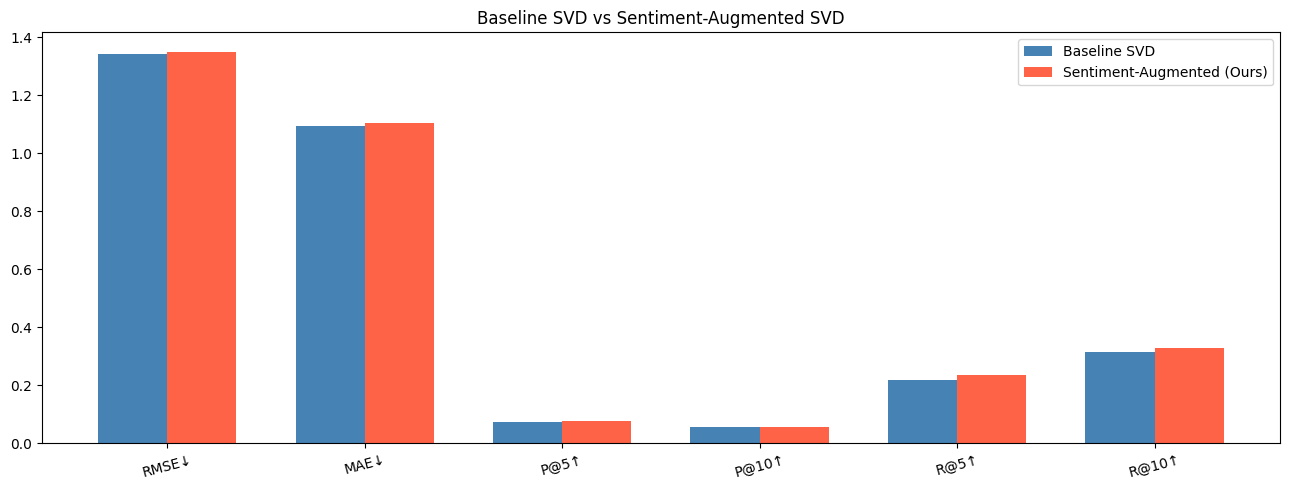

In [23]:
metrics        = ['RMSE↓','MAE↓','P@5↑','P@10↑','R@5↑','R@10↑']
baseline_vals  = [baseline_rmse, baseline_mae, b_p5, b_p10, b_r5, b_r10]
augmented_vals = [aug_rmse, aug_mae_v, a_p5, a_p10, a_r5, a_r10]

x, w = np.arange(len(metrics)), 0.35
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - w/2, baseline_vals,  w, label='Baseline SVD',               color='steelblue')
ax.bar(x + w/2, augmented_vals, w, label='Sentiment-Augmented (Ours)', color='tomato')
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.set_title('Baseline SVD vs Sentiment-Augmented SVD')
ax.legend()
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

In [5]:
!pip install -q xgboost

In [6]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier, XGBRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, classification_report
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
print('All imports OK')

All imports OK


In [7]:
import os


In [8]:
print(os.listdir('/kaggle/input/datasets/vrindabhatia108'))

['user-complaint-profiles', 'complaint-reviews-annotated', 'reviews-dataset', 'user-item-ratings']


# LOAD DATA

In [9]:
import pandas as pd

# Load datasets from Kaggle input (NOT /working)
annotated_df  = pd.read_csv('/kaggle/input/datasets/vrindabhatia108/complaint-reviews-annotated/complaint_reviews_annotated.csv')

user_profiles = pd.read_csv('/kaggle/input/datasets/vrindabhatia108/user-complaint-profiles/user_complaint_profiles.csv')

ratings_df    = pd.read_csv('/kaggle/input/datasets/vrindabhatia108/user-item-ratings/user_item_ratings.csv')

# Check data
print(f'Annotated complaints: {len(annotated_df)}')
print(f'Columns: {annotated_df.columns.tolist()}')
print(annotated_df.head(3))

Annotated complaints: 5000
Columns: ['Id', 'product_id', 'user_id', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'rating', 'Time', 'review_summary', 'review_text', 'sentiment_label', 'sentiment_score', 'emotion_label', 'emotion_score', 'intensity', 'aspects', 'primary_aspect', 'aspects_str']
       Id  product_id         user_id              ProfileName  \
0   39795  B000E7QYNG   AZS8MAGN4582L  L. Perry "coffee lover"   
1  361324  B00005IX96  A1E4ERFN67OMJY                      ahl   
2  224888  B000ETPYZS  A33P6XJA24BYBC               Lauriep772   

   HelpfulnessNumerator  HelpfulnessDenominator  rating        Time  \
0                     7                       7       1  1329609600   
1                     1                       3       1  1196208000   
2                     0                       0       1  1312156800   

                        review_summary  \
0                  Has live grain bugs   
1        LATE..OUTDATED..6 MONTHS LATE   
2  I paid f

#  Build Feature Matrix

In [10]:
df = annotated_df.copy()

# Encode categorical features
le_aspect  = LabelEncoder()
le_emotion = LabelEncoder()
le_sent    = LabelEncoder()
le_user    = LabelEncoder()
le_product = LabelEncoder()

df['aspect_enc']    = le_aspect.fit_transform(df['primary_aspect'])
df['emotion_enc']   = le_emotion.fit_transform(df['emotion_label'])
df['sentiment_enc'] = le_sent.fit_transform(df['sentiment_label'])
df['user_enc']      = le_user.fit_transform(df['user_id'])
df['product_enc']   = le_product.fit_transform(df['product_id'])

# Feature columns
feature_cols = [
    'user_enc',
    'product_enc',
    'sentiment_score',
    'emotion_score',
    'intensity',
    'aspect_enc',
    'emotion_enc',
    'sentiment_enc'
]

X = df[feature_cols]
y_regression     = df['rating'].astype(float)           
y_classification = (df['rating'] == 1).astype(int)   

print(f'Feature matrix shape: {X.shape}')
print(f'Complaint ratio: {y_classification.mean():.2%}')
print(f'\nFeature columns: {feature_cols}')

Feature matrix shape: (5000, 8)
Complaint ratio: 64.04%

Feature columns: ['user_enc', 'product_enc', 'sentiment_score', 'emotion_score', 'intensity', 'aspect_enc', 'emotion_enc', 'sentiment_enc']


#  Train/Test Split

In [11]:
X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_regression, y_classification,
    test_size=0.2, random_state=42
)

print(f'Train: {len(X_train)}, Test: {len(X_test)}')

Train: 4000, Test: 1000


#   Model 1: XGBoost Regression (Rating Prediction)

In [12]:
print('Training XGBoost Regressor...')
xgb_reg = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    verbosity=0
)
xgb_reg.fit(X_train, y_reg_train)

reg_preds     = xgb_reg.predict(X_test)
xgb_rmse      = np.sqrt(mean_squared_error(y_reg_test, reg_preds))
xgb_mae       = mean_absolute_error(y_reg_test, reg_preds)

print(f'\nXGBoost Regressor Results:')
print(f'  RMSE: {xgb_rmse:.4f}')
print(f'  MAE:  {xgb_mae:.4f}')

Training XGBoost Regressor...

XGBoost Regressor Results:
  RMSE: 0.4711
  MAE:  0.4092


# Model 2: XGBoost Classifier (Complaint Detection)

In [13]:
print('Training XGBoost Classifier...')
xgb_cls = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    verbosity=0,
    eval_metric='logloss'
)
xgb_cls.fit(X_train, y_cls_train)

cls_preds = xgb_cls.predict(X_test)
print('\nXGBoost Classifier Report:')
print(classification_report(y_cls_test, cls_preds,
      target_names=['Not Complaint', 'Complaint']))

Training XGBoost Classifier...

XGBoost Classifier Report:
               precision    recall  f1-score   support

Not Complaint       0.56      0.39      0.46       359
    Complaint       0.71      0.83      0.76       641

     accuracy                           0.67      1000
    macro avg       0.63      0.61      0.61      1000
 weighted avg       0.65      0.67      0.65      1000



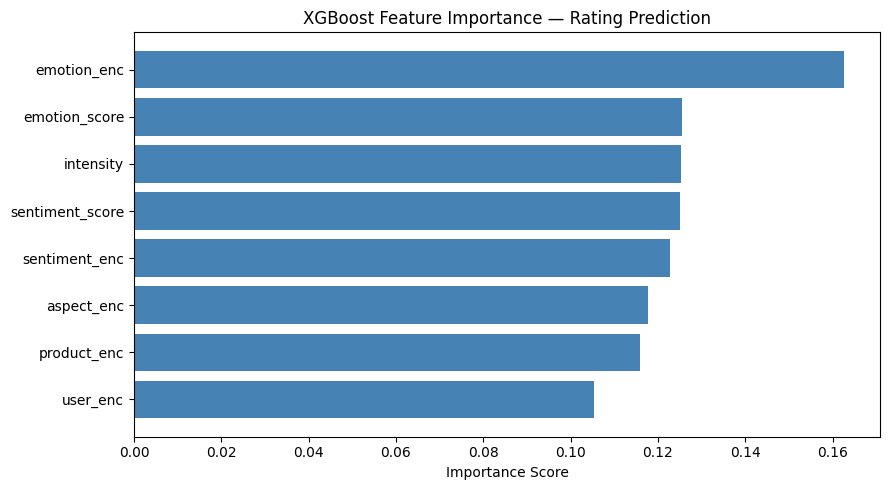

Saved: xgboost_feature_importance.png


In [14]:
importance_df = pd.DataFrame({
    'Feature':   feature_cols,
    'Importance': xgb_reg.feature_importances_
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
ax.set_title('XGBoost Feature Importance — Rating Prediction')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.savefig('xgboost_feature_importance.png', dpi=150)
plt.show()
print('Saved: xgboost_feature_importance.png')

 #  Build Training Data for Re-ranker

In [17]:
# For each user, generate:
# - positive samples: products they actually rated (from ratings_df)
# - negative samples: products SVD recommends but user complained about

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

# Reload ratings and re-encode (in case of fresh session)
ratings_df = pd.read_csv('/kaggle/input/datasets/vrindabhatia108/user-item-ratings/user_item_ratings.csv')

# Filter active users/products (same as Day 2)
user_counts     = ratings_df['user_id'].value_counts()
product_counts  = ratings_df['product_id'].value_counts()
ratings_df      = ratings_df[ratings_df['user_id'].isin(user_counts[user_counts >= 3].index)]
ratings_df      = ratings_df[ratings_df['product_id'].isin(product_counts[product_counts >= 3].index)]
ratings_df      = ratings_df.reset_index(drop=True)

le_u = LabelEncoder()
le_p = LabelEncoder()
ratings_df['user_idx']    = le_u.fit_transform(ratings_df['user_id'])
ratings_df['product_idx'] = le_p.fit_transform(ratings_df['product_id'])

n_users    = ratings_df['user_idx'].nunique()
n_products = ratings_df['product_idx'].nunique()

train_r, test_r = train_test_split(ratings_df, test_size=0.2, random_state=42)

train_matrix = csr_matrix(
    (train_r['rating'].astype(float),
     (train_r['user_idx'], train_r['product_idx'])),
    shape=(n_users, n_products)
)

# Train SVD
k = 30
U, sigma, Vt = svds(train_matrix.astype(float), k=k)
print(f'SVD trained. Matrix: {n_users} x {n_products}')

SVD trained. Matrix: 5635 x 3996


# Generate Candidate Pairs

In [20]:
# For each user in test set, get SVD top-50 candidates
# Then attach sentiment features from annotated_df

CANDIDATES_PER_USER = 50

# Build SVD score function
def get_svd_scores(user_idxs):
    user_factors = U[user_idxs] * sigma
    return user_factors @ Vt  # (n, n_products)

# Build sentiment lookup from annotated_df
# key: (user_id, product_id) -> sentiment features
sentiment_lookup = {}
for _, row in annotated_df.iterrows():
    key = (row['user_id'], row['product_id'])
    sentiment_lookup[key] = {
        'sentiment_score': row['sentiment_score'],
        'emotion_score':   row['emotion_score'],
        'intensity':       row['intensity'],
        'primary_aspect':  row['primary_aspect'],
        'emotion_label':   row['emotion_label'],
        'sentiment_label': row['sentiment_label']
    }

aspect_map  = {a: i for i, a in enumerate(annotated_df['primary_aspect'].unique())}
emotion_map = {e: i for i, e in enumerate(annotated_df['emotion_label'].unique())}
sent_map    = {'POSITIVE': 1, 'NEGATIVE': 0}

def get_sentiment_features(user_id, product_id):
    key = (user_id, product_id)
    if key in sentiment_lookup:
        row = sentiment_lookup[key]
        return [
            row['sentiment_score'],
            row['emotion_score'],
            row['intensity'],
            aspect_map.get(row['primary_aspect'], 0),
            emotion_map.get(row['emotion_label'], 0),
            sent_map.get(row['sentiment_label'], 0)
        ]
    # Default features for unseen pairs
    return [0.5, 0.5, 0.5, 0, 0, 0]

print('Generating candidate pairs...')
rerank_rows = []

test_users = test_r['user_idx'].unique()[:500]  # sample 500 users for speed

for uid in test_users:
    # Get SVD scores for all products
    svd_scores   = (U[uid] * sigma) @ Vt  # (n_products,)
    top_candidates = np.argsort(svd_scores)[::-1][:CANDIDATES_PER_USER]

    # Get original user_id
    user_id_str = le_u.inverse_transform([uid])[0]

    # Get ground truth (products user actually rated in test)
    user_test_products = set(test_r[test_r['user_idx'] == uid]['product_idx'].values)

    for pid in top_candidates:
        product_id_str = le_p.inverse_transform([pid])[0]
        svd_score      = svd_scores[pid]
        label          = 1 if pid in user_test_products else 0
        sent_feats     = get_sentiment_features(user_id_str, product_id_str)

        rerank_rows.append([uid, pid, svd_score, label] + sent_feats)

rerank_df = pd.DataFrame(rerank_rows, columns=[
    'user_idx', 'product_idx', 'svd_score', 'label',
    'sentiment_score', 'emotion_score', 'intensity',
    'aspect_enc', 'emotion_enc', 'sentiment_enc'
])

print(f'Candidate pairs generated: {len(rerank_df)}')
print(f'Positive pairs (hits): {rerank_df["label"].sum()}')
print(f'Label distribution:\n{rerank_df["label"].value_counts()}')

Generating candidate pairs...
Candidate pairs generated: 25000
Positive pairs (hits): 579
Label distribution:
label
0    24421
1      579
Name: count, dtype: int64


 # Train Re-ranking Model

In [21]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Features for re-ranker: SVD score + sentiment features
rerank_features = [
    'svd_score',
    'sentiment_score',
    'emotion_score',
    'intensity',
    'aspect_enc',
    'emotion_enc',
    'sentiment_enc'
]

X_rerank = rerank_df[rerank_features]
y_rerank = rerank_df['label']

X_tr, X_te, y_tr, y_te = train_test_split(
    X_rerank, y_rerank, test_size=0.2, random_state=42
)

print(f'Training Re-ranker...')
print(f'Train: {len(X_tr)}, Test: {len(X_te)}')

reranker = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=len(y_tr[y_tr==0]) / len(y_tr[y_tr==1]),  # handle imbalance
    random_state=42,
    verbosity=0,
    eval_metric='logloss'
)

reranker.fit(
    X_tr, y_tr,
    eval_set=[(X_te, y_te)],
    verbose=50
)

print('\nRe-ranker trained!')
preds = reranker.predict(X_te)
print(classification_report(y_te, preds, target_names=['Not Relevant', 'Relevant']))

Training Re-ranker...
Train: 20000, Test: 5000
[0]	validation_0-logloss:0.66327
[50]	validation_0-logloss:0.31738
[100]	validation_0-logloss:0.29098
[150]	validation_0-logloss:0.28673
[200]	validation_0-logloss:0.28313
[250]	validation_0-logloss:0.28208
[299]	validation_0-logloss:0.28188

Re-ranker trained!
              precision    recall  f1-score   support

Not Relevant       0.99      0.89      0.94      4876
    Relevant       0.16      0.82      0.27       124

    accuracy                           0.89      5000
   macro avg       0.58      0.86      0.60      5000
weighted avg       0.97      0.89      0.92      5000



# Evaluate Full Pipeline (P@K, R@K, NDCG@K)

In [22]:
def ndcg_at_k(relevance, k):
    relevance = np.array(relevance[:k], dtype=float)
    if relevance.sum() == 0:
        return 0.0
    dcg  = np.sum(relevance / np.log2(np.arange(2, len(relevance) + 2)))
    idcg = np.sum(np.sort(relevance)[::-1] / np.log2(np.arange(2, len(relevance) + 2)))
    return dcg / idcg if idcg > 0 else 0.0

def evaluate_pipeline(rerank_df, model, features, k_list=[5, 10]):
    results = {k: {'precision': [], 'recall': [], 'ndcg': []} for k in k_list}

    for uid in rerank_df['user_idx'].unique():
        user_df    = rerank_df[rerank_df['user_idx'] == uid].copy()
        if user_df['label'].sum() == 0:
            continue

        # Score with re-ranker
        user_df['rerank_score'] = model.predict_proba(user_df[features])[:, 1]
        user_df = user_df.sort_values('rerank_score', ascending=False)

        relevant = set(user_df[user_df['label'] == 1].index)

        for k in k_list:
            top_k      = user_df.head(k)
            hits       = top_k['label'].sum()
            relevance  = top_k['label'].tolist()

            results[k]['precision'].append(hits / k)
            results[k]['recall'].append(hits / user_df['label'].sum())
            results[k]['ndcg'].append(ndcg_at_k(relevance, k))

    return {
        k: {
            'precision': np.mean(results[k]['precision']),
            'recall':    np.mean(results[k]['recall']),
            'ndcg':      np.mean(results[k]['ndcg'])
        }
        for k in k_list
    }

print('Evaluating full pipeline...')
pipeline_results = evaluate_pipeline(rerank_df, reranker, rerank_features)

print('\n===== FULL PIPELINE RESULTS =====')
for k, metrics in pipeline_results.items():
    print(f'\n  @K={k}:')
    print(f'    Precision: {metrics["precision"]:.4f}')
    print(f'    Recall:    {metrics["recall"]:.4f}')
    print(f'    NDCG:      {metrics["ndcg"]:.4f}')

Evaluating full pipeline...

===== FULL PIPELINE RESULTS =====

  @K=5:
    Precision: 0.2690
    Recall:    0.6209
    NDCG:      0.6160

  @K=10:
    Precision: 0.1966
    Recall:    0.8205
    NDCG:      0.6367


In [23]:
final_results = pd.DataFrame({
    'Model': [
        'Baseline SVD',
        'Sentiment-Augmented SVD',
        'SVD + XGBoost Re-ranker (Ours)'
    ],
    'RMSE':         [1.3430, 1.3490, round(xgb_rmse, 4)],
    'MAE':          [1.0935, 1.1025, round(xgb_mae,  4)],
    'Precision@5':  [0.0713, 0.0755, round(pipeline_results[5]['precision'],  4)],
    'Precision@10': [0.0559, 0.0569, round(pipeline_results[10]['precision'], 4)],
    'Recall@5':     [0.2164, 0.2340, round(pipeline_results[5]['recall'],  4)],
    'Recall@10':    [0.3158, 0.3296, round(pipeline_results[10]['recall'], 4)],
    'NDCG@5':       ['-',    '-',    round(pipeline_results[5]['ndcg'],  4)],
    'NDCG@10':      ['-',    '-',    round(pipeline_results[10]['ndcg'], 4)],
})

print('\n===== FINAL THESIS RESULTS TABLE =====')
print(final_results.to_string(index=False))
final_results.to_csv('final_thesis_results.csv', index=False)
print('\nSaved: final_thesis_results.csv')


===== FINAL THESIS RESULTS TABLE =====
                         Model   RMSE    MAE  Precision@5  Precision@10  Recall@5  Recall@10 NDCG@5 NDCG@10
                  Baseline SVD 1.3430 1.0935       0.0713        0.0559    0.2164     0.3158      -       -
       Sentiment-Augmented SVD 1.3490 1.1025       0.0755        0.0569    0.2340     0.3296      -       -
SVD + XGBoost Re-ranker (Ours) 0.4711 0.4092       0.2690        0.1966    0.6209     0.8205  0.616  0.6367

Saved: final_thesis_results.csv


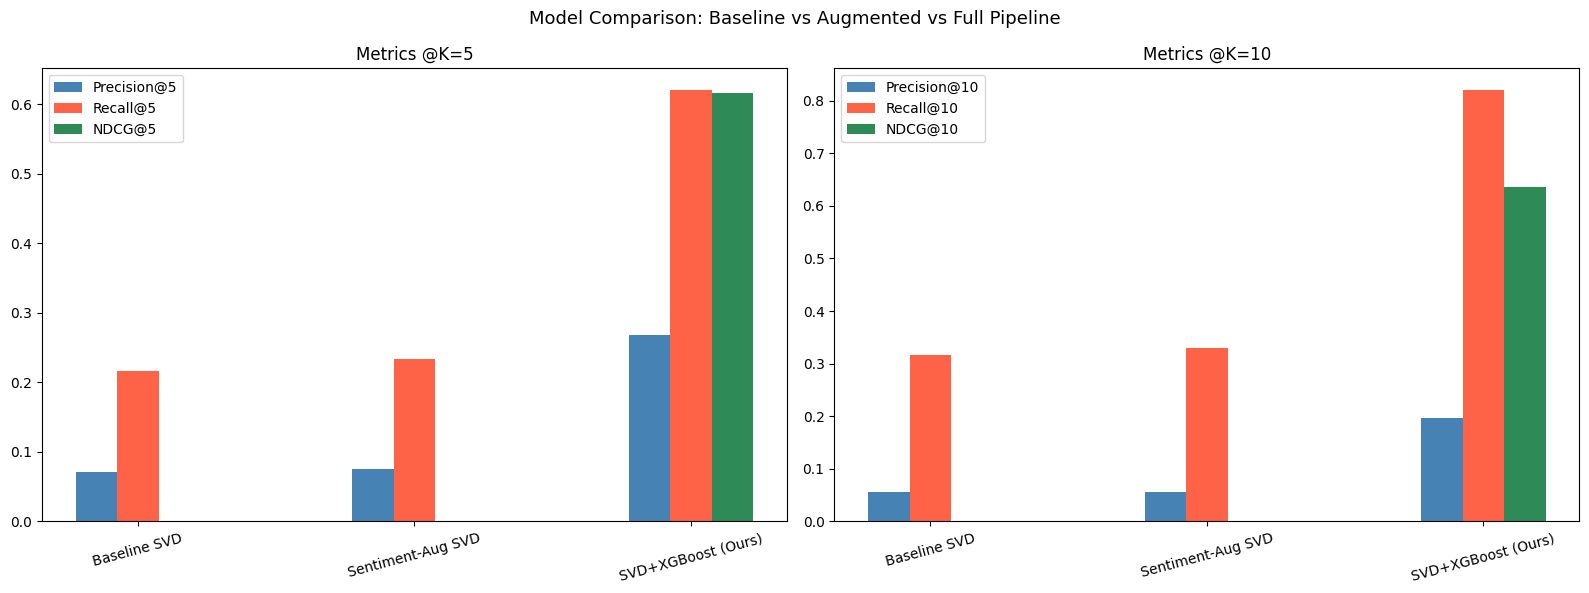

Saved: final_comparison.png


In [24]:
models    = ['Baseline SVD', 'Sentiment-Aug SVD', 'SVD+XGBoost (Ours)']
p5_vals   = [0.0713, 0.0755, pipeline_results[5]['precision']]
r5_vals   = [0.2164, 0.2340, pipeline_results[5]['recall']]
ndcg5_vals= [0.0,    0.0,    pipeline_results[5]['ndcg']]
p10_vals  = [0.0559, 0.0569, pipeline_results[10]['precision']]
r10_vals  = [0.3158, 0.3296, pipeline_results[10]['recall']]
ndcg10_vals=[0.0,    0.0,    pipeline_results[10]['ndcg']]

x  = np.arange(len(models))
w  = 0.15
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# @5 metrics
axes[0].bar(x - w,   p5_vals,    w, label='Precision@5', color='steelblue')
axes[0].bar(x,       r5_vals,    w, label='Recall@5',    color='tomato')
axes[0].bar(x + w,   ndcg5_vals, w, label='NDCG@5',      color='seagreen')
axes[0].set_title('Metrics @K=5')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=15)
axes[0].legend()

# @10 metrics
axes[1].bar(x - w,   p10_vals,    w, label='Precision@10', color='steelblue')
axes[1].bar(x,       r10_vals,    w, label='Recall@10',    color='tomato')
axes[1].bar(x + w,   ndcg10_vals, w, label='NDCG@10',      color='seagreen')
axes[1].set_title('Metrics @K=10')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=15)
axes[1].legend()

plt.suptitle('Model Comparison: Baseline vs Augmented vs Full Pipeline', fontsize=13)
plt.tight_layout()
plt.savefig('final_comparison.png', dpi=150)
plt.show()
print('Saved: final_comparison.png')

In [25]:
import pickle
import os

# Save all models
with open('/kaggle/working/svd_model.pkl', 'wb') as f:
    pickle.dump({'U': U, 'sigma': sigma, 'Vt': Vt}, f)

with open('/kaggle/working/xgb_reranker.pkl', 'wb') as f:
    pickle.dump(reranker, f)

with open('/kaggle/working/xgb_regressor.pkl', 'wb') as f:
    pickle.dump(xgb_reg, f)

with open('/kaggle/working/xgb_classifier.pkl', 'wb') as f:
    pickle.dump(xgb_cls, f)

# Save encoders too
with open('/kaggle/working/encoders.pkl', 'wb') as f:
    pickle.dump({
        'le_user':    le_u,
        'le_product': le_p,
        'le_aspect':  le_aspect,
        'le_emotion': le_emotion,
        'le_sent':    le_sent
    }, f)

print('All models saved!')
for f in os.listdir('/kaggle/working/'):
    if f.endswith('.pkl') or f.endswith('.csv') or f.endswith('.png'):
        size = os.path.getsize(f'/kaggle/working/{f}') / 1024
        print(f'  {f}: {size:.1f} KB')

All models saved!
  final_thesis_results.csv: 0.3 KB
  final_comparison.png: 75.9 KB
  xgb_regressor.pkl: 771.7 KB
  xgb_reranker.pkl: 607.5 KB
  xgboost_feature_importance.png: 43.9 KB
  xgb_classifier.pkl: 633.6 KB
  svd_model.pkl: 2257.8 KB
  encoders.pkl: 143.5 KB


In [12]:
!ls /kaggle/input/datasets/vrindabhatia108/combined-json

combined.json


In [15]:
!ls -lh /kaggle/input/datasets/vrindabhatia108/combined-json

total 763M
-rw-r--r-- 1 nobody nogroup 763M Sep 10 12:26 combined.json


In [13]:
!head -c 2000  /kaggle/input/datasets/vrindabhatia108/combined-json/combined.json

[{"main_category": "Magazine Subscriptions", "title": "Motor Trend    Print Magazine", "average_rating": 4.5, "rating_number": 2077, "features": [], "description": ["Product Description", "Filled with reviews, features, and opinions about a variety of vehicles and the larger automotive world, MotorTrend has been the world\u2019s most recognized automotive publication for more than 70 years.", "Amazon.com Review", "The first issue of MotorTrend went on sale in September 1949. More than seven decades later, the brand is recognized around the world as a leader in automotive journalism. Created by the most knowledgeable, experienced writers and tech experts, every issue of MotorTrend is filled with reviews, features, and opinions about a variety of vehicles and the larger automotive world for the car enthusiast.  From in-depth instrumented tests to first drives, MotorTrend offers something for every car-, truck- or SUV-obsessed reader. Car shoppers benefit from head-to-head vehicle compari

In [9]:
file_path = "/kaggle/input/datasets/vrindabhatia108/combined-json/combined.json"


In [2]:
!pip install -q ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 1.6 MB/s eta 0:00:00a 0:00:01


# STAGE 2 STARTS HERE

In [3]:
import ijson
import pandas as pd
import json

file_path = "/kaggle/input/datasets/vrindabhatia108/combined-json/combined.json"

output_file = "/kaggle/working/reviews_with_images.csv"

rows = []

with open(file_path, "rb") as f:
    # Each item is one product
    for product in ijson.items(f, "item"):

        asin = product.get("asin")

        for review in product.get("reviews", []):
            images = review.get("images", [])

            if images:
                rows.append({
                    "user_id": review.get("user_id"),
                    "asin": asin,
                    "rating": review.get("rating"),
                    "title": review.get("title"),
                    "text": review.get("text"),
                    "timestamp": review.get("timestamp"),
                    "images": json.dumps(images)
                })

        # Save every 10,000 image-containing reviews
        if len(rows) >= 10000:
            df = pd.DataFrame(rows)

            if not pd.io.common.file_exists(output_file):
                df.to_csv(output_file, index=False)
            else:
                df.to_csv(output_file, mode="a", header=False, index=False)

            rows = []

# Save remaining records
if rows:
    df = pd.DataFrame(rows)

    if not pd.io.common.file_exists(output_file):
        df.to_csv(output_file, index=False)
    else:
        df.to_csv(output_file, mode="a", header=False, index=False)

print("Done!")
print(output_file)

Done!
/kaggle/working/reviews_with_images.csv


In [4]:
df = pd.read_csv("/kaggle/working/reviews_with_images.csv")

print("Total reviews with images:", len(df))
display(df.head())

Total reviews with images: 31684


,user_id,asin,rating,title,text,timestamp,images
0,AF2BBWI3CF27M7UIFOBO3SNSHSZA,B01FV50Y18,1.0,Not the old motor trend,Mag sucks now.,1596494746593,"[{""small_image_url"": ""https://images-na.ssl-im..."
1,AE3MTQULT5KJCLJHVPJ4LPMMXXIQ,B0089FUF6W,5.0,"Absolutely fantastic, high end magazine for $5...",It's crazy to get this high quality magazine f...,1512075284148,"[{""small_image_url"": ""https://images-na.ssl-im..."
2,AEUDCXBTBYGUO7MJEEYV3ZGHPW2Q,B0089FUF6W,5.0,There is something beautiful to be gleaned fro...,"As an avid HGTV and DIY fan, when the magazine...",1530372072959,"[{""small_image_url"": ""https://images-na.ssl-im..."
3,AGLJUYGVOHKVDB7B5XEND6UIZUNA,B0089FUF6W,5.0,My smart wife likes it,[[VIDEOID:ceb437e1106e8431273065253952708b]] H...,1635287627054,"[{""small_image_url"": ""https://m.media-amazon.c..."
4,AFZFW3TJF6VG4K3E6LP4LPKSSJ7Q,B00BR1FSU8,5.0,More uses than you’d think!,I used this to try and get stains off my wall ...,1519680938868,"[{""small_image_url"": ""https://images-na.ssl-im..."


In [5]:
!ls /kaggle/input/datasets/vrindabhatia108/reviews-dataset

Reviews.csv


In [6]:
import pandas as pd

original_path = "/kaggle/input/datasets/vrindabhatia108/reviews-dataset/Reviews.csv"
image_path = "/kaggle/working/reviews_with_images.csv"

original = pd.read_csv(original_path)
images = pd.read_csv(image_path)

print("Original reviews:", len(original))
print("Reviews with images:", len(images))

print("\nOriginal columns:")
print(original.columns.tolist())

print("\nImage dataset columns:")
print(images.columns.tolist())

Original reviews: 568454
Reviews with images: 31684

Original columns:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

Image dataset columns:
['user_id', 'asin', 'rating', 'title', 'text', 'timestamp', 'images']


In [7]:
original = original.rename(columns={
    "UserId": "user_id",
    "ProductId": "asin",
    "Score": "rating",
    "Text": "text",
    "Summary": "title",
    "Time": "timestamp"
})

In [8]:
matched = images.merge(
    original[["user_id", "asin"]],
    on=["user_id", "asin"],
    how="inner"
)

print("User + Product matches:", len(matched))

User + Product matches: 0


In [9]:
print("Total image reviews:", len(images))

print("Complaints:", images["rating"].isin([1, 2]).sum())

print("Unique users:", images["user_id"].nunique())

print("Unique products:", images["asin"].nunique())

print("\nRating distribution:")
print(images["rating"].value_counts().sort_index())

Total image reviews: 31684
Complaints: 8210
Unique users: 30977
Unique products: 2155

Rating distribution:
rating
1.0     6155
2.0     2055
3.0     2035
4.0     3282
5.0    18157
Name: count, dtype: int64


# **Revews processing **

In [10]:
# ============================================================
# STAGE 1 — EXTRACT ALL REVIEWS FROM combined.json
# ============================================================

!pip install -q ijson

import ijson
import pandas as pd
import json
import os
from collections import Counter

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
INPUT_FILE = "/kaggle/input/datasets/vrindabhatia108/combined-json/combined.json"
OUTPUT_FILE = "/kaggle/working/all_reviews.csv"

# Remove old output if it exists
if os.path.exists(OUTPUT_FILE):
    os.remove(OUTPUT_FILE)

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

# ------------------------------------------------------------
# Extraction settings
# ------------------------------------------------------------
CHUNK_SIZE = 10000

rows = []
total_reviews = 0
image_reviews = 0
products_processed = 0

# ------------------------------------------------------------
# Read JSON incrementally
# ------------------------------------------------------------
with open(INPUT_FILE, "rb") as f:

    # Each item = one product record
    for product in ijson.items(f, "item"):

        products_processed += 1

        # Product-level identifiers
        product_asin = product.get("asin")
        product_parent_asin = product.get("parent_asin")

        reviews = product.get("reviews", [])

        for review in reviews:

            images = review.get("images", [])

            # Some records may have None instead of []
            if images is None:
                images = []

            has_image = int(len(images) > 0)

            rows.append({
                "user_id": review.get("user_id"),
                "asin": review.get("asin") or product_asin,
                "parent_asin": review.get("parent_asin") or product_parent_asin,
                "rating": review.get("rating"),
                "title": review.get("title"),
                "text": review.get("text"),
                "timestamp": review.get("timestamp"),
                "verified_purchase": review.get("verified_purchase"),
                "helpful_vote": review.get("helpful_vote"),
                "has_image": has_image,

                # Store image URLs as JSON text
                "images": json.dumps(images)
            })

            total_reviews += 1

            if has_image:
                image_reviews += 1

            # ------------------------------------------------
            # Save periodically
            # ------------------------------------------------
            if len(rows) >= CHUNK_SIZE:

                chunk_df = pd.DataFrame(rows)

                if not os.path.exists(OUTPUT_FILE):
                    chunk_df.to_csv(
                        OUTPUT_FILE,
                        index=False
                    )
                else:
                    chunk_df.to_csv(
                        OUTPUT_FILE,
                        mode="a",
                        header=False,
                        index=False
                    )

                rows = []

        # Progress
        if products_processed % 100 == 0:
            print(
                f"Products processed: {products_processed:,} | "
                f"Reviews: {total_reviews:,} | "
                f"Image reviews: {image_reviews:,}"
            )

# ------------------------------------------------------------
# Save remaining rows
# ------------------------------------------------------------
if rows:

    chunk_df = pd.DataFrame(rows)

    if not os.path.exists(OUTPUT_FILE):
        chunk_df.to_csv(
            OUTPUT_FILE,
            index=False
        )
    else:
        chunk_df.to_csv(
            OUTPUT_FILE,
            mode="a",
            header=False,
            index=False
        )

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("EXTRACTION COMPLETE")
print("=" * 60)

print(f"Products processed : {products_processed:,}")
print(f"Total reviews      : {total_reviews:,}")
print(f"Reviews with image : {image_reviews:,}")

if total_reviews > 0:
    print(
        f"Image review ratio : "
        f"{image_reviews / total_reviews * 100:.2f}%"
    )

print(f"\nSaved to:")
print(OUTPUT_FILE)

Input file: /kaggle/input/datasets/vrindabhatia108/combined-json/combined.json
Output file: /kaggle/working/all_reviews.csv
Products processed: 100 | Reviews: 25,080 | Image reviews: 724
Products processed: 200 | Reviews: 65,449 | Image reviews: 2,091
Products processed: 300 | Reviews: 112,459 | Image reviews: 2,859
Products processed: 400 | Reviews: 184,383 | Image reviews: 4,499
Products processed: 500 | Reviews: 212,323 | Image reviews: 5,107
Products processed: 600 | Reviews: 505,822 | Image reviews: 10,669
Products processed: 700 | Reviews: 582,031 | Image reviews: 12,007
Products processed: 800 | Reviews: 608,534 | Image reviews: 12,491
Products processed: 900 | Reviews: 632,151 | Image reviews: 12,990
Products processed: 1,000 | Reviews: 710,048 | Image reviews: 14,865
Products processed: 1,100 | Reviews: 773,438 | Image reviews: 16,262
Products processed: 1,200 | Reviews: 789,201 | Image reviews: 16,768
Products processed: 1,300 | Reviews: 824,016 | Image reviews: 17,214
Produc

In [11]:
# ============================================================
# STAGE 1B — DATASET INSPECTION
# ============================================================

import pandas as pd
import numpy as np

FILE = "/kaggle/working/all_reviews.csv"

df = pd.read_csv(FILE)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nRating distribution:")
display(
    df["rating"].value_counts().sort_index()
)

print("\nImage distribution:")
display(
    df["has_image"].value_counts()
)

print("\nUnique users:")
print(df["user_id"].nunique())

print("\nUnique products (ASIN):")
print(df["asin"].nunique())

print("\nUnique parent products:")
print(df["parent_asin"].nunique())

Shape: (1522895, 11)

Columns:
['user_id', 'asin', 'parent_asin', 'rating', 'title', 'text', 'timestamp', 'verified_purchase', 'helpful_vote', 'has_image', 'images']

First 5 rows:


,user_id,asin,parent_asin,rating,title,text,timestamp,verified_purchase,helpful_vote,has_image,images
0,AGVPQBKOES5MMAMYSWSFZZRIZEJA,B01FV50Y18,B01FV50Y18,5.0,THE GO-TO CAR MAGAZINE,This is literally the BEST car magazine on the...,1620369172743,True,0,0,[]
1,AFOOLPWUVW3SNGGOERKVOMZOZDRA,B01FV50Y18,B01FV50Y18,4.0,Four Stars,good,1511368642045,True,0,0,[]
2,AGXGCFOTTVBSFOTRB5V5BISL52EQ,B01FV50Y18,B01FV50Y18,4.0,Toilet reading,Keep your cell phone out of the bathroom. Just...,1673023648797,True,0,0,[]
3,AFW2D5LKIHTIEL6AB5EZCWW6GTHA,B01FV50Y18,B01FV50Y18,5.0,Great Gift for Car Lover,Renewed subscription for cousin who loves this...,1528042044433,True,1,0,[]
4,AHYDSH65ZAO5BMP5AFT4KYN7PAXQ,B01FV50Y18,B01FV50Y18,4.0,A good read but their opinions are not gospel,As in the past they do seem biased against cer...,1552933576430,True,13,0,[]



Missing values:


user_id                0
asin                   0
parent_asin            0
rating                 0
title                299
text                 334
timestamp              0
verified_purchase      0
helpful_vote           0
has_image              0
images                 0
dtype: int64


Rating distribution:


rating
1.0    154347
2.0     73559
3.0    100838
4.0    201602
5.0    992549
Name: count, dtype: int64


Image distribution:


has_image
0    1491211
1      31684
Name: count, dtype: int64


Unique users:
1371598

Unique products (ASIN):
3316

Unique parent products:
2980


In [12]:
# ============================================================
# STAGE 1C — INTERACTION DENSITY CHECK
# ============================================================

user_counts = df["user_id"].value_counts()
product_counts = df["asin"].value_counts()

print("Users with >= 1 review :", (user_counts >= 1).sum())
print("Users with >= 2 reviews :", (user_counts >= 2).sum())
print("Users with >= 3 reviews :", (user_counts >= 3).sum())
print("Users with >= 5 reviews :", (user_counts >= 5).sum())

print("\nProducts with >= 1 review :", (product_counts >= 1).sum())
print("Products with >= 2 reviews :", (product_counts >= 2).sum())
print("Products with >= 3 reviews :", (product_counts >= 3).sum())
print("Products with >= 5 reviews :", (product_counts >= 5).sum())

print("\nUser review statistics:")
display(user_counts.describe())

print("\nProduct review statistics:")
display(product_counts.describe())

Users with >= 1 review : 1371598
Users with >= 2 reviews : 121966
Users with >= 3 reviews : 20767
Users with >= 5 reviews : 1689

Products with >= 1 review : 3316
Products with >= 2 reviews : 3266
Products with >= 3 reviews : 3233
Products with >= 5 reviews : 3171

User review statistics:


count    1.371598e+06
mean     1.110307e+00
std      4.021326e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      2.100000e+01
Name: count, dtype: float64


Product review statistics:


count     3316.000000
mean       459.256634
std       1544.341541
min          1.000000
25%         46.000000
50%        174.000000
75%        398.000000
max      46721.000000
Name: count, dtype: float64

In [13]:
# ============================================================
# STAGE 1D — CHECK IMAGE COVERAGE AFTER FILTERING
# ============================================================

MIN_REVIEWS = 3

valid_users = user_counts[user_counts >= MIN_REVIEWS].index
valid_products = product_counts[product_counts >= MIN_REVIEWS].index

filtered_df = df[
    df["user_id"].isin(valid_users) &
    df["asin"].isin(valid_products)
].copy()

print("Original interactions :", len(df))
print("Filtered interactions :", len(filtered_df))

print("\nFiltered users:")
print(filtered_df["user_id"].nunique())

print("\nFiltered products:")
print(filtered_df["asin"].nunique())

print("\nFiltered image reviews:")
print(filtered_df["has_image"].sum())

print(
    "\nImage coverage after filtering: "
    f"{filtered_df['has_image'].mean() * 100:.2f}%"
)

print("\nFiltered rating distribution:")
display(
    filtered_df["rating"].value_counts().sort_index()
)

print("\nComplaint reviews (rating <= 2):")
print(
    (filtered_df["rating"] <= 2).sum()
)

print(
    "Complaint + image reviews:",
    ((filtered_df["rating"] <= 2) & (filtered_df["has_image"] == 1)).sum()
)

Original interactions : 1522895
Filtered interactions : 70860

Filtered users:
20767

Filtered products:
2815

Filtered image reviews:
1187

Image coverage after filtering: 1.68%

Filtered rating distribution:


rating
1.0     4893
2.0     3040
3.0     5308
4.0    10909
5.0    46710
Name: count, dtype: int64


Complaint reviews (rating <= 2):
7933
Complaint + image reviews: 223


# Stage 2 — prepare the actual modeling dataset

In [14]:
# ============================================================
# STAGE 2 — CLEAN & PREPARE MODELING DATASET
# ============================================================

import pandas as pd
import numpy as np
import os

INPUT_FILE = "/kaggle/working/all_reviews.csv"

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

print("Original dataset:", df.shape)

# ------------------------------------------------------------
# Basic cleaning
# ------------------------------------------------------------

# Remove rows without essential identifiers
df = df.dropna(
    subset=["user_id", "asin", "rating"]
).copy()

# Fill missing text fields
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

# Combine title + review text
df["review_text"] = (
    df["title"].str.strip() +
    " " +
    df["text"].str.strip()
).str.strip()

# Remove completely empty reviews
df = df[df["review_text"].str.len() > 0].copy()

# Ensure rating is numeric
df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

df = df[df["rating"].between(1, 5)].copy()

# ------------------------------------------------------------
# Complaint label
# ------------------------------------------------------------

df["complaint"] = (
    df["rating"] <= 2
).astype(int)

# ------------------------------------------------------------
# Ensure image flag is numeric
# ------------------------------------------------------------

df["has_image"] = (
    df["has_image"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# Convert timestamp
# ------------------------------------------------------------

df["timestamp"] = pd.to_numeric(
    df["timestamp"],
    errors="coerce"
)

df["review_date"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# ------------------------------------------------------------
# Interaction filtering
#
# Same principle as your existing implementation:
# users >= 3 reviews
# products >= 3 reviews
# ------------------------------------------------------------

user_counts = df["user_id"].value_counts()
product_counts = df["asin"].value_counts()

valid_users = user_counts[
    user_counts >= 3
].index

valid_products = product_counts[
    product_counts >= 3
].index

model_df = df[
    df["user_id"].isin(valid_users) &
    df["asin"].isin(valid_products)
].copy()

# ------------------------------------------------------------
# Sort chronologically
# ------------------------------------------------------------

model_df = model_df.sort_values(
    ["user_id", "timestamp"]
).reset_index(drop=True)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

OUTPUT_FILE = "/kaggle/working/model_reviews.csv"

model_df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODEL DATASET READY")
print("=" * 60)

print("Rows:", len(model_df))
print("Users:", model_df["user_id"].nunique())
print("Products:", model_df["asin"].nunique())

print("\nRating distribution:")
print(model_df["rating"].value_counts().sort_index())

print("\nComplaints:", model_df["complaint"].sum())

print(
    "Complaint ratio:",
    f"{model_df['complaint'].mean() * 100:.2f}%"
)

print("\nImage reviews:", model_df["has_image"].sum())

print(
    "Image coverage:",
    f"{model_df['has_image'].mean() * 100:.2f}%"
)

print(
    "Complaint + image:",
    (
        (model_df["complaint"] == 1) &
        (model_df["has_image"] == 1)
    ).sum()
)

print("\nSaved:", OUTPUT_FILE)

display(model_df.head())

Original dataset: (1522895, 11)

MODEL DATASET READY
Rows: 70854
Users: 20765
Products: 2815

Rating distribution:
rating
1.0     4893
2.0     3040
3.0     5308
4.0    10908
5.0    46705
Name: count, dtype: int64

Complaints: 7933
Complaint ratio: 11.20%

Image reviews: 1187
Image coverage: 1.68%
Complaint + image: 223

Saved: /kaggle/working/model_reviews.csv


,user_id,asin,parent_asin,rating,title,text,timestamp,verified_purchase,helpful_vote,has_image,images,review_text,complaint,review_date
0,AE22236AFRRSMQIKGG7TPTB75QEA,B000JVJ8KS,B000JVJ8KS,4.0,Great Starter Set For the Easel,The paint containers are wonderful. Having th...,1262827138000,True,0,0,[],Great Starter Set For the Easel The paint cont...,0,2010-01-07 01:18:58.000
1,AE22236AFRRSMQIKGG7TPTB75QEA,B002BS47JE,B002BS47JE,5.0,Takes Wii Fit to the next level,This game made Wii Fit so much better. Its a ...,1275247369000,False,0,0,[],Takes Wii Fit to the next level This game made...,0,2010-05-30 19:22:49.000
2,AE22236AFRRSMQIKGG7TPTB75QEA,B005CG2AX2,B005CG2AX2,4.0,Works just fine,Works great. Charges my blackberry and androi...,1344043262000,False,0,0,[],Works just fine Works great. Charges my black...,0,2012-08-04 01:21:02.000
3,AE22CLSBBG4HSSGYYN3W35FRCTCQ,B008EDVGNA,B008EDVGNA,5.0,Five Stars,perfect,1499540355516,True,0,0,[],Five Stars perfect,0,2017-07-08 18:59:15.516
4,AE22CLSBBG4HSSGYYN3W35FRCTCQ,B001B26II4,B001B26II4,5.0,Five Stars,awesome,1499540384532,True,0,0,[],Five Stars awesome,0,2017-07-08 18:59:44.532


In [16]:
# ============================================================
# STAGE 2B — IMAGE COVERAGE BY RATING
# ============================================================

image_by_rating = (
    model_df
    .groupby("rating")
    .agg(
        total_reviews=("rating", "size"),
        image_reviews=("has_image", "sum")
    )
)

image_by_rating["image_percentage"] = (
    image_by_rating["image_reviews"] /
    image_by_rating["total_reviews"] *
    100
)

display(image_by_rating)

,total_reviews,image_reviews,image_percentage
rating,,,
1.0,4893,162,3.310852
2.0,3040,61,2.006579
3.0,5308,86,1.620196
4.0,10908,181,1.659333
5.0,46705,697,1.492346


# LOAD MODEL DATA + PREPARE COMPLAINT REVIEWS

In [17]:
# ============================================================
# STAGE 3A — LOAD MODEL DATA + PREPARE COMPLAINT REVIEWS
# ============================================================

import pandas as pd
import numpy as np

MODEL_FILE = "/kaggle/working/model_reviews.csv"

model_df = pd.read_csv(MODEL_FILE)

# Make sure text is clean
model_df["review_text"] = (
    model_df["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Complaint reviews = rating 1 or 2
complaint_df = model_df[
    model_df["rating"] <= 2
].copy()

complaint_df = complaint_df.reset_index(drop=True)

print("Total modeling reviews:", len(model_df))
print("Complaint reviews:", len(complaint_df))

print("\nComplaint rating distribution:")
print(
    complaint_df["rating"]
    .value_counts()
    .sort_index()
)

print("\nAverage complaint text length:")
print(
    complaint_df["review_text"]
    .str.len()
    .describe()
)

display(
    complaint_df[
        [
            "user_id",
            "asin",
            "rating",
            "review_text",
            "has_image",
            "images"
        ]
    ].head(10)
)

Total modeling reviews: 70854
Complaint reviews: 7933

Complaint rating distribution:
rating
1.0    4893
2.0    3040
Name: count, dtype: int64

Average complaint text length:
count     7933.000000
mean       538.490231
std        762.002352
min          5.000000
25%        155.000000
50%        316.000000
75%        633.000000
max      23538.000000
Name: review_text, dtype: float64


,user_id,asin,rating,review_text,has_image,images
0,AE23U5BF4DTI7H5ZVX6L5M3U7FUQ,B004GINKNQ,2.0,They didnt tell me IF THIS GIVES YOU PROBLEMS ...,0,[]
1,AE24CHGOCJLGN5LEC4YV67YD6OZA,B00CYFFQTE,1.0,"Bad choice This a really bad product, my daugh...",0,[]
2,AE25ZDXYBK3LHKCZ7XUODANPME4A,B00BGA9X9W,1.0,NOT ACCEPTABLE In less than 3 weeks the rubber...,0,[]
3,AE25ZDXYBK3LHKCZ7XUODANPME4A,B004RMK5QG,1.0,"the moment they made ps+ mandatory, their game...",0,[]
4,AE25ZDXYBK3LHKCZ7XUODANPME4A,B00BGAA3S2,1.0,get this for what purpose? get this for what p...,0,[]
5,AE25ZDXYBK3LHKCZ7XUODANPME4A,B003O6EATE,1.0,ps vita is dead ps vita is dead. dont waste y...,0,[]
6,AE26NM3VKHQES5A7WSFQW6OZJ5QA,B00EZPXVWU,1.0,Beware of losing days on your existing subscri...,0,[]
7,AE2BPKQWQWGWM3ZF7OZGIUD4NQLA,B004VL2VRO,1.0,DO NOT BUY!! Glitchy and unreliable! We bought...,0,[]
8,AE2BZYVMULZJQTZZ2YBLS4AGJ3XA,B00GD8OKY0,2.0,not for use on anything that moves I have a fe...,0,[]
9,AE2DQVYIU5CPEL3GMHGZOGX543FA,B00EZFPDO4,1.0,Didn't last long. I purchased the titanium ver...,1,"[{""small_image_url"": ""https://images-na.ssl-im..."


# DistilBERT sentiment analysis

In [18]:
# ============================================================
# STAGE 3B — DISTILBERT SENTIMENT ANALYSIS
# ============================================================

!pip install -q transformers torch

import pandas as pd
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)

# ------------------------------------------------------------
# Load complaint data
# ------------------------------------------------------------

MODEL_FILE = "/kaggle/working/model_reviews.csv"

model_df = pd.read_csv(MODEL_FILE)

model_df["review_text"] = (
    model_df["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

complaint_df = model_df[
    model_df["rating"] <= 2
].copy()

complaint_df = complaint_df.reset_index(drop=True)

print("Complaint reviews:", len(complaint_df))


# ------------------------------------------------------------
# Check device
# ------------------------------------------------------------

if torch.cuda.is_available():
    device = 0
    print("GPU detected:", torch.cuda.get_device_name(0))
else:
    device = -1
    print("GPU not detected — using CPU")


# ------------------------------------------------------------
# Load DistilBERT sentiment model
# ------------------------------------------------------------

MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=sentiment_model,
    tokenizer=tokenizer,
    device=device,
    truncation=True,
    max_length=512
)


# ------------------------------------------------------------
# Run inference
# ------------------------------------------------------------

texts = complaint_df["review_text"].tolist()

print("\nRunning sentiment analysis...")

sentiment_results = sentiment_pipeline(
    texts,
    batch_size=32
)


# ------------------------------------------------------------
# Extract results
# ------------------------------------------------------------

complaint_df["sentiment_label"] = [
    result["label"]
    for result in sentiment_results
]

complaint_df["sentiment_score"] = [
    result["score"]
    for result in sentiment_results
]


# ------------------------------------------------------------
# Convert sentiment to numerical representation
# ------------------------------------------------------------

# POSITIVE = 1
# NEGATIVE = 0

complaint_df["sentiment_encoded"] = (
    complaint_df["sentiment_label"]
    .map({
        "POSITIVE": 1,
        "NEGATIVE": 0
    })
)


# ------------------------------------------------------------
# Inspect results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SENTIMENT RESULTS")
print("=" * 60)

print("\nSentiment distribution:")
print(
    complaint_df["sentiment_label"]
    .value_counts()
)

print("\nAverage sentiment confidence:")
print(
    complaint_df["sentiment_score"].mean()
)

display(
    complaint_df[
        [
            "rating",
            "review_text",
            "sentiment_label",
            "sentiment_score",
            "sentiment_encoded",
            "has_image"
        ]
    ].head(20)
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 34.9 MB/s eta 0:00:0000:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which 

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Running sentiment analysis...

SENTIMENT RESULTS

Sentiment distribution:
sentiment_label
NEGATIVE    7486
POSITIVE     447
Name: count, dtype: int64

Average sentiment confidence:
0.9854567580786296


,rating,review_text,sentiment_label,sentiment_score,sentiment_encoded,has_image
0,2.0,They didnt tell me IF THIS GIVES YOU PROBLEMS ...,NEGATIVE,0.999470,0,0
1,1.0,"Bad choice This a really bad product, my daugh...",NEGATIVE,0.999771,0,0
2,1.0,NOT ACCEPTABLE In less than 3 weeks the rubber...,NEGATIVE,0.999114,0,0
3,1.0,"the moment they made ps+ mandatory, their game...",NEGATIVE,0.999791,0,0
4,1.0,get this for what purpose? get this for what p...,NEGATIVE,0.999493,0,0
5,1.0,ps vita is dead ps vita is dead. dont waste y...,NEGATIVE,0.999757,0,0
6,1.0,Beware of losing days on your existing subscri...,NEGATIVE,0.995395,0,0
7,1.0,DO NOT BUY!! Glitchy and unreliable! We bought...,NEGATIVE,0.998689,0,0
8,2.0,not for use on anything that moves I have a fe...,NEGATIVE,0.998722,0,0
9,1.0,Didn't last long. I purchased the titanium ver...,NEGATIVE,0.999015,0,1


# RoBERTa EMOTION DETECTION

In [19]:
# ============================================================
# STAGE 3C — RoBERTa EMOTION DETECTION
# ============================================================

!pip install -q transformers torch

import pandas as pd
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)

# ------------------------------------------------------------
# IMPORTANT:
# complaint_df was created in Stage 3B.
# If the notebook was restarted, recreate it.
# ------------------------------------------------------------

MODEL_FILE = "/kaggle/working/model_reviews.csv"

model_df = pd.read_csv(MODEL_FILE)

model_df["review_text"] = (
    model_df["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

complaint_df = model_df[
    model_df["rating"] <= 2
].copy()

complaint_df = complaint_df.reset_index(drop=True)

print("Complaint reviews:", len(complaint_df))


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

if torch.cuda.is_available():
    device = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = -1
    print("GPU not available — using CPU")


# ------------------------------------------------------------
# Load RoBERTa emotion model
# ------------------------------------------------------------

EMOTION_MODEL = "j-hartmann/emotion-english-distilroberta-base"

emotion_tokenizer = AutoTokenizer.from_pretrained(
    EMOTION_MODEL
)

emotion_model = AutoModelForSequenceClassification.from_pretrained(
    EMOTION_MODEL
)

emotion_pipeline = pipeline(
    "text-classification",
    model=emotion_model,
    tokenizer=emotion_tokenizer,
    device=device,
    truncation=True,
    max_length=512,
    top_k=None
)


# ------------------------------------------------------------
# Run emotion inference
# ------------------------------------------------------------

texts = complaint_df["review_text"].tolist()

print("\nRunning emotion detection...")

emotion_results = emotion_pipeline(
    texts,
    batch_size=32
)


# ------------------------------------------------------------
# Extract dominant emotion + confidence
# ------------------------------------------------------------

dominant_emotions = []
emotion_scores = []

for result in emotion_results:

    # Sort by confidence
    result_sorted = sorted(
        result,
        key=lambda x: x["score"],
        reverse=True
    )

    dominant_emotions.append(
        result_sorted[0]["label"]
    )

    emotion_scores.append(
        result_sorted[0]["score"]
    )


complaint_df["emotion"] = dominant_emotions
complaint_df["emotion_score"] = emotion_scores


# ------------------------------------------------------------
# Create numerical emotion encoding
# ------------------------------------------------------------

emotion_mapping = {
    "anger": 0,
    "disgust": 1,
    "fear": 2,
    "joy": 3,
    "neutral": 4,
    "sadness": 5,
    "surprise": 6
}

complaint_df["emotion_encoded"] = (
    complaint_df["emotion"]
    .str.lower()
    .map(emotion_mapping)
)


# ------------------------------------------------------------
# Emotion distribution
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EMOTION RESULTS")
print("=" * 60)

print("\nEmotion distribution:")

emotion_distribution = (
    complaint_df["emotion"]
    .value_counts()
)

print(emotion_distribution)


print("\nEmotion percentages:")

emotion_percentage = (
    complaint_df["emotion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(emotion_percentage)


print("\nAverage emotion confidence:")

print(
    complaint_df["emotion_score"].mean()
)


# ------------------------------------------------------------
# Display examples
# ------------------------------------------------------------

display(
    complaint_df[
        [
            "rating",
            "review_text",
            "emotion",
            "emotion_score",
            "has_image"
        ]
    ].head(20)
)

Complaint reviews: 7933
GPU: Tesla T4


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Running emotion detection...


model.safetensors:   0%|          | 0.00/329M [00:00<?, ?B/s]


EMOTION RESULTS

Emotion distribution:
emotion
neutral     2767
sadness     2319
disgust     1129
surprise     843
anger        471
fear         323
joy           81
Name: count, dtype: int64

Emotion percentages:
emotion
neutral     34.88
sadness     29.23
disgust     14.23
surprise    10.63
anger        5.94
fear         4.07
joy          1.02
Name: proportion, dtype: float64

Average emotion confidence:
0.6222486029195107


,rating,review_text,emotion,emotion_score,has_image
0,2.0,They didnt tell me IF THIS GIVES YOU PROBLEMS ...,sadness,0.940559,0
1,1.0,"Bad choice This a really bad product, my daugh...",sadness,0.755629,0
2,1.0,NOT ACCEPTABLE In less than 3 weeks the rubber...,sadness,0.529173,0
3,1.0,"the moment they made ps+ mandatory, their game...",neutral,0.362274,0
4,1.0,get this for what purpose? get this for what p...,surprise,0.572823,0
5,1.0,ps vita is dead ps vita is dead. dont waste y...,sadness,0.682121,0
6,1.0,Beware of losing days on your existing subscri...,fear,0.401322,0
7,1.0,DO NOT BUY!! Glitchy and unreliable! We bought...,surprise,0.771906,0
8,2.0,not for use on anything that moves I have a fe...,neutral,0.722594,0
9,1.0,Didn't last long. I purchased the titanium ver...,disgust,0.376081,1


# emotion distribution

In [20]:
# ============================================================
# STAGE 3C-B — EMOTION DISTRIBUTION:
# IMAGE VS NON-IMAGE COMPLAINTS
# ============================================================

emotion_image_comparison = (
    complaint_df
    .groupby(["has_image", "emotion"])
    .size()
    .unstack(fill_value=0)
)

print("0 = No image")
print("1 = Image available\n")

display(emotion_image_comparison)

0 = No image
1 = Image available



emotion,anger,disgust,fear,joy,neutral,sadness,surprise
has_image,,,,,,,
0,463,1094,318,79,2674,2256,826
1,8,35,5,2,93,63,17


# Percentage Distribution

In [21]:
# Percentage distribution within each group

emotion_image_percentage = (
    pd.crosstab(
        complaint_df["has_image"],
        complaint_df["emotion"],
        normalize="index"
    ) * 100
)

display(
    emotion_image_percentage.round(2)
)

emotion,anger,disgust,fear,joy,neutral,sadness,surprise
has_image,,,,,,,
0,6.01,14.19,4.12,1.02,34.68,29.26,10.71
1,3.59,15.70,2.24,0.90,41.70,28.25,7.62


# ABSA- ASPECT BASED COMPLAINT ANALYSIS

In [22]:
# ============================================================
# STAGE 3D — ASPECT-BASED COMPLAINT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# Recreate complaint_df with the previous model outputs
# ------------------------------------------------------------
# If complaint_df is still in memory from Stage 3C,
# this section simply uses it.
# Otherwise, recreate the basic dataframe.

if "complaint_df" not in globals():

    MODEL_FILE = "/kaggle/working/model_reviews.csv"

    model_df = pd.read_csv(MODEL_FILE)

    model_df["review_text"] = (
        model_df["review_text"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    complaint_df = model_df[
        model_df["rating"] <= 2
    ].copy()

    complaint_df = complaint_df.reset_index(drop=True)


# ------------------------------------------------------------
# Aspect keyword dictionaries
# ------------------------------------------------------------

aspect_keywords = {

    "product_quality": [
        "quality",
        "poor quality",
        "bad quality",
        "cheap",
        "defective",
        "defect",
        "broken",
        "broke",
        "damaged",
        "damage",
        "faulty",
        "flimsy",
        "stopped working",
        "doesn't work",
        "does not work",
        "didn't work",
        "did not work",
        "not working",
        "malfunction",
        "failure",
        "failed",
        "terrible product",
        "poor product",
        "waste of money"
    ],

    "price": [
        "price",
        "priced",
        "expensive",
        "cost",
        "costly",
        "overpriced",
        "cheap",
        "value",
        "worth",
        "money",
        "refund",
        "refunds",
        "rip off",
        "ripoff"
    ],

    "delivery": [
        "delivery",
        "delivered",
        "shipping",
        "shipped",
        "shipment",
        "arrived",
        "arrival",
        "late",
        "delay",
        "delayed",
        "package never arrived",
        "didn't arrive",
        "did not arrive",
        "lost package",
        "carrier",
        "courier"
    ],

    "packaging": [
        "package",
        "packaging",
        "box",
        "boxed",
        "包装",
        "sealed",
        "seal",
        "wrapper",
        "wrapping",
        "container",
        "leaking",
        "leaked",
        "crushed",
        "pack",
        "packing"
    ],

    "usability": [
        "use",
        "using",
        "easy to use",
        "hard to use",
        "difficult to use",
        "complicated",
        "confusing",
        "instructions",
        "instruction",
        "install",
        "installation",
        "setup",
        "set up",
        "works",
        "working",
        "operate",
        "operation",
        "function",
        "feature",
        "design",
        "interface",
        "slow",
        "unreliable",
        "glitch",
        "glitchy"
    ],

    "customer_service": [
        "customer service",
        "customer support",
        "support",
        "seller",
        "seller support",
        "service",
        "representative",
        "agent",
        "response",
        "responded",
        "contact",
        "contacted",
        "replacement",
        "replace",
        "return",
        "returned",
        "refund",
        "complaint"
    ]
}


# ------------------------------------------------------------
# Compile regex patterns
# ------------------------------------------------------------

aspect_patterns = {}

for aspect, keywords in aspect_keywords.items():

    escaped_keywords = [
        re.escape(keyword.lower())
        for keyword in keywords
    ]

    aspect_patterns[aspect] = re.compile(
        r"\b(?:"
        + "|".join(escaped_keywords)
        + r")\b",
        flags=re.IGNORECASE
    )


# ------------------------------------------------------------
# Detect aspects
# ------------------------------------------------------------

def detect_aspects(text):

    text = str(text).lower()

    detected = []

    for aspect, pattern in aspect_patterns.items():

        if pattern.search(text):
            detected.append(aspect)

    return detected


complaint_df["detected_aspects"] = (
    complaint_df["review_text"]
    .apply(detect_aspects)
)


# ------------------------------------------------------------
# Primary aspect
# ------------------------------------------------------------

def get_primary_aspect(aspects):

    if not aspects:
        return "other"

    return aspects[0]


complaint_df["primary_aspect"] = (
    complaint_df["detected_aspects"]
    .apply(get_primary_aspect)
)


# ------------------------------------------------------------
# Number of detected aspects
# ------------------------------------------------------------

complaint_df["aspect_count"] = (
    complaint_df["detected_aspects"]
    .apply(len)
)


# ------------------------------------------------------------
# Multi-aspect flag
# ------------------------------------------------------------

complaint_df["multi_aspect"] = (
    complaint_df["aspect_count"] > 1
).astype(int)


# ------------------------------------------------------------
# Aspect encoded
# ------------------------------------------------------------

aspect_mapping = {
    "product_quality": 0,
    "price": 1,
    "delivery": 2,
    "packaging": 3,
    "usability": 4,
    "customer_service": 5,
    "other": 6
}

complaint_df["aspect_encoded"] = (
    complaint_df["primary_aspect"]
    .map(aspect_mapping)
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ASPECT ANALYSIS RESULTS")
print("=" * 60)

print("\nPrimary aspect distribution:")

aspect_distribution = (
    complaint_df["primary_aspect"]
    .value_counts()
)

print(aspect_distribution)


print("\nPrimary aspect percentages:")

aspect_percentage = (
    complaint_df["primary_aspect"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(aspect_percentage)


print("\nReviews containing multiple aspects:")

print(
    complaint_df["multi_aspect"].sum()
)


print(
    "Multi-aspect percentage:",
    f"{complaint_df['multi_aspect'].mean() * 100:.2f}%"
)


# ------------------------------------------------------------
# Examples
# ------------------------------------------------------------

display(
    complaint_df[
        [
            "rating",
            "review_text",
            "detected_aspects",
            "primary_aspect",
            "aspect_count",
            "has_image"
        ]
    ].head(30)
)


ASPECT ANALYSIS RESULTS

Primary aspect distribution:
primary_aspect
product_quality     2717
other               2023
usability           1330
price               1066
customer_service     332
packaging            281
delivery             184
Name: count, dtype: int64

Primary aspect percentages:
primary_aspect
product_quality     34.25
other               25.50
usability           16.77
price               13.44
customer_service     4.19
packaging            3.54
delivery             2.32
Name: proportion, dtype: float64

Reviews containing multiple aspects:
3465
Multi-aspect percentage: 43.68%


,rating,review_text,detected_aspects,primary_aspect,aspect_count,has_image
0,2.0,They didnt tell me IF THIS GIVES YOU PROBLEMS ...,[],other,0,0
1,1.0,"Bad choice This a really bad product, my daugh...","[price, usability]",price,2,0
2,1.0,NOT ACCEPTABLE In less than 3 weeks the rubber...,"[product_quality, usability]",product_quality,2,0
3,1.0,"the moment they made ps+ mandatory, their game...",[product_quality],product_quality,1,0
4,1.0,get this for what purpose? get this for what p...,[price],price,1,0
5,1.0,ps vita is dead ps vita is dead. dont waste y...,"[price, customer_service]",price,2,0
6,1.0,Beware of losing days on your existing subscri...,[price],price,1,0
7,1.0,DO NOT BUY!! Glitchy and unreliable! We bought...,"[product_quality, delivery, usability, custome...",product_quality,4,0
8,2.0,not for use on anything that moves I have a fe...,"[product_quality, price, usability]",product_quality,3,0
9,1.0,Didn't last long. I purchased the titanium ver...,"[product_quality, price, usability, customer_s...",product_quality,4,1


# COMPARISON

In [23]:
# ============================================================
# STAGE 3D-B — ASPECT DISTRIBUTION:
# IMAGE VS NON-IMAGE COMPLAINTS
# ============================================================

aspect_image_comparison = pd.crosstab(
    complaint_df["has_image"],
    complaint_df["primary_aspect"],
    normalize="index"
) * 100

print("Percentage distribution of complaint aspects")
print("0 = No image | 1 = Image available\n")

display(
    aspect_image_comparison.round(2)
)

Percentage distribution of complaint aspects
0 = No image | 1 = Image available



primary_aspect,customer_service,delivery,other,packaging,price,product_quality,usability
has_image,,,,,,,
0,4.16,2.28,25.56,3.42,13.58,34.15,16.84
1,4.93,3.59,23.32,7.62,8.52,37.67,14.35


In [24]:
aspect_image_counts = pd.crosstab(
    complaint_df["has_image"],
    complaint_df["primary_aspect"]
)

display(aspect_image_counts)

primary_aspect,customer_service,delivery,other,packaging,price,product_quality,usability
has_image,,,,,,,
0,321,176,1971,264,1047,2633,1298
1,11,8,52,17,19,84,32


# COMPLAINT INTENSITY

In [25]:
# ============================================================
# STAGE 3E — COMPLAINT INTENSITY
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Make sure sentiment/emotion columns exist
# ------------------------------------------------------------

required_columns = [
    "sentiment_score",
    "sentiment_encoded",
    "emotion",
    "emotion_score",
    "primary_aspect",
    "aspect_count"
]

missing = [
    col for col in required_columns
    if col not in complaint_df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Please run Stages 3B–3D first."
    )

# ------------------------------------------------------------
# 1. Rating severity
# ------------------------------------------------------------
# Rating 1 -> 1.00
# Rating 2 -> 0.50

complaint_df["rating_severity"] = (
    (3 - complaint_df["rating"]) / 2
)

complaint_df["rating_severity"] = (
    complaint_df["rating_severity"]
    .clip(0, 1)
)


# ------------------------------------------------------------
# 2. Sentiment negativity
# ------------------------------------------------------------
# For NEGATIVE:
# confidence directly represents negativity.
#
# For POSITIVE:
# confidence is inverted because this is a complaint
# despite the model predicting positive sentiment.

complaint_df["sentiment_negativity"] = np.where(
    complaint_df["sentiment_label"] == "NEGATIVE",
    complaint_df["sentiment_score"],
    1 - complaint_df["sentiment_score"]
)


# ------------------------------------------------------------
# 3. Emotion weighting
# ------------------------------------------------------------
# Strong complaint-related emotions receive greater weight.
#
# These weights follow the logic used in your previous
# implementation.

strong_negative_emotions = {
    "anger",
    "disgust",
    "fear",
    "sadness"
}

complaint_df["emotion_weight"] = np.where(
    complaint_df["emotion"].str.lower().isin(
        strong_negative_emotions
    ),
    1.2,
    0.8
)

complaint_df["weighted_emotion_score"] = (
    complaint_df["emotion_score"] *
    complaint_df["emotion_weight"]
).clip(0, 1)


# ------------------------------------------------------------
# 4. Aspect contribution
# ------------------------------------------------------------
# Multiple complaint aspects indicate a broader complaint.

complaint_df["aspect_contribution"] = (
    complaint_df["aspect_count"]
    .clip(0, 4) / 4
)


# ------------------------------------------------------------
# 5. Final complaint intensity
# ------------------------------------------------------------
#
# Rating severity       = 40%
# Sentiment negativity  = 30%
# Emotion               = 20%
# Aspect breadth        = 10%
#

complaint_df["complaint_intensity"] = (
    0.40 * complaint_df["rating_severity"] +
    0.30 * complaint_df["sentiment_negativity"] +
    0.20 * complaint_df["weighted_emotion_score"] +
    0.10 * complaint_df["aspect_contribution"]
)

complaint_df["complaint_intensity"] = (
    complaint_df["complaint_intensity"]
    .clip(0, 1)
)


# ------------------------------------------------------------
# Intensity categories
# ------------------------------------------------------------

def intensity_category(score):

    if score < 0.33:
        return "Low"

    elif score < 0.66:
        return "Medium"

    else:
        return "High"


complaint_df["intensity_category"] = (
    complaint_df["complaint_intensity"]
    .apply(intensity_category)
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPLAINT INTENSITY RESULTS")
print("=" * 60)

print("\nIntensity statistics:")

display(
    complaint_df["complaint_intensity"]
    .describe()
)


print("\nIntensity category distribution:")

display(
    complaint_df["intensity_category"]
    .value_counts()
)


print("\nIntensity category percentages:")

display(
    complaint_df["intensity_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ------------------------------------------------------------
# Compare intensity by rating
# ------------------------------------------------------------

print("\nAverage intensity by rating:")

display(
    complaint_df
    .groupby("rating")["complaint_intensity"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)


# ------------------------------------------------------------
# Compare image vs non-image complaints
# ------------------------------------------------------------

print("\nAverage intensity — image vs non-image:")

display(
    complaint_df
    .groupby("has_image")["complaint_intensity"]
    .agg(["count", "mean", "std"])
    .round(3)
)


# ------------------------------------------------------------
# Example records
# ------------------------------------------------------------

display(
    complaint_df[
        [
            "rating",
            "review_text",
            "sentiment_label",
            "sentiment_score",
            "emotion",
            "emotion_score",
            "primary_aspect",
            "aspect_count",
            "has_image",
            "complaint_intensity",
            "intensity_category"
        ]
    ].head(20)
)

ValueError: Missing columns: ['sentiment_score', 'sentiment_encoded']. Please run Stages 3B–3D first.

In [26]:
# ============================================================
# STAGE 3B — DISTILBERT SENTIMENT + SAVE
# ============================================================

import pandas as pd
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)

MODEL_FILE = "/kaggle/working/model_reviews.csv"
OUTPUT_FILE = "/kaggle/working/complaints_sentiment.csv"

model_df = pd.read_csv(MODEL_FILE)

model_df["review_text"] = (
    model_df["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

complaint_df = model_df[
    model_df["rating"] <= 2
].copy().reset_index(drop=True)

print("Complaint reviews:", len(complaint_df))

# Device
device = 0 if torch.cuda.is_available() else -1

if device == 0:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

# Model
MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
)

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=sentiment_model,
    tokenizer=tokenizer,
    device=device,
    truncation=True,
    max_length=512
)

# Inference
texts = complaint_df["review_text"].tolist()

print("Running sentiment analysis...")

results = sentiment_pipeline(
    texts,
    batch_size=32
)

# Features
complaint_df["sentiment_label"] = [
    r["label"] for r in results
]

complaint_df["sentiment_score"] = [
    r["score"] for r in results
]

complaint_df["sentiment_encoded"] = (
    complaint_df["sentiment_label"]
    .map({
        "POSITIVE": 1,
        "NEGATIVE": 0
    })
)

# Save
complaint_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\n" + "=" * 60)
print("SENTIMENT SAVED")
print("=" * 60)

print("Rows:", len(complaint_df))
print("\nSentiment distribution:")
print(complaint_df["sentiment_label"].value_counts())

print("\nSaved to:")
print(OUTPUT_FILE)

Complaint reviews: 7933
GPU: Tesla T4


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Running sentiment analysis...

SENTIMENT SAVED
Rows: 7933

Sentiment distribution:
sentiment_label
NEGATIVE    7486
POSITIVE     447
Name: count, dtype: int64

Saved to:
/kaggle/working/complaints_sentiment.csv


In [27]:
# ============================================================
# STAGE 3C — RoBERTa EMOTION DETECTION + SAVE
# ============================================================

import pandas as pd
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)

INPUT_FILE = "/kaggle/working/complaints_sentiment.csv"
OUTPUT_FILE = "/kaggle/working/complaints_text_features.csv"

# ------------------------------------------------------------
# Load sentiment results
# ------------------------------------------------------------

complaint_df = pd.read_csv(INPUT_FILE)

print("Loaded:", complaint_df.shape)
print("Complaint reviews:", len(complaint_df))

# Check sentiment columns
print(
    "\nSentiment columns present:",
    all(
        col in complaint_df.columns
        for col in [
            "sentiment_label",
            "sentiment_score",
            "sentiment_encoded"
        ]
    )
)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = 0 if torch.cuda.is_available() else -1

if device == 0:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

# ------------------------------------------------------------
# Load emotion model
# ------------------------------------------------------------

EMOTION_MODEL = "j-hartmann/emotion-english-distilroberta-base"

emotion_tokenizer = AutoTokenizer.from_pretrained(
    EMOTION_MODEL
)

emotion_model = AutoModelForSequenceClassification.from_pretrained(
    EMOTION_MODEL
)

emotion_pipeline = pipeline(
    "text-classification",
    model=emotion_model,
    tokenizer=emotion_tokenizer,
    device=device,
    truncation=True,
    max_length=512,
    top_k=None
)

# ------------------------------------------------------------
# Prepare text
# ------------------------------------------------------------

texts = (
    complaint_df["review_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

# ------------------------------------------------------------
# Run inference
# ------------------------------------------------------------

print("\nRunning emotion detection...")

emotion_results = emotion_pipeline(
    texts,
    batch_size=32
)

# ------------------------------------------------------------
# Extract dominant emotion
# ------------------------------------------------------------

dominant_emotions = []
emotion_scores = []

for result in emotion_results:

    result_sorted = sorted(
        result,
        key=lambda x: x["score"],
        reverse=True
    )

    dominant_emotions.append(
        result_sorted[0]["label"].lower()
    )

    emotion_scores.append(
        result_sorted[0]["score"]
    )

complaint_df["emotion"] = dominant_emotions
complaint_df["emotion_score"] = emotion_scores

# ------------------------------------------------------------
# Numerical encoding
# ------------------------------------------------------------

emotion_mapping = {
    "anger": 0,
    "disgust": 1,
    "fear": 2,
    "joy": 3,
    "neutral": 4,
    "sadness": 5,
    "surprise": 6
}

complaint_df["emotion_encoded"] = (
    complaint_df["emotion"]
    .map(emotion_mapping)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

complaint_df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EMOTION FEATURES SAVED")
print("=" * 60)

print("\nEmotion distribution:")
print(
    complaint_df["emotion"]
    .value_counts()
)

print("\nEmotion percentages:")
print(
    complaint_df["emotion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAverage emotion confidence:")
print(
    complaint_df["emotion_score"].mean()
)

print("\nSaved to:")
print(OUTPUT_FILE)

Loaded: (7933, 17)
Complaint reviews: 7933

Sentiment columns present: True
GPU: Tesla T4


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Running emotion detection...

EMOTION FEATURES SAVED

Emotion distribution:
emotion
neutral     2767
sadness     2319
disgust     1129
surprise     843
anger        471
fear         323
joy           81
Name: count, dtype: int64

Emotion percentages:
emotion
neutral     34.88
sadness     29.23
disgust     14.23
surprise    10.63
anger        5.94
fear         4.07
joy          1.02
Name: proportion, dtype: float64

Average emotion confidence:
0.6222486029195107

Saved to:
/kaggle/working/complaints_text_features.csv


In [28]:
# ============================================================
# STAGE 3D — ASPECT-BASED COMPLAINT ANALYSIS + SAVE
# ============================================================

import pandas as pd
import numpy as np
import re

INPUT_FILE = "/kaggle/working/complaints_text_features.csv"
OUTPUT_FILE = "/kaggle/working/complaints_text_features_aspects.csv"

# ------------------------------------------------------------
# Load saved sentiment + emotion features
# ------------------------------------------------------------

complaint_df = pd.read_csv(INPUT_FILE)

print("Loaded:", complaint_df.shape)

# Verify previous features survived
required_columns = [
    "sentiment_label",
    "sentiment_score",
    "sentiment_encoded",
    "emotion",
    "emotion_score",
    "emotion_encoded"
]

missing = [
    col for col in required_columns
    if col not in complaint_df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

print("Sentiment + emotion features confirmed.")


# ------------------------------------------------------------
# Aspect keyword dictionaries
# ------------------------------------------------------------

aspect_keywords = {

    "product_quality": [
        "quality",
        "poor quality",
        "bad quality",
        "cheap",
        "defective",
        "defect",
        "broken",
        "broke",
        "damaged",
        "damage",
        "faulty",
        "flimsy",
        "stopped working",
        "doesn't work",
        "does not work",
        "didn't work",
        "did not work",
        "not working",
        "malfunction",
        "failure",
        "failed",
        "terrible product",
        "poor product",
        "waste of money"
    ],

    "price": [
        "price",
        "priced",
        "expensive",
        "cost",
        "costly",
        "overpriced",
        "cheap",
        "value",
        "worth",
        "money",
        "refund",
        "refunds",
        "rip off",
        "ripoff"
    ],

    "delivery": [
        "delivery",
        "delivered",
        "shipping",
        "shipped",
        "shipment",
        "arrived",
        "arrival",
        "late",
        "delay",
        "delayed",
        "package never arrived",
        "didn't arrive",
        "did not arrive",
        "lost package",
        "carrier",
        "courier"
    ],

    "packaging": [
        "package",
        "packaging",
        "box",
        "boxed",
        "sealed",
        "seal",
        "wrapper",
        "wrapping",
        "container",
        "leaking",
        "leaked",
        "crushed",
        "packing"
    ],

    "usability": [
        "use",
        "using",
        "easy to use",
        "hard to use",
        "difficult to use",
        "complicated",
        "confusing",
        "instructions",
        "instruction",
        "install",
        "installation",
        "setup",
        "set up",
        "works",
        "working",
        "operate",
        "operation",
        "function",
        "feature",
        "design",
        "interface",
        "slow",
        "unreliable",
        "glitch",
        "glitchy"
    ],

    "customer_service": [
        "customer service",
        "customer support",
        "support",
        "seller",
        "seller support",
        "service",
        "representative",
        "agent",
        "response",
        "responded",
        "contact",
        "contacted",
        "replacement",
        "replace",
        "return",
        "returned",
        "refund",
        "complaint"
    ]
}


# ------------------------------------------------------------
# Create regex patterns
# ------------------------------------------------------------

aspect_patterns = {}

for aspect, keywords in aspect_keywords.items():

    escaped = [
        re.escape(keyword.lower())
        for keyword in keywords
    ]

    aspect_patterns[aspect] = re.compile(
        r"\b(?:" + "|".join(escaped) + r")\b",
        flags=re.IGNORECASE
    )


# ------------------------------------------------------------
# Detect all applicable aspects
# ------------------------------------------------------------

def detect_aspects(text):

    text = str(text).lower()

    detected = []

    for aspect, pattern in aspect_patterns.items():

        if pattern.search(text):
            detected.append(aspect)

    return detected


complaint_df["detected_aspects"] = (
    complaint_df["review_text"]
    .apply(detect_aspects)
)


# ------------------------------------------------------------
# Primary aspect
# ------------------------------------------------------------

def get_primary_aspect(aspects):

    if len(aspects) == 0:
        return "other"

    return aspects[0]


complaint_df["primary_aspect"] = (
    complaint_df["detected_aspects"]
    .apply(get_primary_aspect)
)


# ------------------------------------------------------------
# Aspect count
# ------------------------------------------------------------

complaint_df["aspect_count"] = (
    complaint_df["detected_aspects"]
    .apply(len)
)


# ------------------------------------------------------------
# Multi-aspect flag
# ------------------------------------------------------------

complaint_df["multi_aspect"] = (
    complaint_df["aspect_count"] > 1
).astype(int)


# ------------------------------------------------------------
# Numerical encoding
# ------------------------------------------------------------

aspect_mapping = {
    "product_quality": 0,
    "price": 1,
    "delivery": 2,
    "packaging": 3,
    "usability": 4,
    "customer_service": 5,
    "other": 6
}

complaint_df["aspect_encoded"] = (
    complaint_df["primary_aspect"]
    .map(aspect_mapping)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

complaint_df.to_csv(
    OUTPUT_FILE,
    index=False
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ASPECT FEATURES SAVED")
print("=" * 60)

print("\nPrimary aspect distribution:")
print(
    complaint_df["primary_aspect"]
    .value_counts()
)

print("\nMulti-aspect reviews:")
print(
    complaint_df["multi_aspect"].sum()
)

print(
    "Multi-aspect percentage:",
    f"{complaint_df['multi_aspect'].mean() * 100:.2f}%"
)

print("\nSaved to:")
print(OUTPUT_FILE)

Loaded: (7933, 20)
Sentiment + emotion features confirmed.

ASPECT FEATURES SAVED

Primary aspect distribution:
primary_aspect
product_quality     2717
other               2034
usability           1338
price               1066
customer_service     332
packaging            262
delivery             184
Name: count, dtype: int64

Multi-aspect reviews:
3452
Multi-aspect percentage: 43.51%

Saved to:
/kaggle/working/complaints_text_features_aspects.csv


In [31]:
# ============================================================
# STAGE 3D-B — VERIFY COMPLETE TEXT FEATURE SET
# ============================================================

feature_check = [
    "sentiment_label",
    "sentiment_score",
    "sentiment_encoded",
    "emotion",
    "emotion_score",
    "emotion_encoded",
    "detected_aspects",
    "primary_aspect",
    "aspect_count",
    "multi_aspect",
    "aspect_encoded"
]

for col in feature_check:
    print(
        f"{col:25s} : "
        f"{'OK' if col in complaint_df.columns else 'MISSING'}"
    )

sentiment_label           : OK
sentiment_score           : OK
sentiment_encoded         : OK
emotion                   : OK
emotion_score             : OK
emotion_encoded           : OK
detected_aspects          : OK
primary_aspect            : OK
aspect_count              : OK
multi_aspect              : OK
aspect_encoded            : OK


In [34]:
# ============================================================
# STAGE 3E — COMPLAINT INTENSITY + SAVE
# ============================================================

import pandas as pd
import numpy as np

INPUT_FILE = "/kaggle/working/complaints_text_features_aspects.csv"
OUTPUT_FILE = "/kaggle/working/final_complaint_text_features.csv"

# ------------------------------------------------------------
# Load complete text feature set
# ------------------------------------------------------------

complaint_df = pd.read_csv(INPUT_FILE)

print("Loaded:", complaint_df.shape)

# ------------------------------------------------------------
# Verify required columns
# ------------------------------------------------------------

required_columns = [
    "rating",
    "sentiment_label",
    "sentiment_score",
    "emotion",
    "emotion_score",
    "aspect_count"
]

missing = [
    col for col in required_columns
    if col not in complaint_df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# ------------------------------------------------------------
# 1. Rating severity
# ------------------------------------------------------------
# 1-star -> 1.0
# 2-star -> 0.5

complaint_df["rating_severity"] = (
    (3 - complaint_df["rating"]) / 2
).clip(0, 1)

# ------------------------------------------------------------
# 2. Sentiment negativity
# ------------------------------------------------------------
#
# Negative prediction:
#     confidence = negativity
#
# Positive prediction:
#     1 - confidence = negativity
#
# This is useful because some 1–2 star reviews were classified
# as POSITIVE by DistilBERT.
# ------------------------------------------------------------

complaint_df["sentiment_negativity"] = np.where(
    complaint_df["sentiment_label"] == "NEGATIVE",
    complaint_df["sentiment_score"],
    1 - complaint_df["sentiment_score"]
)

# ------------------------------------------------------------
# 3. Emotion weighting
# ------------------------------------------------------------

strong_negative_emotions = {
    "anger",
    "disgust",
    "fear",
    "sadness"
}

complaint_df["emotion_weight"] = np.where(
    complaint_df["emotion"].str.lower().isin(
        strong_negative_emotions
    ),
    1.2,
    0.8
)

complaint_df["weighted_emotion_score"] = (
    complaint_df["emotion_score"] *
    complaint_df["emotion_weight"]
).clip(0, 1)

# ------------------------------------------------------------
# 4. Aspect breadth
# ------------------------------------------------------------
#
# Cap at 4 aspects so that a review containing many matched
# keywords does not dominate the intensity score.
# ------------------------------------------------------------

complaint_df["aspect_contribution"] = (
    complaint_df["aspect_count"]
    .clip(0, 4) / 4
)

# ------------------------------------------------------------
# 5. Final complaint intensity
# ------------------------------------------------------------
#
# Rating severity       40%
# Sentiment negativity  30%
# Emotion                20%
# Aspect breadth         10%
# ------------------------------------------------------------

complaint_df["complaint_intensity"] = (
    0.40 * complaint_df["rating_severity"] +
    0.30 * complaint_df["sentiment_negativity"] +
    0.20 * complaint_df["weighted_emotion_score"] +
    0.10 * complaint_df["aspect_contribution"]
).clip(0, 1)

# ------------------------------------------------------------
# 6. Intensity category
# ------------------------------------------------------------

def classify_intensity(score):

    if score < 0.33:
        return "Low"
    elif score < 0.66:
        return "Medium"
    else:
        return "High"


complaint_df["intensity_category"] = (
    complaint_df["complaint_intensity"]
    .apply(classify_intensity)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

complaint_df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPLAINT INTENSITY COMPLETE")
print("=" * 60)

print("\nIntensity statistics:")

display(
    complaint_df["complaint_intensity"]
    .describe()
    .round(4)
)

print("\nIntensity categories:")

display(
    complaint_df["intensity_category"]
    .value_counts()
)

print("\nIntensity percentages:")

display(
    complaint_df["intensity_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAverage intensity by rating:")

display(
    complaint_df
    .groupby("rating")["complaint_intensity"]
    .agg(["count", "mean", "std"])
    .round(4)
)

print("\nAverage intensity by image availability:")

display(
    complaint_df
    .groupby("has_image")["complaint_intensity"]
    .agg(["count", "mean", "std"])
    .round(4)
)

print("\nSaved to:")
print(OUTPUT_FILE)

Loaded: (7933, 25)

COMPLAINT INTENSITY COMPLETE

Intensity statistics:


count    7933.0000
mean        0.7666
std         0.1368
min         0.2573
25%         0.6593
50%         0.8064
75%         0.8724
max         0.9999
Name: complaint_intensity, dtype: float64


Intensity categories:


intensity_category
High      5929
Medium    1934
Low         70
Name: count, dtype: int64


Intensity percentages:


...


Average intensity by rating:


,count,mean,std
rating,,,
1.0,4893,0.8522,0.0745
2.0,3040,0.6288,0.0955



Average intensity by image availability:


,count,mean,std
has_image,,,
0,7710,0.7655,0.1372
1,223,0.8032,0.1176



Saved to:
/kaggle/working/final_complaint_text_features.csv


In [35]:
# ============================================================
# STAGE 3E-B — TEXT FEATURE SUMMARY
# ============================================================

print("TEXT COMPLAINT FEATURE SUMMARY")
print("=" * 60)

summary = {
    "Complaint reviews": len(complaint_df),
    "1-star complaints": int((complaint_df["rating"] == 1).sum()),
    "2-star complaints": int((complaint_df["rating"] == 2).sum()),
    "Negative sentiment": int(
        (complaint_df["sentiment_label"] == "NEGATIVE").sum()
    ),
    "Positive sentiment": int(
        (complaint_df["sentiment_label"] == "POSITIVE").sum()
    ),
    "Image complaints": int(
        complaint_df["has_image"].sum()
    ),
    "Multi-aspect complaints": int(
        complaint_df["multi_aspect"].sum()
    ),
    "Mean intensity": round(
        complaint_df["complaint_intensity"].mean(), 4
    )
}

for key, value in summary.items():
    print(f"{key:25s}: {value}")

TEXT COMPLAINT FEATURE SUMMARY
Complaint reviews        : 7933
1-star complaints        : 4893
2-star complaints        : 3040
Negative sentiment       : 7486
Positive sentiment       : 447
Image complaints         : 223
Multi-aspect complaints  : 3452
Mean intensity           : 0.7666


# interaction feature table

In [37]:
# ============================================================
# STAGE 3F — MERGE TEXT FEATURES INTO ALL INTERACTIONS
# ============================================================

import pandas as pd
import numpy as np

MODEL_FILE = "/kaggle/working/model_reviews.csv"
TEXT_FILE = "/kaggle/working/final_complaint_text_features.csv"
OUTPUT_FILE = "/kaggle/working/final_interaction_features.csv"

# ------------------------------------------------------------
# Load datasets
# ------------------------------------------------------------

all_df = pd.read_csv(MODEL_FILE)
complaint_features = pd.read_csv(TEXT_FILE)

print("All interactions:", all_df.shape)
print("Complaint features:", complaint_features.shape)

# ------------------------------------------------------------
# Create a unique review identifier
# ------------------------------------------------------------
#
# We use user + product + timestamp because the same user may
# review multiple products and a product may have many reviews.
#
# Timestamp is included to distinguish multiple interactions.
# ------------------------------------------------------------

all_df["review_id"] = (
    all_df["user_id"].astype(str) + "_" +
    all_df["asin"].astype(str) + "_" +
    all_df["timestamp"].astype(str)
)

complaint_features["review_id"] = (
    complaint_features["user_id"].astype(str) + "_" +
    complaint_features["asin"].astype(str) + "_" +
    complaint_features["timestamp"].astype(str)
)

# ------------------------------------------------------------
# Check uniqueness
# ------------------------------------------------------------

print("\nUnique review IDs:")
print("All:", all_df["review_id"].nunique())
print("Rows:", len(all_df))

print(
    "Complaint feature IDs:",
    complaint_features["review_id"].nunique()
)

# ------------------------------------------------------------
# Select text-derived features
# ------------------------------------------------------------

text_columns = [
    "review_id",
    "sentiment_label",
    "sentiment_score",
    "sentiment_encoded",
    "emotion",
    "emotion_score",
    "emotion_encoded",
    "detected_aspects",
    "primary_aspect",
    "aspect_count",
    "multi_aspect",
    "aspect_encoded",
    "rating_severity",
    "sentiment_negativity",
    "emotion_weight",
    "weighted_emotion_score",
    "aspect_contribution",
    "complaint_intensity",
    "intensity_category"
]

text_features = complaint_features[text_columns].copy()

# ------------------------------------------------------------
# Merge
# ------------------------------------------------------------

final_df = all_df.merge(
    text_features,
    on="review_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Fill non-complaint rows
# ------------------------------------------------------------

# These rows do not have transformer complaint features because
# transformer inference was intentionally performed only on
# rating <= 2 reviews.

final_df["complaint"] = (
    final_df["rating"] <= 2
).astype(int)

# Sentiment
final_df["sentiment_label"] = (
    final_df["sentiment_label"]
    .fillna("NONE")
)

final_df["sentiment_score"] = (
    final_df["sentiment_score"]
    .fillna(0)
)

final_df["sentiment_encoded"] = (
    final_df["sentiment_encoded"]
    .fillna(-1)
)

# Emotion
final_df["emotion"] = (
    final_df["emotion"]
    .fillna("NONE")
)

final_df["emotion_score"] = (
    final_df["emotion_score"]
    .fillna(0)
)

final_df["emotion_encoded"] = (
    final_df["emotion_encoded"]
    .fillna(-1)
)

# Aspect
final_df["primary_aspect"] = (
    final_df["primary_aspect"]
    .fillna("none")
)

final_df["aspect_count"] = (
    final_df["aspect_count"]
    .fillna(0)
)

final_df["multi_aspect"] = (
    final_df["multi_aspect"]
    .fillna(0)
)

final_df["aspect_encoded"] = (
    final_df["aspect_encoded"]
    .fillna(-1)
)

# Intensity-related features
for col in [
    "rating_severity",
    "sentiment_negativity",
    "emotion_weight",
    "weighted_emotion_score",
    "aspect_contribution",
    "complaint_intensity"
]:
    final_df[col] = (
        final_df[col]
        .fillna(0)
    )

final_df["intensity_category"] = (
    final_df["intensity_category"]
    .fillna("None")
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL INTERACTION TABLE")
print("=" * 60)

print("Rows:", len(final_df))
print("Users:", final_df["user_id"].nunique())
print("Products:", final_df["asin"].nunique())

print("\nComplaints:")
print(final_df["complaint"].sum())

print("\nRows with text complaint features:")
print(
    (final_df["complaint_intensity"] > 0).sum()
)

print("\nImage reviews:")
print(final_df["has_image"].sum())

print("\nComplaint + image:")
print(
    (
        (final_df["complaint"] == 1) &
        (final_df["has_image"] == 1)
    ).sum()
)

print("\nSaved:")
print(OUTPUT_FILE)

All interactions: (70854, 14)
Complaint features: (7933, 32)

Unique review IDs:
All: 65937
Rows: 70854
Complaint feature IDs: 7104


MergeError: Merge keys are not unique in either left or right dataset; not a one-to-one merge

In [39]:
# ============================================================
# STAGE 3F-A — CREATE STABLE REVIEW ID
# ============================================================

import pandas as pd
import numpy as np

MODEL_FILE = "/kaggle/working/model_reviews.csv"

all_df = pd.read_csv(MODEL_FILE)

# Stable row-level identifier
all_df["review_row_id"] = np.arange(len(all_df))

print("Total rows:", len(all_df))
print(
    "Unique review_row_id:",
    all_df["review_row_id"].nunique()
)

print("\nDuplicate IDs:")
print(
    all_df["review_row_id"].duplicated().sum()
)

Total rows: 70854
Unique review_row_id: 70854

Duplicate IDs:
0


In [40]:
# ============================================================
# STAGE 3F-B — RECOVER STABLE IDS FOR COMPLAINT FEATURES
# ============================================================

TEXT_FILE = "/kaggle/working/final_complaint_text_features.csv"

complaint_features = pd.read_csv(TEXT_FILE)

print("Complaint feature rows:", len(complaint_features))

# ------------------------------------------------------------
# Recreate the exact complaint-row ordering from model_df
# ------------------------------------------------------------

complaint_mask = all_df["rating"] <= 2

complaint_ids = all_df.loc[
    complaint_mask,
    "review_row_id"
].reset_index(drop=True)

print("Complaint IDs:", len(complaint_ids))

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

if len(complaint_features) != len(complaint_ids):
    raise ValueError(
        "Row count mismatch between complaint features "
        "and original complaint rows."
    )

# ------------------------------------------------------------
# Attach stable ID
# ------------------------------------------------------------

complaint_features["review_row_id"] = complaint_ids

# Verify uniqueness
print(
    "Unique complaint IDs:",
    complaint_features["review_row_id"].nunique()
)

print(
    "Duplicate complaint IDs:",
    complaint_features["review_row_id"].duplicated().sum()
)

Complaint feature rows: 7933
Complaint IDs: 7933
Unique complaint IDs: 7933
Duplicate complaint IDs: 0


In [41]:
# ============================================================
# STAGE 3F-C — SAFE MERGE
# ============================================================

OUTPUT_FILE = "/kaggle/working/final_interaction_features.csv"

# ------------------------------------------------------------
# Features to transfer
# ------------------------------------------------------------

text_columns = [
    "review_row_id",

    "sentiment_label",
    "sentiment_score",
    "sentiment_encoded",

    "emotion",
    "emotion_score",
    "emotion_encoded",

    "detected_aspects",
    "primary_aspect",
    "aspect_count",
    "multi_aspect",
    "aspect_encoded",

    "rating_severity",
    "sentiment_negativity",
    "emotion_weight",
    "weighted_emotion_score",
    "aspect_contribution",
    "complaint_intensity",
    "intensity_category"
]

text_features = complaint_features[
    text_columns
].copy()

# ------------------------------------------------------------
# Merge
# ------------------------------------------------------------

final_df = all_df.merge(
    text_features,
    on="review_row_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Complaint label
# ------------------------------------------------------------

final_df["complaint"] = (
    final_df["rating"] <= 2
).astype(int)

# ------------------------------------------------------------
# Fill non-complaint rows
# ------------------------------------------------------------

final_df["sentiment_label"] = (
    final_df["sentiment_label"]
    .fillna("NONE")
)

final_df["sentiment_score"] = (
    final_df["sentiment_score"]
    .fillna(0)
)

final_df["sentiment_encoded"] = (
    final_df["sentiment_encoded"]
    .fillna(-1)
)

final_df["emotion"] = (
    final_df["emotion"]
    .fillna("NONE")
)

final_df["emotion_score"] = (
    final_df["emotion_score"]
    .fillna(0)
)

final_df["emotion_encoded"] = (
    final_df["emotion_encoded"]
    .fillna(-1)
)

final_df["primary_aspect"] = (
    final_df["primary_aspect"]
    .fillna("none")
)

final_df["aspect_count"] = (
    final_df["aspect_count"]
    .fillna(0)
)

final_df["multi_aspect"] = (
    final_df["multi_aspect"]
    .fillna(0)
)

final_df["aspect_encoded"] = (
    final_df["aspect_encoded"]
    .fillna(-1)
)

for col in [
    "rating_severity",
    "sentiment_negativity",
    "emotion_weight",
    "weighted_emotion_score",
    "aspect_contribution",
    "complaint_intensity"
]:
    final_df[col] = (
        final_df[col]
        .fillna(0)
    )

final_df["intensity_category"] = (
    final_df["intensity_category"]
    .fillna("None")
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL INTERACTION TABLE CREATED")
print("=" * 60)

print("Rows:", len(final_df))
print("Unique review IDs:", final_df["review_row_id"].nunique())

print("Users:", final_df["user_id"].nunique())
print("Products:", final_df["asin"].nunique())

print("\nComplaints:", final_df["complaint"].sum())

print(
    "Rows with transformer features:",
    (
        final_df["sentiment_label"] != "NONE"
    ).sum()
)

print(
    "Image reviews:",
    final_df["has_image"].sum()
)

print(
    "Complaint + image:",
    (
        (final_df["complaint"] == 1) &
        (final_df["has_image"] == 1)
    ).sum()
)

print("\nSaved:", OUTPUT_FILE)


FINAL INTERACTION TABLE CREATED
Rows: 70854
Unique review IDs: 70854
Users: 20765
Products: 2815

Complaints: 7933
Rows with transformer features: 7933
Image reviews: 1187
Complaint + image: 223

Saved: /kaggle/working/final_interaction_features.csv


In [42]:
# ============================================================
# STAGE 3F-D — FINAL SANITY CHECK
# ============================================================

print("Rows:", len(final_df))
print("Expected:", 70854)

print("\nComplaint count:")
print(final_df["complaint"].value_counts())

print("\nTransformer feature coverage:")

display(
    final_df.groupby("complaint").agg(
        reviews=("review_row_id", "count"),
        sentiment_features=(
            "sentiment_label",
            lambda x: (x != "NONE").sum()
        ),
        avg_intensity=(
            "complaint_intensity",
            "mean"
        ),
        images=(
            "has_image",
            "sum"
        )
    ).round(4)
)

Rows: 70854
Expected: 70854

Complaint count:
complaint
0    62921
1     7933
Name: count, dtype: int64

Transformer feature coverage:


,reviews,sentiment_features,avg_intensity,images
complaint,,,,
0,62921,0,0.0000,964
1,7933,7933,0.7666,223


In [44]:
import pandas as pd

df = pd.read_csv("/kaggle/working/model_reviews.csv")

print(df.columns.tolist())
print(df[df["images"].notna()][["review_row_id", "user_id", "asin", "rating", "review_text", "images"]].head(10).to_string())

['user_id', 'asin', 'parent_asin', 'rating', 'title', 'text', 'timestamp', 'verified_purchase', 'helpful_vote', 'has_image', 'images', 'review_text', 'complaint', 'review_date']


KeyError: "['review_row_id'] not in index"

In [45]:
import pandas as pd

df = pd.read_csv("/kaggle/working/model_reviews.csv")

image_df = df[df["has_image"] == True].copy()

print("Image reviews:", len(image_df))
print("\nColumns:")
print(image_df.columns.tolist())

print("\nFirst 10 image reviews:")
print(
    image_df[
        ["user_id", "asin", "rating", "review_text", "images"]
    ].head(10).to_string()
)

Image reviews: 1187

Columns:
['user_id', 'asin', 'parent_asin', 'rating', 'title', 'text', 'timestamp', 'verified_purchase', 'helpful_vote', 'has_image', 'images', 'review_text', 'complaint', 'review_date']

First 10 image reviews:
                          user_id        asin  rating                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [46]:
print("\n--- IMAGE FIELD EXAMPLES ---")

for i, value in enumerate(image_df["images"].head(5)):
    print(f"\nExample {i+1}:")
    print(value)


--- IMAGE FIELD EXAMPLES ---

Example 1:
[{"small_image_url": "https://images-na.ssl-images-amazon.com/images/I/8160FyFNcZL._SL256_.jpg", "medium_image_url": "https://images-na.ssl-images-amazon.com/images/I/8160FyFNcZL._SL800_.jpg", "large_image_url": "https://images-na.ssl-images-amazon.com/images/I/8160FyFNcZL.jpg", "attachment_type": "IMAGE"}]

Example 2:
[{"small_image_url": "https://images-na.ssl-images-amazon.com/images/I/61HHFkyQ9GL._SL256_.jpg", "medium_image_url": "https://images-na.ssl-images-amazon.com/images/I/61HHFkyQ9GL._SL800_.jpg", "large_image_url": "https://images-na.ssl-images-amazon.com/images/I/61HHFkyQ9GL._SL1600_.jpg", "attachment_type": "IMAGE"}, {"small_image_url": "https://images-na.ssl-images-amazon.com/images/I/61Lquo6+VeL._SL256_.jpg", "medium_image_url": "https://images-na.ssl-images-amazon.com/images/I/61Lquo6+VeL._SL800_.jpg", "large_image_url": "https://images-na.ssl-images-amazon.com/images/I/61Lquo6+VeL._SL1600_.jpg", "attachment_type": "IMAGE"}]

E

In [47]:
# ============================================================
# STAGE 4A — EXTRACT AND VALIDATE REVIEW IMAGE URLs
# ============================================================

import pandas as pd
import json
import os
from urllib.parse import urlparse

INPUT_FILE = "/kaggle/working/model_reviews.csv"
OUTPUT_FILE = "/kaggle/working/review_images.csv"

df = pd.read_csv(INPUT_FILE)

print("Total reviews:", len(df))

# ------------------------------------------------------------
# 1. Keep reviews that contain images
# ------------------------------------------------------------

image_reviews = df[df["has_image"] == True].copy()

print("Reviews with images:", len(image_reviews))


# ------------------------------------------------------------
# 2. Parse image JSON and create one row per image
# ------------------------------------------------------------

image_rows = []

for idx, row in image_reviews.iterrows():

    try:
        images = json.loads(row["images"])

        if not isinstance(images, list):
            continue

        for image_number, image in enumerate(images):

            if not isinstance(image, dict):
                continue

            # Prefer the largest available image
            image_url = (
                image.get("large_image_url")
                or image.get("medium_image_url")
                or image.get("small_image_url")
            )

            if image_url:

                image_rows.append({
                    "source_row_id": idx,
                    "user_id": row["user_id"],
                    "asin": row["asin"],
                    "parent_asin": row["parent_asin"],
                    "rating": row["rating"],
                    "complaint": row["complaint"],
                    "review_text": row["review_text"],
                    "review_date": row["review_date"],
                    "image_number": image_number + 1,
                    "image_url": image_url,
                    "attachment_type": image.get("attachment_type")
                })

    except Exception as e:
        pass


images_df = pd.DataFrame(image_rows)

print("\nTotal image records:", len(images_df))
print("Unique reviews with images:", images_df["source_row_id"].nunique())
print("Unique products:", images_df["asin"].nunique())
print("Unique users:", images_df["user_id"].nunique())


# ------------------------------------------------------------
# 3. Basic validation
# ------------------------------------------------------------

print("\n--- Rating distribution ---")
print(images_df["rating"].value_counts().sort_index())

print("\n--- Complaint distribution ---")
print(images_df["complaint"].value_counts())

print("\n--- Images per review ---")
print(
    images_df.groupby("source_row_id")
    .size()
    .describe()
)


# ------------------------------------------------------------
# 4. Validate URLs
# ------------------------------------------------------------

def valid_url(url):

    try:
        parsed = urlparse(url)
        return (
            parsed.scheme in ["http", "https"]
            and bool(parsed.netloc)
        )
    except:
        return False


images_df["valid_url"] = images_df["image_url"].apply(valid_url)

print("\nValid URLs:", images_df["valid_url"].sum())
print("Invalid URLs:", (~images_df["valid_url"]).sum())


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

images_df.to_csv(OUTPUT_FILE, index=False)

print("\nSaved:")
print(OUTPUT_FILE)

print("\nSample:")
print(
    images_df[
        [
            "source_row_id",
            "user_id",
            "asin",
            "rating",
            "complaint",
            "image_number",
            "image_url"
        ]
    ].head(10).to_string(index=False)
)

Total reviews: 70854
Reviews with images: 1187

Total image records: 2259
Unique reviews with images: 1187
Unique products: 573
Unique users: 923

--- Rating distribution ---
rating
1.0     265
2.0      90
3.0     151
4.0     420
5.0    1333
Name: count, dtype: int64

--- Complaint distribution ---
complaint
0    1904
1     355
Name: count, dtype: int64

--- Images per review ---
count    1187.000000
mean        1.903117
std         1.686135
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        16.000000
dtype: float64

Valid URLs: 2259
Invalid URLs: 0

Saved:
/kaggle/working/review_images.csv

Sample:
 source_row_id                      user_id       asin  rating  complaint  image_number                                                                 image_url
            84 AE26QWXI2OZ4KCJPKNB6YZTNBR5Q B00COC83HY     5.0          0             1          https://images-na.ssl-images-amazon.com/images/I/8160FyFNcZL.jpg
            85 AE26QWXI2O

In [48]:
# ============================================================
# STAGE 4B — DOWNLOAD AND VALIDATE REVIEW IMAGES
# ============================================================

!pip install -q requests pillow tqdm

import pandas as pd
import requests
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
import os
import time

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

INPUT_FILE = "/kaggle/working/review_images.csv"

IMAGE_DIR = "/kaggle/working/review_images"
OUTPUT_FILE = "/kaggle/working/review_images_downloaded.csv"

os.makedirs(IMAGE_DIR, exist_ok=True)


# ------------------------------------------------------------
# Load image records
# ------------------------------------------------------------

images_df = pd.read_csv(INPUT_FILE)

print("Total image records:", len(images_df))


# ------------------------------------------------------------
# Download settings
# ------------------------------------------------------------

session = requests.Session()

session.headers.update({
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0 Safari/537.36"
    )
})


# ------------------------------------------------------------
# Download function
# ------------------------------------------------------------

def download_image(url, output_path):

    try:

        response = session.get(
            url,
            timeout=20
        )

        if response.status_code != 200:
            return {
                "downloaded": False,
                "status_code": response.status_code,
                "width": None,
                "height": None,
                "file_size": None,
                "format": None,
                "error": f"HTTP {response.status_code}"
            }

        image_bytes = response.content

        if len(image_bytes) == 0:
            return {
                "downloaded": False,
                "status_code": response.status_code,
                "width": None,
                "height": None,
                "file_size": 0,
                "format": None,
                "error": "Empty response"
            }

        # Validate image
        image = Image.open(BytesIO(image_bytes))

        # Force decoding to detect corrupted files
        image.load()

        width, height = image.size
        image_format = image.format

        # Save
        with open(output_path, "wb") as f:
            f.write(image_bytes)

        return {
            "downloaded": True,
            "status_code": response.status_code,
            "width": width,
            "height": height,
            "file_size": len(image_bytes),
            "format": image_format,
            "error": None
        }

    except Exception as e:

        return {
            "downloaded": False,
            "status_code": None,
            "width": None,
            "height": None,
            "file_size": None,
            "format": None,
            "error": str(e)
        }


# ------------------------------------------------------------
# Download loop
# ------------------------------------------------------------

results = []

for idx, row in tqdm(
    images_df.iterrows(),
    total=len(images_df),
    desc="Downloading images"
):

    source_row_id = int(row["source_row_id"])
    image_number = int(row["image_number"])

    filename = f"{source_row_id}_{image_number}.jpg"

    output_path = os.path.join(
        IMAGE_DIR,
        filename
    )

    result = download_image(
        row["image_url"],
        output_path
    )

    result["source_row_id"] = source_row_id
    result["image_number"] = image_number
    result["local_path"] = (
        output_path if result["downloaded"] else None
    )

    results.append(result)

    # Small delay to avoid hammering the server
    time.sleep(0.05)


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

download_results = pd.DataFrame(results)

final_images_df = images_df.merge(
    download_results,
    on=["source_row_id", "image_number"],
    how="left"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_images_df.to_csv(
    OUTPUT_FILE,
    index=False
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n========================================")
print("IMAGE DOWNLOAD SUMMARY")
print("========================================")

print("Total image records:", len(final_images_df))

print(
    "Successfully downloaded:",
    final_images_df["downloaded"].sum()
)

print(
    "Failed:",
    (~final_images_df["downloaded"]).sum()
)

print(
    "Success rate:",
    round(
        final_images_df["downloaded"].mean() * 100,
        2
    ),
    "%"
)

print("\nImage formats:")
print(
    final_images_df[
        final_images_df["downloaded"] == True
    ]["format"].value_counts()
)

print("\nImage dimensions:")
print(
    final_images_df[
        final_images_df["downloaded"] == True
    ][["width", "height"]].describe()
)

print("\nSaved:")
print(OUTPUT_FILE)

Total image records: 2259



IMAGE DOWNLOAD SUMMARY
Total image records: 2259
Successfully downloaded: 2251
Failed: 8
Success rate: 99.65 %

Image formats:
format
JPEG    2245
PNG        5
GIF        1
Name: count, dtype: int64

Image dimensions:
             width       height
count  2251.000000  2251.000000
mean   1218.022657  1194.904043
std     438.498353   454.453007
min     209.000000   117.000000
25%     976.500000   986.000000
50%    1224.000000  1224.000000
75%    1632.000000  1600.000000
max    2311.000000  2204.000000

Saved:
/kaggle/working/review_images_downloaded.csv


Usable images: 2251
Complaint images: 354
Non-complaint images: 1897

Displaying complaint images...


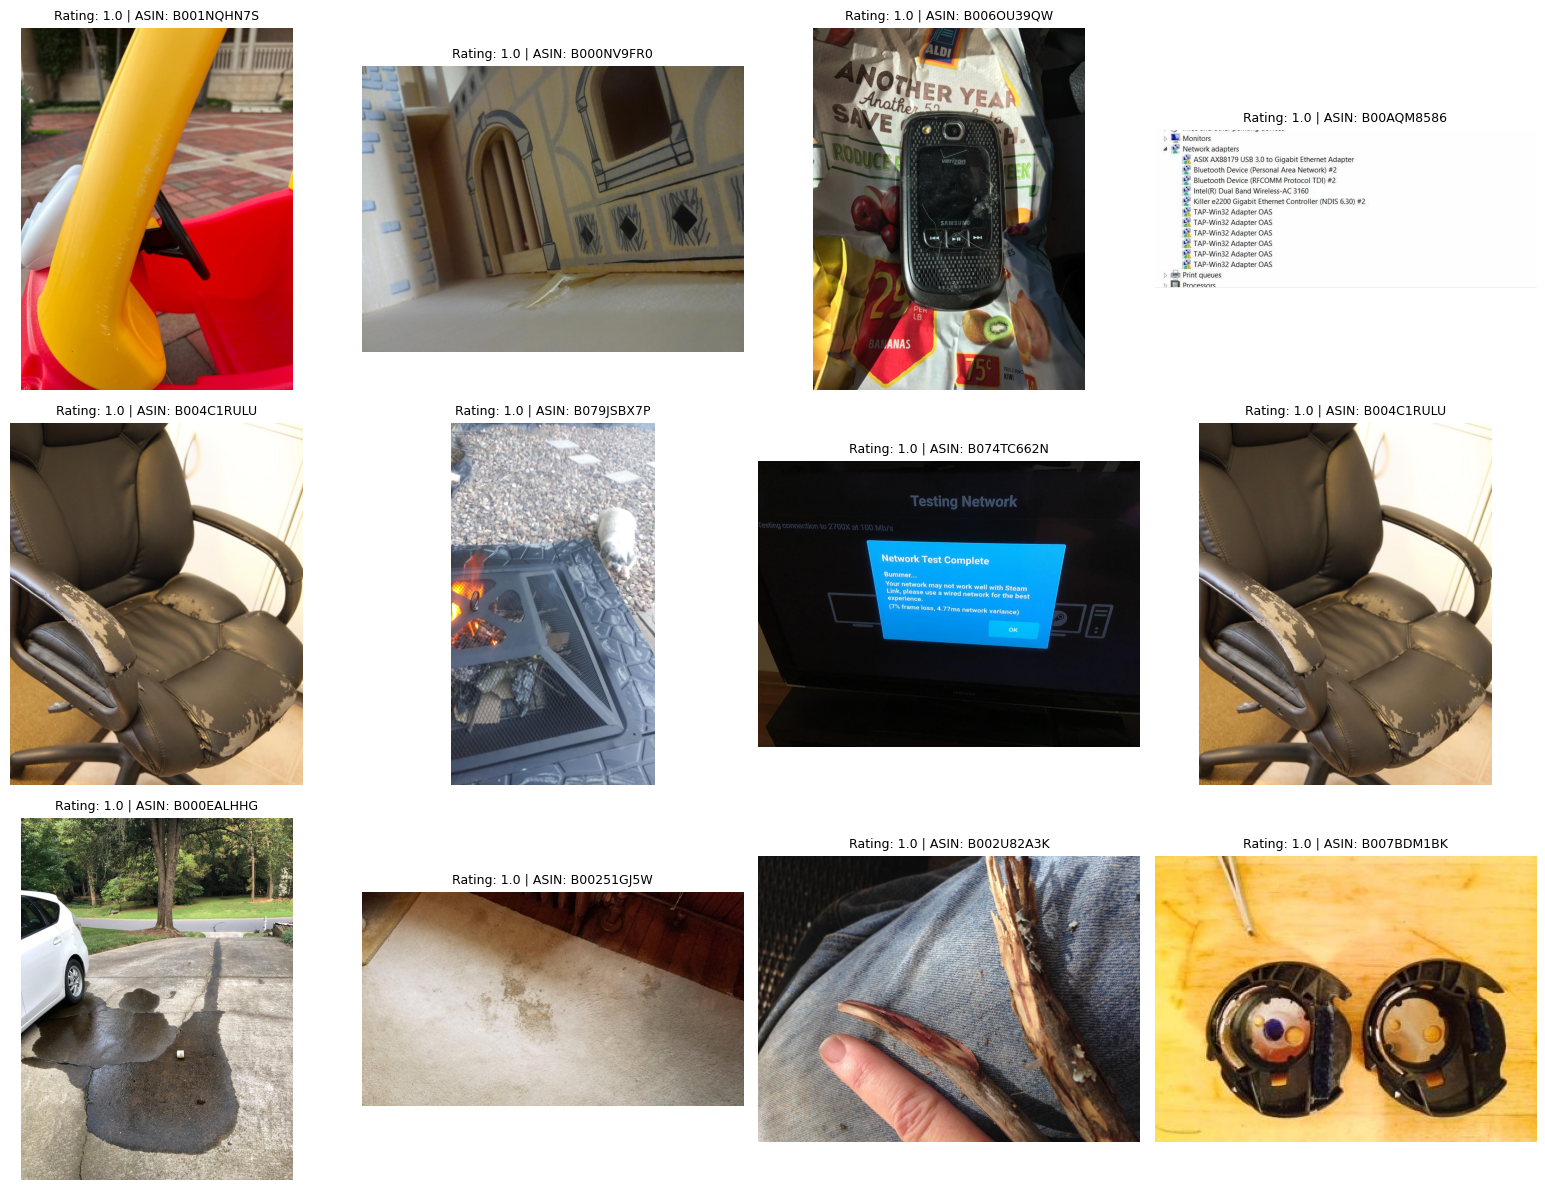


Displaying non-complaint images...


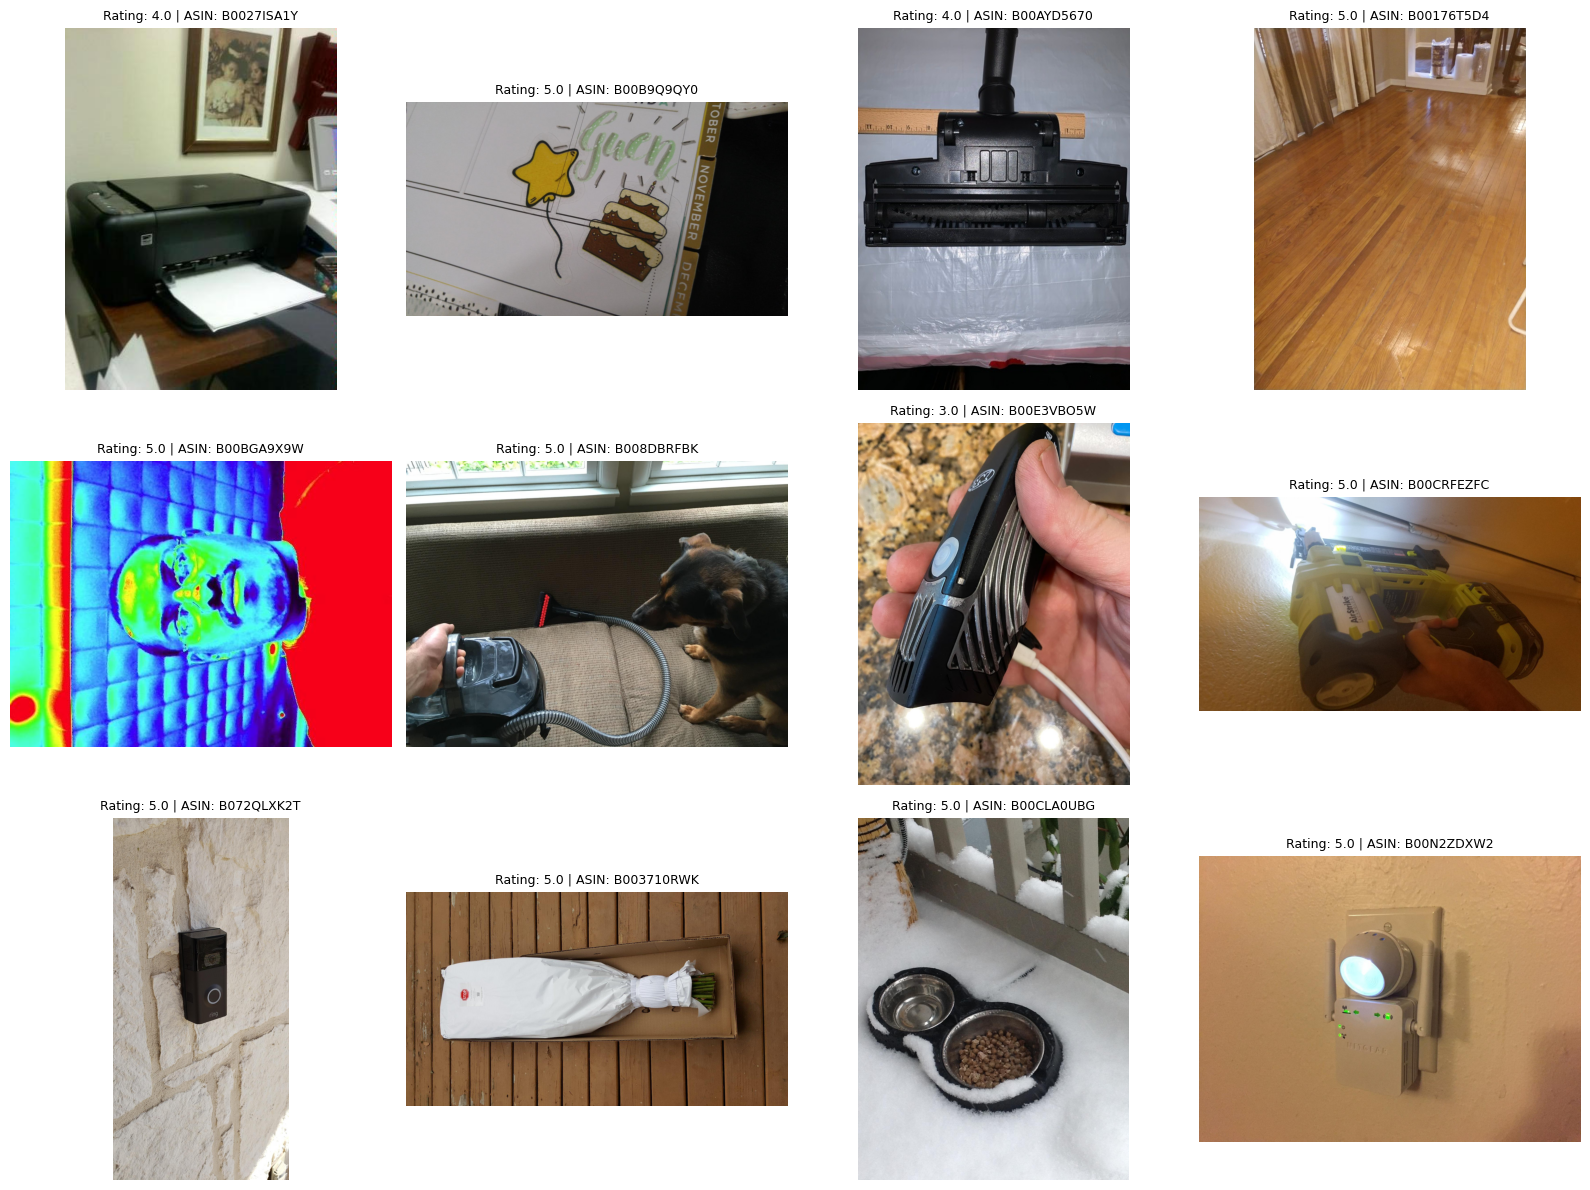

In [50]:
# ============================================================
# STAGE 4C — VISUAL INSPECTION OF CUSTOMER REVIEW IMAGES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

INPUT_FILE = "/kaggle/working/review_images_downloaded.csv"

df = pd.read_csv(INPUT_FILE)

# Only successfully downloaded images
df = df[df["downloaded"] == True].copy()

print("Usable images:", len(df))
print("Complaint images:", (df["complaint"] == 1).sum())
print("Non-complaint images:", (df["complaint"] == 0).sum())


# ------------------------------------------------------------
# Select 12 complaint and 12 non-complaint images
# ------------------------------------------------------------

complaint_df = df[df["complaint"] == 1].sample(
    min(12, len(df[df["complaint"] == 1])),
    random_state=42
)

non_complaint_df = df[df["complaint"] == 0].sample(
    min(12, len(df[df["complaint"] == 0])),
    random_state=42
)


# ------------------------------------------------------------
# Display complaint images
# ------------------------------------------------------------

print("\nDisplaying complaint images...")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (_, row) in zip(axes.flat, complaint_df.iterrows()):

    try:
        img = Image.open(row["local_path"]).convert("RGB")

        ax.imshow(img)
        ax.set_title(
            f"Rating: {row['rating']} | "
            f"ASIN: {row['asin']}",
            fontsize=9
        )
        ax.axis("off")

    except Exception:
        ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Display non-complaint images
# ------------------------------------------------------------

print("\nDisplaying non-complaint images...")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (_, row) in zip(axes.flat, non_complaint_df.iterrows()):

    try:
        img = Image.open(row["local_path"]).convert("RGB")

        ax.imshow(img)
        ax.set_title(
            f"Rating: {row['rating']} | "
            f"ASIN: {row['asin']}",
            fontsize=9
        )
        ax.axis("off")

    except Exception:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
# ============================================================
# STAGE 4D — CLIP VISUAL FEATURE EXTRACTION
# GPU: NVIDIA T4
# ============================================================

!pip install -q transformers accelerate

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPProcessor, CLIPModel


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

INPUT_FILE = "/kaggle/working/review_images_downloaded.csv"
OUTPUT_FILE = "/kaggle/working/review_visual_features.csv"

IMAGE_MODEL = "openai/clip-vit-base-patch32"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. Load image metadata
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

df = df[
    (df["downloaded"] == True) &
    (df["local_path"].notna())
].copy()

df = df.reset_index(drop=True)

print("\nUsable images:", len(df))


# ------------------------------------------------------------
# 3. Load CLIP
# ------------------------------------------------------------

processor = CLIPProcessor.from_pretrained(IMAGE_MODEL)

model = CLIPModel.from_pretrained(
    IMAGE_MODEL
).to(DEVICE)

model.eval()

print("CLIP loaded.")


# ------------------------------------------------------------
# 4. Visual complaint concepts
# ------------------------------------------------------------

concepts = {

    # Complaint / defect
    "damaged_product": "a photo showing a damaged product",
    "broken_product": "a photo showing a broken product",
    "defective_product": "a photo showing a defective product",
    "poor_condition": "a photo showing a product in poor condition",
    "leaking_product": "a photo showing a leaking product",

    # Packaging-related
    "damaged_packaging": "a photo showing damaged product packaging",
    "opened_packaging": "a photo showing opened or tampered packaging",

    # Other complaint evidence
    "missing_component": "a photo showing a missing or incomplete product component",
    "wrong_product": "a photo showing the wrong product or incorrect item",

    # Normal/positive condition
    "good_condition": "a photo showing a product in good condition",
    "normal_product": "a normal product photo"
}

concept_names = list(concepts.keys())
concept_prompts = list(concepts.values())


# ------------------------------------------------------------
# 5. Encode text prompts
# ------------------------------------------------------------

text_inputs = processor(
    text=concept_prompts,
    padding=True,
    return_tensors="pt"
).to(DEVICE)

with torch.no_grad():

    text_features = model.get_text_features(
        **text_inputs
    )

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

print("Text concept embeddings:", text_features.shape)


# ------------------------------------------------------------
# 6. Process images in batches
# ------------------------------------------------------------

BATCH_SIZE = 32

all_embeddings = []
all_concept_scores = []
successful_indices = []

for start in tqdm(
    range(0, len(df), BATCH_SIZE),
    desc="CLIP image encoding"
):

    batch_df = df.iloc[
        start:start + BATCH_SIZE
    ]

    images = []
    valid_local_indices = []

    for local_idx, (_, row) in enumerate(
        batch_df.iterrows()
    ):

        try:

            image = Image.open(
                row["local_path"]
            ).convert("RGB")

            images.append(image)
            valid_local_indices.append(
                start + local_idx
            )

        except Exception as e:

            print(
                f"Skipping image: {row['local_path']} | {e}"
            )


    if not images:
        continue


    # --------------------------------------------------------
    # Image preprocessing
    # --------------------------------------------------------

    inputs = processor(
        images=images,
        return_tensors="pt"
    ).to(DEVICE)


    # --------------------------------------------------------
    # Image embeddings
    # --------------------------------------------------------

    with torch.no_grad():

        image_features = model.get_image_features(
            **inputs
        )

        image_features = image_features / image_features.norm(
            dim=-1,
            keepdim=True
        )


        # ----------------------------------------------------
        # Image-to-text concept similarity
        # ----------------------------------------------------

        similarities = image_features @ text_features.T


    all_embeddings.append(
        image_features.cpu().numpy()
    )

    all_concept_scores.append(
        similarities.cpu().numpy()
    )

    successful_indices.extend(
        valid_local_indices
    )


# ------------------------------------------------------------
# 7. Combine outputs
# ------------------------------------------------------------

embeddings = np.vstack(all_embeddings)

concept_scores = np.vstack(all_concept_scores)

print("\nEmbedding shape:", embeddings.shape)
print("Concept score shape:", concept_scores.shape)


# ------------------------------------------------------------
# 8. Create feature dataframe
# ------------------------------------------------------------

feature_rows = df.iloc[
    successful_indices
].reset_index(drop=True).copy()


# ------------------------------------------------------------
# 9. Save CLIP embedding columns
# ------------------------------------------------------------

for i in range(embeddings.shape[1]):

    feature_rows[f"clip_{i}"] = embeddings[:, i]


# ------------------------------------------------------------
# 10. Save concept similarity scores
# ------------------------------------------------------------

for i, concept_name in enumerate(concept_names):

    feature_rows[
        f"visual_{concept_name}"
    ] = concept_scores[:, i]


# ------------------------------------------------------------
# 11. Create aggregated complaint scores
# ------------------------------------------------------------

complaint_concepts = [
    "damaged_product",
    "broken_product",
    "defective_product",
    "poor_condition",
    "leaking_product",
    "damaged_packaging",
    "opened_packaging",
    "missing_component",
    "wrong_product"
]

positive_concepts = [
    "good_condition",
    "normal_product"
]


feature_rows["visual_complaint_score"] = (
    feature_rows[
        [f"visual_{c}" for c in complaint_concepts]
    ].mean(axis=1)
)


feature_rows["visual_normal_score"] = (
    feature_rows[
        [f"visual_{c}" for c in positive_concepts]
    ].mean(axis=1)
)


feature_rows["visual_complaint_margin"] = (
    feature_rows["visual_complaint_score"]
    -
    feature_rows["visual_normal_score"]
)


# ------------------------------------------------------------
# 12. Save image-level features
# ------------------------------------------------------------

feature_rows.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\n========================================")
print("CLIP EXTRACTION COMPLETE")
print("========================================")

print("Images processed:", len(feature_rows))
print("Embedding dimensions:", embeddings.shape[1])

print(
    "Mean visual complaint score:",
    feature_rows["visual_complaint_score"].mean()
)

print(
    "Mean visual complaint margin:",
    feature_rows["visual_complaint_margin"].mean()
)

print("\nSaved:")
print(OUTPUT_FILE)

Device: cuda
GPU: Tesla T4

Usable images: 2251


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP loaded.


AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

In [52]:
# ============================================================
# STAGE 4D — CLIP VISUAL FEATURE EXTRACTION
# Corrected for current Transformers API
# ============================================================

!pip install -q transformers accelerate

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPProcessor, CLIPModel


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

INPUT_FILE = "/kaggle/working/review_images_downloaded.csv"
OUTPUT_FILE = "/kaggle/working/review_visual_features.csv"

MODEL_NAME = "openai/clip-vit-base-patch32"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. Load image metadata
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

df = df[
    (df["downloaded"] == True) &
    (df["local_path"].notna())
].copy()

df = df.reset_index(drop=True)

print("\nUsable images:", len(df))


# ------------------------------------------------------------
# 3. Load CLIP
# ------------------------------------------------------------

processor = CLIPProcessor.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

model = CLIPModel.from_pretrained(
    MODEL_NAME
).to(DEVICE)

model.eval()

print("CLIP loaded.")


# ------------------------------------------------------------
# 4. Define visual concepts
# ------------------------------------------------------------

concepts = {
    "damaged_product":
        "a photo showing a damaged product",

    "broken_product":
        "a photo showing a broken product",

    "defective_product":
        "a photo showing a defective product",

    "poor_condition":
        "a photo showing a product in poor condition",

    "leaking_product":
        "a photo showing a leaking product",

    "damaged_packaging":
        "a photo showing damaged product packaging",

    "opened_packaging":
        "a photo showing opened or tampered packaging",

    "missing_component":
        "a photo showing a missing or incomplete product component",

    "wrong_product":
        "a photo showing the wrong product or incorrect item",

    "good_condition":
        "a photo showing a product in good condition",

    "normal_product":
        "a normal product photo"
}

concept_names = list(concepts.keys())
concept_prompts = list(concepts.values())


# ------------------------------------------------------------
# 5. Encode text concepts
# ------------------------------------------------------------

text_inputs = processor(
    text=concept_prompts,
    padding=True,
    return_tensors="pt"
)

text_inputs = {
    k: v.to(DEVICE)
    for k, v in text_inputs.items()
}

with torch.no_grad():

    text_outputs = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"]
    )

    # CLIP uses pooled text representation
    text_embeds = text_outputs.pooler_output

    text_features = model.text_projection(
        text_embeds
    )

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

print(
    "Text concept embedding shape:",
    text_features.shape
)


# ------------------------------------------------------------
# 6. Process images in batches
# ------------------------------------------------------------

BATCH_SIZE = 32

all_embeddings = []
all_concept_scores = []
successful_indices = []

for start in tqdm(
    range(0, len(df), BATCH_SIZE),
    desc="CLIP image encoding"
):

    batch_df = df.iloc[
        start:start + BATCH_SIZE
    ]

    images = []
    valid_local_indices = []

    for local_idx, (_, row) in enumerate(
        batch_df.iterrows()
    ):

        try:

            image = Image.open(
                row["local_path"]
            ).convert("RGB")

            images.append(image)

            valid_local_indices.append(
                start + local_idx
            )

        except Exception as e:

            print(
                f"Skipping image: "
                f"{row['local_path']} | {e}"
            )

    if not images:
        continue


    # --------------------------------------------------------
    # Prepare images
    # --------------------------------------------------------

    image_inputs = processor(
        images=images,
        return_tensors="pt"
    )

    image_inputs = {
        k: v.to(DEVICE)
        for k, v in image_inputs.items()
    }


    # --------------------------------------------------------
    # Encode images
    # --------------------------------------------------------

    with torch.no_grad():

        vision_outputs = model.vision_model(
            pixel_values=image_inputs["pixel_values"]
        )

        image_embeds = vision_outputs.pooler_output

        image_features = model.visual_projection(
            image_embeds
        )

        image_features = (
            image_features /
            image_features.norm(
                dim=-1,
                keepdim=True
            )
        )


        # ----------------------------------------------------
        # Image ↔ text concept similarities
        # ----------------------------------------------------

        similarities = (
            image_features @ text_features.T
        )


    all_embeddings.append(
        image_features.cpu().numpy()
    )

    all_concept_scores.append(
        similarities.cpu().numpy()
    )

    successful_indices.extend(
        valid_local_indices
    )


# ------------------------------------------------------------
# 7. Combine embeddings
# ------------------------------------------------------------

embeddings = np.vstack(
    all_embeddings
)

concept_scores = np.vstack(
    all_concept_scores
)

print(
    "\nImage embedding shape:",
    embeddings.shape
)

print(
    "Concept score shape:",
    concept_scores.shape
)


# ------------------------------------------------------------
# 8. Build image-level feature dataframe
# ------------------------------------------------------------

feature_rows = df.iloc[
    successful_indices
].reset_index(drop=True).copy()


# ------------------------------------------------------------
# 9. Save CLIP embedding columns
# ------------------------------------------------------------

for i in range(
    embeddings.shape[1]
):

    feature_rows[
        f"clip_{i}"
    ] = embeddings[:, i]


# ------------------------------------------------------------
# 10. Save visual concept scores
# ------------------------------------------------------------

for i, concept_name in enumerate(
    concept_names
):

    feature_rows[
        f"visual_{concept_name}"
    ] = concept_scores[:, i]


# ------------------------------------------------------------
# 11. Aggregate complaint-related visual concepts
# ------------------------------------------------------------

complaint_concepts = [
    "damaged_product",
    "broken_product",
    "defective_product",
    "poor_condition",
    "leaking_product",
    "damaged_packaging",
    "opened_packaging",
    "missing_component",
    "wrong_product"
]

positive_concepts = [
    "good_condition",
    "normal_product"
]


feature_rows[
    "visual_complaint_score"
] = feature_rows[
    [f"visual_{c}" for c in complaint_concepts]
].mean(axis=1)


feature_rows[
    "visual_normal_score"
] = feature_rows[
    [f"visual_{c}" for c in positive_concepts]
].mean(axis=1)


feature_rows[
    "visual_complaint_margin"
] = (
    feature_rows["visual_complaint_score"]
    -
    feature_rows["visual_normal_score"]
)


# ------------------------------------------------------------
# 12. Save
# ------------------------------------------------------------

feature_rows.to_csv(
    OUTPUT_FILE,
    index=False
)


# ------------------------------------------------------------
# 13. Final summary
# ------------------------------------------------------------

print("\n========================================")
print("CLIP EXTRACTION COMPLETE")
print("========================================")

print(
    "Images processed:",
    len(feature_rows)
)

print(
    "Embedding dimensions:",
    embeddings.shape[1]
)

print(
    "Mean visual complaint score:",
    round(
        feature_rows[
            "visual_complaint_score"
        ].mean(),
        6
    )
)

print(
    "Mean visual complaint margin:",
    round(
        feature_rows[
            "visual_complaint_margin"
        ].mean(),
        6
    )
)

print("\nSaved:")
print(OUTPUT_FILE)

Device: cuda
GPU: Tesla T4

Usable images: 2251


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP loaded.
Text concept embedding shape: torch.Size([11, 512])


CLIP image encoding:   0%|          | 0/71 [00:00<?, ?it/s]


Image embedding shape: (2251, 512)
Concept score shape: (2251, 11)


/tmp/ipykernel_58/982443581.py:303: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_rows[
/tmp/ipykernel_58/982443581.py:303: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_rows[
/tmp/ipykernel_58/982443581.py:303: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_rows[
/tmp/ipykerne


CLIP EXTRACTION COMPLETE
Images processed: 2251
Embedding dimensions: 512
Mean visual complaint score: 0.23635
Mean visual complaint margin: -0.006803

Saved:
/kaggle/working/review_visual_features.csv


In [53]:
# ============================================================
# STAGE 4E — VALIDATE CLIP VISUAL COMPLAINT SIGNAL
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import roc_auc_score

INPUT_FILE = "/kaggle/working/review_visual_features.csv"

df = pd.read_csv(INPUT_FILE)

print("Images:", len(df))


# ------------------------------------------------------------
# 1. Complaint / non-complaint statistics
# ------------------------------------------------------------

summary = (
    df.groupby("complaint")[
        [
            "visual_complaint_score",
            "visual_normal_score",
            "visual_complaint_margin"
        ]
    ]
    .agg(["mean", "median", "std"])
)

print("\n========================================")
print("VISUAL SIGNAL BY COMPLAINT STATUS")
print("========================================")

print(summary)


# ------------------------------------------------------------
# 2. AUC
# ------------------------------------------------------------

y_true = df["complaint"].astype(int)

auc_score = roc_auc_score(
    y_true,
    df["visual_complaint_score"]
)

margin_auc = roc_auc_score(
    y_true,
    df["visual_complaint_margin"]
)

print("\nVisual complaint score AUC:", round(auc_score, 4))
print("Visual complaint margin AUC:", round(margin_auc, 4))


# ------------------------------------------------------------
# 3. Complaint intensity relationship
# ------------------------------------------------------------

# Only image records belonging to complaint reviews
complaint_df = df[
    (df["complaint"] == 1) &
    (df["intensity"].notna())
].copy()

if len(complaint_df) > 0:

    correlation = complaint_df[
        [
            "visual_complaint_score",
            "visual_complaint_margin",
            "intensity"
        ]
    ].corr()

    print("\n========================================")
    print("VISUAL FEATURES vs COMPLAINT INTENSITY")
    print("========================================")

    print(correlation)


# ------------------------------------------------------------
# 4. Rating-wise analysis
# ------------------------------------------------------------

print("\n========================================")
print("VISUAL COMPLAINT SCORE BY RATING")
print("========================================")

print(
    df.groupby("rating")[
        [
            "visual_complaint_score",
            "visual_complaint_margin"
        ]
    ]
    .agg(["mean", "median", "count"])
)


# ------------------------------------------------------------
# 5. Complaint-image counts
# ------------------------------------------------------------

print("\n========================================")
print("COUNTS")
print("========================================")

print(
    df["complaint"].value_counts()
)

Images: 2251

VISUAL SIGNAL BY COMPLAINT STATUS
          visual_complaint_score                     visual_normal_score  \
                            mean    median       std                mean   
complaint                                                                  
0                       0.235193  0.237952  0.024510            0.242849   
1                       0.242546  0.245079  0.022939            0.244776   

                              visual_complaint_margin                      
             median       std                    mean    median       std  
complaint                                                                  
0          0.246298  0.022128               -0.007656 -0.008372  0.010662  
1          0.246112  0.019090               -0.002230 -0.003307  0.012190  

Visual complaint score AUC: 0.5899
Visual complaint margin AUC: 0.6298


KeyError: 'intensity'

In [56]:
text_df = pd.read_csv(
    "/kaggle/working/final_interaction_features.csv"
)

visual_df = pd.read_csv(
    "/kaggle/working/review_visual_features.csv"
)

print("TEXT FEATURES:")
print(text_df.columns.tolist())

print("\nVISUAL FEATURES:")
print(visual_df.columns.tolist())

TEXT FEATURES:
['user_id', 'asin', 'parent_asin', 'rating', 'title', 'text', 'timestamp', 'verified_purchase', 'helpful_vote', 'has_image', 'images', 'review_text', 'complaint', 'review_date', 'review_row_id', 'sentiment_label', 'sentiment_score', 'sentiment_encoded', 'emotion', 'emotion_score', 'emotion_encoded', 'detected_aspects', 'primary_aspect', 'aspect_count', 'multi_aspect', 'aspect_encoded', 'rating_severity', 'sentiment_negativity', 'emotion_weight', 'weighted_emotion_score', 'aspect_contribution', 'complaint_intensity', 'intensity_category']

VISUAL FEATURES:
['source_row_id', 'user_id', 'asin', 'parent_asin', 'rating', 'complaint', 'review_text', 'review_date', 'image_number', 'image_url', 'attachment_type', 'valid_url', 'downloaded', 'status_code', 'width', 'height', 'file_size', 'format', 'error', 'local_path', 'clip_0', 'clip_1', 'clip_2', 'clip_3', 'clip_4', 'clip_5', 'clip_6', 'clip_7', 'clip_8', 'clip_9', 'clip_10', 'clip_11', 'clip_12', 'clip_13', 'clip_14', 'clip_15

In [57]:
# ============================================================
# STAGE 4E — MULTIMODAL REVIEW-LEVEL FEATURE FUSION
# ============================================================

import pandas as pd
import numpy as np

TEXT_FILE = "/kaggle/working/final_interaction_features.csv"
VISUAL_FILE = "/kaggle/working/review_visual_features.csv"
OUTPUT_FILE = "/kaggle/working/multimodal_interaction_features.csv"


# ------------------------------------------------------------
# 1. Load datasets
# ------------------------------------------------------------

text_df = pd.read_csv(TEXT_FILE)
visual_df = pd.read_csv(VISUAL_FILE)

print("Text rows:", len(text_df))
print("Visual image rows:", len(visual_df))


# ------------------------------------------------------------
# 2. Reconstruct the review_row_id in visual data
#
# source_row_id is the original row index from model_reviews.csv
# and corresponds to review_row_id in final_interaction_features.
# ------------------------------------------------------------

visual_df["review_row_id"] = visual_df["source_row_id"].astype(int)


# ------------------------------------------------------------
# 3. Select visual features
# ------------------------------------------------------------

visual_features = [
    "visual_damaged_product",
    "visual_broken_product",
    "visual_defective_product",
    "visual_poor_condition",
    "visual_leaking_product",
    "visual_damaged_packaging",
    "visual_opened_packaging",
    "visual_missing_component",
    "visual_wrong_product",
    "visual_good_condition",
    "visual_normal_product",
    "visual_complaint_score",
    "visual_normal_score",
    "visual_complaint_margin"
]


# ------------------------------------------------------------
# 4. Aggregate image features to REVIEW level
#
# Multiple images can belong to one review.
# Mean captures overall visual evidence.
# Max captures the strongest visual evidence.
# ------------------------------------------------------------

visual_mean = (
    visual_df
    .groupby("review_row_id")[visual_features]
    .mean()
    .add_suffix("_mean")
)

visual_max = (
    visual_df
    .groupby("review_row_id")[visual_features]
    .max()
    .add_suffix("_max")
)

image_count = (
    visual_df
    .groupby("review_row_id")
    .size()
    .rename("visual_image_count")
)


# ------------------------------------------------------------
# 5. Combine review-level visual features
# ------------------------------------------------------------

review_visual = pd.concat(
    [
        visual_mean,
        visual_max,
        image_count
    ],
    axis=1
).reset_index()


print("\nReview-level visual profiles:", len(review_visual))


# ------------------------------------------------------------
# 6. Merge with all 70,854 interaction rows
# ------------------------------------------------------------

multimodal_df = text_df.merge(
    review_visual,
    on="review_row_id",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 7. Fill missing visual information
#
# Reviews without images receive zero visual evidence.
# ------------------------------------------------------------

visual_columns = [
    c for c in review_visual.columns
    if c != "review_row_id"
]

multimodal_df[visual_columns] = (
    multimodal_df[visual_columns]
    .fillna(0)
)


# ------------------------------------------------------------
# 8. Create explicit image indicator
# ------------------------------------------------------------

multimodal_df["has_visual_features"] = (
    multimodal_df["visual_image_count"] > 0
).astype(int)


# ------------------------------------------------------------
# 9. Create a compact multimodal complaint score
#
# Text complaint intensity is retained.
# Visual complaint margin is normalized to a comparable
# 0-1 scale using sigmoid transformation.
# ------------------------------------------------------------

visual_margin = (
    multimodal_df["visual_complaint_margin_mean"]
)

multimodal_df["visual_complaint_probability"] = (
    1 / (1 + np.exp(-20 * visual_margin))
)


# Text + visual fusion
#
# Text carries the primary complaint signal.
# Visual evidence provides additional information when present.

multimodal_df["multimodal_complaint_score"] = np.where(
    multimodal_df["has_visual_features"] == 1,

    (
        0.70 * multimodal_df["complaint_intensity"]
        +
        0.30 * multimodal_df["visual_complaint_probability"]
    ),

    multimodal_df["complaint_intensity"]
)

multimodal_df["multimodal_complaint_score"] = (
    multimodal_df["multimodal_complaint_score"]
    .clip(0, 1)
)


# ------------------------------------------------------------
# 10. Sanity checks
# ------------------------------------------------------------

print("\n========================================")
print("MULTIMODAL DATASET SUMMARY")
print("========================================")

print("Rows:", len(multimodal_df))
print(
    "Expected rows:",
    len(text_df)
)

print(
    "\nReviews with visual features:",
    multimodal_df["has_visual_features"].sum()
)

print(
    "Expected visual reviews:",
    visual_df["review_row_id"].nunique()
)

print(
    "\nComplaint reviews:",
    multimodal_df["complaint"].sum()
)

print(
    "Complaint reviews with images:",
    (
        (multimodal_df["complaint"] == 1) &
        (multimodal_df["has_visual_features"] == 1)
    ).sum()
)

print(
    "\nImage reviews by complaint status:"
)

print(
    pd.crosstab(
        multimodal_df["complaint"],
        multimodal_df["has_visual_features"]
    )
)


# ------------------------------------------------------------
# 11. Save
# ------------------------------------------------------------

multimodal_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nSaved:")
print(OUTPUT_FILE)


# ------------------------------------------------------------
# 12. Preview the key multimodal fields
# ------------------------------------------------------------

preview_cols = [
    "review_row_id",
    "user_id",
    "asin",
    "rating",
    "complaint",
    "complaint_intensity",
    "visual_image_count",
    "visual_complaint_score_mean",
    "visual_complaint_margin_mean",
    "visual_complaint_probability",
    "multimodal_complaint_score"
]

print("\nPreview:")
print(
    multimodal_df[preview_cols]
    .head(10)
    .to_string(index=False)
)

Text rows: 70854
Visual image rows: 2251

Review-level visual profiles: 1181

MULTIMODAL DATASET SUMMARY
Rows: 70854
Expected rows: 70854

Reviews with visual features: 1181
Expected visual reviews: 1181

Complaint reviews: 7933
Complaint reviews with images: 222

Image reviews by complaint status:
has_visual_features      0    1
complaint                      
0                    61962  959
1                     7711  222

Saved:
/kaggle/working/multimodal_interaction_features.csv

Preview:
 review_row_id                      user_id       asin  rating  complaint  complaint_intensity  visual_image_count  visual_complaint_score_mean  visual_complaint_margin_mean  visual_complaint_probability  multimodal_complaint_score
             0 AE22236AFRRSMQIKGG7TPTB75QEA B000JVJ8KS     4.0          0                  0.0                 0.0                          0.0                           0.0                           0.5                         0.0
             1 AE22236AFRRSMQIKGG7TPTB

In [58]:
# ============================================================
# DIAGNOSTIC — FIND REVIEWS LOST FROM VISUAL AGGREGATION
# ============================================================

import pandas as pd

original = pd.read_csv(
    "/kaggle/working/review_images.csv"
)

downloaded = pd.read_csv(
    "/kaggle/working/review_images_downloaded.csv"
)

multimodal = pd.read_csv(
    "/kaggle/working/multimodal_interaction_features.csv"
)

# ------------------------------------------------------------
# Reviews originally containing images
# ------------------------------------------------------------

original_review_ids = set(
    original["source_row_id"].unique()
)

downloaded_review_ids = set(
    downloaded[
        downloaded["downloaded"] == True
    ]["source_row_id"].unique()
)

multimodal_review_ids = set(
    multimodal[
        multimodal["has_visual_features"] == 1
    ]["review_row_id"].unique()
)

print("Originally image reviews:",
      len(original_review_ids))

print("Reviews with >=1 successful image:",
      len(downloaded_review_ids))

print("Reviews with visual features:",
      len(multimodal_review_ids))


# ------------------------------------------------------------
# Reviews with images originally but no successful download
# ------------------------------------------------------------

lost_reviews = (
    original_review_ids
    - downloaded_review_ids
)

print("\nReviews with NO successful downloaded image:",
      len(lost_reviews))

if lost_reviews:

    lost_df = original[
        original["source_row_id"].isin(lost_reviews)
    ].copy()

    print("\nLost reviews:")
    print(
        lost_df[
            [
                "source_row_id",
                "user_id",
                "asin",
                "rating",
                "complaint",
                "image_number",
                "image_url"
            ]
        ].to_string(index=False)
    )


# ------------------------------------------------------------
# Check whether aggregation itself lost anything
# ------------------------------------------------------------

aggregation_loss = (
    downloaded_review_ids
    - multimodal_review_ids
)

print(
    "\nSuccessful-download reviews missing after aggregation:",
    len(aggregation_loss)
)

if aggregation_loss:
    print(sorted(list(aggregation_loss)))


# ------------------------------------------------------------
# Complaint check
# ------------------------------------------------------------

original_complaint_reviews = set(
    original[
        original["complaint"] == 1
    ]["source_row_id"].unique()
)

downloaded_complaint_reviews = set(
    downloaded[
        (downloaded["downloaded"] == True) &
        (downloaded["complaint"] == 1)
    ]["source_row_id"].unique()
)

multimodal_complaint_reviews = set(
    multimodal[
        (multimodal["complaint"] == 1) &
        (multimodal["has_visual_features"] == 1)
    ]["review_row_id"].unique()
)

print("\nComplaint reviews originally:",
      len(original_complaint_reviews))

print("Complaint reviews with successful images:",
      len(downloaded_complaint_reviews))

print("Complaint reviews in multimodal dataset:",
      len(multimodal_complaint_reviews))

Originally image reviews: 1187
Reviews with >=1 successful image: 1181
Reviews with visual features: 1181

Reviews with NO successful downloaded image: 6

Lost reviews:
 source_row_id                      user_id       asin  rating  complaint  image_number                                                        image_url
           478 AE2YZJRAYRU3QZXN2GUXWAB35JBQ B002SB91QS     1.0          1             1 https://images-na.ssl-images-amazon.com/images/I/71PPGFFgZNL.jpg
          8979 AEK2MTURJVWLMWCJCEVPJA7ILV7Q B001ICYB2M     5.0          0             1 https://images-na.ssl-images-amazon.com/images/I/719S2dOAMpL.jpg
          8979 AEK2MTURJVWLMWCJCEVPJA7ILV7Q B001ICYB2M     5.0          0             2 https://images-na.ssl-images-amazon.com/images/I/71py8wLK1sL.jpg
         11675 AEOQPX54NIQ3IREXEK34FOETI3HQ B000I9RZOW     5.0          0             1 https://images-na.ssl-images-amazon.com/images/I/71HMtYMj94L.jpg
         19212 AF4SOFFAFFQLR6PF4FPZYIC7WACQ B0791T9CV7     5.0    

In [59]:
# ============================================================
# FINAL MODEL PREPARATION
# Create clean Text / Image / Multimodal feature sets
# ============================================================

import pandas as pd
import numpy as np

INPUT_FILE = "/kaggle/working/multimodal_interaction_features.csv"

df = pd.read_csv(INPUT_FILE)

print("Rows:", len(df))
print("Columns:", len(df.columns))

# ------------------------------------------------------------
# Text features already used in your existing XGBoost model
# ------------------------------------------------------------

text_features = [
    "sentiment_score",
    "emotion_score",
    "complaint_intensity",
    "aspect_count",
    "rating_severity",
    "sentiment_negativity",
    "weighted_emotion_score",
    "aspect_contribution",
    "sentiment_encoded",
    "emotion_encoded",
    "aspect_encoded"
]

# ------------------------------------------------------------
# Compact visual features
# We deliberately do NOT use the 512 CLIP dimensions.
# ------------------------------------------------------------

visual_features = [
    "visual_damaged_product_mean",
    "visual_broken_product_mean",
    "visual_defective_product_mean",
    "visual_poor_condition_mean",
    "visual_leaking_product_mean",
    "visual_damaged_packaging_mean",
    "visual_opened_packaging_mean",
    "visual_missing_component_mean",
    "visual_wrong_product_mean",
    "visual_good_condition_mean",
    "visual_normal_product_mean",
    "visual_complaint_score_mean",
    "visual_normal_score_mean",
    "visual_complaint_margin_mean",
    "visual_image_count"
]

# ------------------------------------------------------------
# Check required columns
# ------------------------------------------------------------

missing_text = [
    c for c in text_features
    if c not in df.columns
]

missing_visual = [
    c for c in visual_features
    if c not in df.columns
]

print("\nMissing text features:", missing_text)
print("Missing visual features:", missing_visual)

assert not missing_text
assert not missing_visual

# ------------------------------------------------------------
# Fill numeric missing values
# ------------------------------------------------------------

df[text_features] = df[text_features].fillna(0)
df[visual_features] = df[visual_features].fillna(0)

# ------------------------------------------------------------
# Create three feature sets
# ------------------------------------------------------------

text_model_features = text_features

image_model_features = visual_features

multimodal_model_features = (
    text_features +
    visual_features
)

print("\nText features:", len(text_model_features))
print("Image features:", len(image_model_features))
print("Multimodal features:", len(multimodal_model_features))

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

df.to_csv(
    "/kaggle/working/final_multimodal_dataset.csv",
    index=False
)

print(
    "\nSaved:"
    "/kaggle/working/final_multimodal_dataset.csv"
)

Rows: 70854
Columns: 65

Missing text features: []
Missing visual features: []

Text features: 11
Image features: 15
Multimodal features: 26

Saved:/kaggle/working/final_multimodal_dataset.csv


In [60]:
# ============================================================
# CHECK EXISTING RECOMMENDATION DATASET / SPLIT
# ============================================================

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/final_multimodal_dataset.csv"
)

print("Dataset shape:", df.shape)

print("\nUsers:", df["user_id"].nunique())
print("Products:", df["asin"].nunique())

print("\nRatings:")
print(df["rating"].value_counts().sort_index())

print("\nComplaints:", df["complaint"].sum())

print("\nColumns relevant to recommendation:")
print([
    c for c in df.columns
    if c in [
        "user_id",
        "asin",
        "rating",
        "complaint",
        "review_row_id",
        "sentiment_score",
        "emotion_score",
        "complaint_intensity",
        "visual_complaint_score_mean",
        "visual_complaint_margin_mean",
        "visual_image_count"
    ]
])

Dataset shape: (70854, 65)

Users: 20765
Products: 2815

Ratings:
rating
1.0     4893
2.0     3040
3.0     5308
4.0    10908
5.0    46705
Name: count, dtype: int64

Complaints: 7933

Columns relevant to recommendation:
['user_id', 'asin', 'rating', 'complaint', 'review_row_id', 'sentiment_score', 'emotion_score', 'complaint_intensity', 'visual_complaint_score_mean', 'visual_complaint_margin_mean', 'visual_image_count']


In [61]:
# ============================================================
# FINAL MULTIMODAL EXPERIMENT — STEP 1
# SVD split + candidate generation
# ============================================================

import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

DATA_FILE = "/kaggle/working/final_multimodal_dataset.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset:", df.shape)

# ------------------------------------------------------------
# Encode users/products
# ------------------------------------------------------------

le_u = LabelEncoder()
le_p = LabelEncoder()

df["user_idx"] = le_u.fit_transform(df["user_id"])
df["product_idx"] = le_p.fit_transform(df["asin"])

n_users = df["user_idx"].nunique()
n_products = df["product_idx"].nunique()

print("Users:", n_users)
print("Products:", n_products)

# ------------------------------------------------------------
# Same 80/20 split as your notebook
# ------------------------------------------------------------

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTrain:", len(train_df))
print("Test:", len(test_df))

# ------------------------------------------------------------
# Build sparse train matrix
# ------------------------------------------------------------

train_matrix = csr_matrix(
    (
        train_df["rating"].astype(float),
        (
            train_df["user_idx"],
            train_df["product_idx"]
        )
    ),
    shape=(n_users, n_products)
)

# ------------------------------------------------------------
# Train SVD
# ------------------------------------------------------------

K_LATENT = 30

print("\nTraining SVD...")

U, sigma, Vt = svds(
    train_matrix.astype(float),
    k=K_LATENT
)

print("SVD complete.")
print("U:", U.shape)
print("Vt:", Vt.shape)

# ------------------------------------------------------------
# Candidate generation
# ------------------------------------------------------------

CANDIDATES_PER_USER = 50
MAX_TEST_USERS = 500

test_users = test_df["user_idx"].unique()[:MAX_TEST_USERS]

print("\nTest users used:", len(test_users))

# ------------------------------------------------------------
# Create lookup for TARGET-PAIR metadata
#
# IMPORTANT:
# We use TRAINING reviews to construct historical
# user/product feedback features.
# This prevents target-review leakage.
# ------------------------------------------------------------

text_features = [
    "sentiment_score",
    "emotion_score",
    "complaint_intensity",
    "aspect_count",
    "rating_severity",
    "sentiment_negativity",
    "weighted_emotion_score",
    "aspect_contribution",
    "sentiment_encoded",
    "emotion_encoded",
    "aspect_encoded"
]

visual_features = [
    "visual_damaged_product_mean",
    "visual_broken_product_mean",
    "visual_defective_product_mean",
    "visual_poor_condition_mean",
    "visual_leaking_product_mean",
    "visual_damaged_packaging_mean",
    "visual_opened_packaging_mean",
    "visual_missing_component_mean",
    "visual_wrong_product_mean",
    "visual_good_condition_mean",
    "visual_normal_product_mean",
    "visual_complaint_score_mean",
    "visual_normal_score_mean",
    "visual_complaint_margin_mean",
    "visual_image_count"
]

# ------------------------------------------------------------
# Historical user profiles from TRAIN only
# ------------------------------------------------------------

user_profile = (
    train_df
    .groupby("user_idx")[text_features + visual_features]
    .mean()
)

# ------------------------------------------------------------
# Historical product profiles from TRAIN only
# ------------------------------------------------------------

product_profile = (
    train_df
    .groupby("product_idx")[text_features + visual_features]
    .mean()
)

# ------------------------------------------------------------
# Ground truth: test products for each user
# ------------------------------------------------------------

test_truth = (
    test_df
    .groupby("user_idx")["product_idx"]
    .apply(set)
    .to_dict()
)

# ------------------------------------------------------------
# Generate candidate rows
# ------------------------------------------------------------

rerank_rows = []

for uid in test_users:

    # SVD predicted scores
    svd_scores = (
        U[uid] * sigma
    ) @ Vt

    top_products = np.argsort(
        svd_scores
    )[::-1][:CANDIDATES_PER_USER]

    # Historical user profile
    if uid in user_profile.index:
        u_features = user_profile.loc[uid]
    else:
        u_features = pd.Series(
            0.0,
            index=text_features + visual_features
        )

    actual_products = test_truth.get(
        uid,
        set()
    )

    for pid in top_products:

        # Product historical profile
        if pid in product_profile.index:
            p_features = product_profile.loc[pid]
        else:
            p_features = pd.Series(
                0.0,
                index=text_features + visual_features
            )

        row = {
            "user_idx": uid,
            "product_idx": pid,
            "svd_score": svd_scores[pid],
            "label": int(pid in actual_products)
        }

        # ----------------------------------------------------
        # USER historical features
        # ----------------------------------------------------

        for col in text_features:
            row[f"user_{col}"] = u_features[col]

        for col in visual_features:
            row[f"user_{col}"] = u_features[col]

        # ----------------------------------------------------
        # PRODUCT historical features
        # ----------------------------------------------------

        for col in text_features:
            row[f"product_{col}"] = p_features[col]

        for col in visual_features:
            row[f"product_{col}"] = p_features[col]

        rerank_rows.append(row)


rerank_df = pd.DataFrame(rerank_rows)

print("\n========================================")
print("CANDIDATE DATASET")
print("========================================")

print("Rows:", len(rerank_df))
print("Users:", rerank_df["user_idx"].nunique())
print("Positive:", rerank_df["label"].sum())
print("Negative:", (rerank_df["label"] == 0).sum())

print("\nShape:", rerank_df.shape)

Dataset: (70854, 65)
Users: 20765
Products: 2815

Train: 56683
Test: 14171

Training SVD...
SVD complete.
U: (20765, 30)
Vt: (30, 2815)

Test users used: 500

CANDIDATE DATASET
Rows: 25000
Users: 500
Positive: 141
Negative: 24859

Shape: (25000, 56)


In [62]:
# ============================================================
# FINAL EXPERIMENT — TRAIN 3 XGBOOST RE-RANKERS
# Text / Image / Multimodal
# ============================================================

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error


# ------------------------------------------------------------
# 1. Feature groups
# ------------------------------------------------------------

text_model_features = []

for col in rerank_df.columns:
    if (
        col.startswith("user_") or
        col.startswith("product_")
    ):
        base = col.replace("user_", "").replace("product_", "")

        if base in text_features:
            text_model_features.append(col)

image_model_features = []

for col in rerank_df.columns:
    if (
        col.startswith("user_") or
        col.startswith("product_")
    ):
        base = col.replace("user_", "").replace("product_", "")

        if base in visual_features:
            image_model_features.append(col)

multimodal_features = (
    text_model_features +
    image_model_features
)

# Always retain SVD score
text_model_features = ["svd_score"] + text_model_features
image_model_features = ["svd_score"] + image_model_features
multimodal_features = ["svd_score"] + multimodal_features


print("Text features:", len(text_model_features))
print("Image features:", len(image_model_features))
print("Multimodal features:", len(multimodal_features))


# ------------------------------------------------------------
# 2. Train/test split within candidate dataset
#
# Keep the same users represented in both sets so that
# re-ranking is evaluated on the same candidate population.
# ------------------------------------------------------------

train_candidates, eval_candidates = train_test_split(
    rerank_df,
    test_size=0.20,
    random_state=42,
    stratify=rerank_df["label"]
)

print("\nTraining candidate rows:", len(train_candidates))
print("Evaluation candidate rows:", len(eval_candidates))


# ------------------------------------------------------------
# 3. XGBoost configuration
# ------------------------------------------------------------

def make_xgb():

    return XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )


# ------------------------------------------------------------
# 4. Train model helper
# ------------------------------------------------------------

def train_model(feature_cols, name):

    print("\n========================================")
    print(f"TRAINING: {name}")
    print("========================================")

    model = make_xgb()

    model.fit(
        train_candidates[feature_cols],
        train_candidates["label"]
    )

    predictions = model.predict(
        eval_candidates[feature_cols]
    )

    predictions = np.clip(
        predictions,
        0,
        1
    )

    rmse = np.sqrt(
        mean_squared_error(
            eval_candidates["label"],
            predictions
        )
    )

    mae = mean_absolute_error(
        eval_candidates["label"],
        predictions
    )

    print("RMSE:", round(rmse, 4))
    print("MAE :", round(mae, 4))

    return model, predictions, rmse, mae


# ------------------------------------------------------------
# 5. Train all 3 models
# ------------------------------------------------------------

text_model, text_pred, text_rmse, text_mae = train_model(
    text_model_features,
    "TEXT-ONLY"
)

image_model, image_pred, image_rmse, image_mae = train_model(
    image_model_features,
    "IMAGE-ONLY"
)

multimodal_model, multimodal_pred, multimodal_rmse, multimodal_mae = train_model(
    multimodal_features,
    "MULTIMODAL"
)

Text features: 23
Image features: 19
Multimodal features: 41

Training candidate rows: 20000
Evaluation candidate rows: 5000

TRAINING: TEXT-ONLY
RMSE: 0.0766
MAE : 0.0118

TRAINING: IMAGE-ONLY
RMSE: 0.076
MAE : 0.0114

TRAINING: MULTIMODAL
RMSE: 0.0761
MAE : 0.0118


In [63]:
# ============================================================
# FINAL LEAKAGE-SAFE RANKING EXPERIMENT
# USER-LEVEL TRAIN / EVALUATION SPLIT
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

df = pd.read_csv(
    "/kaggle/working/final_multimodal_dataset.csv"
)

# Encode
le_u = LabelEncoder()
le_p = LabelEncoder()

df["user_idx"] = le_u.fit_transform(df["user_id"])
df["product_idx"] = le_p.fit_transform(df["asin"])

n_users = df["user_idx"].nunique()
n_products = df["product_idx"].nunique()

# ------------------------------------------------------------
# IMPORTANT:
# Split USERS, not individual candidate rows
# ------------------------------------------------------------

rng = np.random.RandomState(42)

all_users = df["user_idx"].unique()

rng.shuffle(all_users)

n_eval_users = 500

eval_users = all_users[:n_eval_users]
train_users = all_users[n_eval_users:]

train_interactions = df[
    df["user_idx"].isin(train_users)
].copy()

eval_interactions = df[
    df["user_idx"].isin(eval_users)
].copy()

print("Training users:", len(train_users))
print("Evaluation users:", len(eval_users))

print("Training interactions:", len(train_interactions))
print("Evaluation interactions:", len(eval_interactions))

# ------------------------------------------------------------
# SVD trained ONLY on training users
# ------------------------------------------------------------

train_matrix = csr_matrix(
    (
        train_interactions["rating"].astype(float),
        (
            train_interactions["user_idx"],
            train_interactions["product_idx"]
        )
    ),
    shape=(n_users, n_products)
)

K_LATENT = 30

U, sigma, Vt = svds(
    train_matrix.astype(float),
    k=K_LATENT
)

print("\nSVD trained.")
print("U:", U.shape)
print("Vt:", Vt.shape)

# ------------------------------------------------------------
# Feature definitions
# ------------------------------------------------------------

text_features = [
    "sentiment_score",
    "emotion_score",
    "complaint_intensity",
    "aspect_count",
    "rating_severity",
    "sentiment_negativity",
    "weighted_emotion_score",
    "aspect_contribution",
    "sentiment_encoded",
    "emotion_encoded",
    "aspect_encoded"
]

visual_features = [
    "visual_damaged_product_mean",
    "visual_broken_product_mean",
    "visual_defective_product_mean",
    "visual_poor_condition_mean",
    "visual_leaking_product_mean",
    "visual_damaged_packaging_mean",
    "visual_opened_packaging_mean",
    "visual_missing_component_mean",
    "visual_wrong_product_mean",
    "visual_good_condition_mean",
    "visual_normal_product_mean",
    "visual_complaint_score_mean",
    "visual_normal_score_mean",
    "visual_complaint_margin_mean",
    "visual_image_count"
]

# ------------------------------------------------------------
# User/product profiles from TRAINING data only
# ------------------------------------------------------------

user_profile = (
    train_interactions
    .groupby("user_idx")[text_features + visual_features]
    .mean()
)

product_profile = (
    train_interactions
    .groupby("product_idx")[text_features + visual_features]
    .mean()
)

# ------------------------------------------------------------
# Evaluation ground truth
# ------------------------------------------------------------

ground_truth = (
    eval_interactions
    .groupby("user_idx")["product_idx"]
    .apply(set)
    .to_dict()
)

# ------------------------------------------------------------
# Build TRAINING candidate rows
#
# For training XGBoost, generate candidates for training users.
# Positive = product actually interacted with by that user.
# ------------------------------------------------------------

def build_candidates(user_list):

    rows = []

    for uid in user_list:

        scores = (U[uid] * sigma) @ Vt

        # Products already seen during training
        seen = set(
            train_interactions[
                train_interactions["user_idx"] == uid
            ]["product_idx"]
        )

        # Exclude seen products
        scores[list(seen)] = -np.inf

        top_products = np.argsort(
            scores
        )[::-1][:50]

        actual = ground_truth.get(uid, set())

        if uid in user_profile.index:
            u_profile = user_profile.loc[uid]
        else:
            u_profile = pd.Series(
                0.0,
                index=text_features + visual_features
            )

        for pid in top_products:

            if pid in product_profile.index:
                p_profile = product_profile.loc[pid]
            else:
                p_profile = pd.Series(
                    0.0,
                    index=text_features + visual_features
                )

            row = {
                "user_idx": uid,
                "product_idx": pid,
                "svd_score": scores[pid],
                "label": int(pid in actual)
            }

            for feature in text_features:
                row[f"user_{feature}"] = u_profile[feature]
                row[f"product_{feature}"] = p_profile[feature]

            for feature in visual_features:
                row[f"user_{feature}"] = u_profile[feature]
                row[f"product_{feature}"] = p_profile[feature]

            rows.append(row)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# We need training-user ground truth for model training.
# ------------------------------------------------------------

train_truth = (
    train_interactions
    .groupby("user_idx")["product_idx"]
    .apply(set)
    .to_dict()
)

# Temporarily use training truth
original_ground_truth = ground_truth
ground_truth = train_truth

train_candidates = build_candidates(train_users)

# Restore evaluation truth
ground_truth = original_ground_truth

print("\nTraining candidate rows:", len(train_candidates))

# ------------------------------------------------------------
# Build evaluation candidates
# ------------------------------------------------------------

eval_candidates = build_candidates(eval_users)

print("Evaluation candidate rows:", len(eval_candidates))

print(
    "Evaluation positives:",
    eval_candidates["label"].sum()
)

# ------------------------------------------------------------
# Feature sets
# ------------------------------------------------------------

text_model_features = ["svd_score"] + [
    f"user_{x}" for x in text_features
] + [
    f"product_{x}" for x in text_features
]

image_model_features = ["svd_score"] + [
    f"user_{x}" for x in visual_features
] + [
    f"product_{x}" for x in visual_features
]

multimodal_features = (
    text_model_features +
    image_model_features[1:]
)

print("\nText features:", len(text_model_features))
print("Image features:", len(image_model_features))
print("Multimodal features:", len(multimodal_features))

# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

def create_model():

    return XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )


models = {}

for name, features in [
    ("text", text_model_features),
    ("image", image_model_features),
    ("multimodal", multimodal_features)
]:

    print(f"\nTraining {name} model...")

    model = create_model()

    model.fit(
        train_candidates[features],
        train_candidates["label"]
    )

    eval_candidates[f"{name}_score"] = model.predict(
        eval_candidates[features]
    )

    models[name] = model

    print("Done.")

print("\n========================================")
print("FINAL MODELS TRAINED")
print("========================================")

print("Text model:", "OK")
print("Image model:", "OK")
print("Multimodal model:", "OK")

print("\nEvaluation candidate rows:",
      len(eval_candidates))

Training users: 20265
Evaluation users: 500
Training interactions: 69173
Evaluation interactions: 1681

SVD trained.
U: (20765, 30)
Vt: (30, 2815)

Training candidate rows: 1013250
Evaluation candidate rows: 25000
Evaluation positives: 11

Text features: 23
Image features: 31
Multimodal features: 53

Training text model...
Done.

Training image model...
Done.

Training multimodal model...
Done.

FINAL MODELS TRAINED
Text model: OK
Image model: OK
Multimodal model: OK

Evaluation candidate rows: 25000


In [64]:
# ============================================================
# FINAL THESIS EXPERIMENT
# Leakage-controlled:
# SVD + Text XGBoost
# SVD + Image XGBoost
# SVD + Multimodal XGBoost
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score,
    log_loss
)

from xgboost import XGBClassifier


# ============================================================
# 1. LOAD DATA
# ============================================================

DATA_FILE = "/kaggle/working/final_multimodal_dataset.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset:", df.shape)


# ============================================================
# 2. ENCODE USER / PRODUCT IDS
# ============================================================

user_encoder = LabelEncoder()
product_encoder = LabelEncoder()

df["user_idx"] = user_encoder.fit_transform(
    df["user_id"]
)

df["product_idx"] = product_encoder.fit_transform(
    df["asin"]
)

n_users = df["user_idx"].nunique()
n_products = df["product_idx"].nunique()

print("Users:", n_users)
print("Products:", n_products)


# ============================================================
# 3. ORIGINAL 80/20 INTERACTION SPLIT
# ============================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTrain interactions:", len(train_df))
print("Test interactions :", len(test_df))


# ============================================================
# 4. MAKE SURE TEST USERS HAVE TRAIN HISTORY
#
# This preserves personalization while keeping the held-out
# interactions for evaluation.
# ============================================================

train_users = set(train_df["user_idx"].unique())

test_df = test_df[
    test_df["user_idx"].isin(train_users)
].copy()

print(
    "Test interactions after user-history check:",
    len(test_df)
)

print(
    "Test users:",
    test_df["user_idx"].nunique()
)


# ============================================================
# 5. USE SAME 500-USER EVALUATION SET
# ============================================================

rng = np.random.RandomState(42)

all_test_users = test_df["user_idx"].unique()

if len(all_test_users) > 500:
    eval_users = rng.choice(
        all_test_users,
        size=500,
        replace=False
    )
else:
    eval_users = all_test_users

eval_users = set(eval_users)

test_eval = test_df[
    test_df["user_idx"].isin(eval_users)
].copy()

print(
    "Evaluation users:",
    len(eval_users)
)

print(
    "Evaluation interactions:",
    len(test_eval)
)


# ============================================================
# 6. TEXT / VISUAL FEATURES
# ============================================================

text_features = [
    "sentiment_score",
    "emotion_score",
    "complaint_intensity",
    "aspect_count",
    "rating_severity",
    "sentiment_negativity",
    "weighted_emotion_score",
    "aspect_contribution",
    "sentiment_encoded",
    "emotion_encoded",
    "aspect_encoded"
]

visual_features = [
    "visual_damaged_product_mean",
    "visual_broken_product_mean",
    "visual_defective_product_mean",
    "visual_poor_condition_mean",
    "visual_leaking_product_mean",
    "visual_damaged_packaging_mean",
    "visual_opened_packaging_mean",
    "visual_missing_component_mean",
    "visual_wrong_product_mean",
    "visual_good_condition_mean",
    "visual_normal_product_mean",
    "visual_complaint_score_mean",
    "visual_normal_score_mean",
    "visual_complaint_margin_mean",
    "visual_image_count"
]


# ============================================================
# 7. HELPER: TRAIN SVD
# ============================================================

def train_svd(interactions):

    matrix = csr_matrix(
        (
            interactions["rating"].astype(float),
            (
                interactions["user_idx"],
                interactions["product_idx"]
            )
        ),
        shape=(n_users, n_products)
    )

    U, sigma, Vt = svds(
        matrix.astype(float),
        k=30
    )

    return U, sigma, Vt


# ============================================================
# 8. HELPER: BUILD USER/PRODUCT PROFILES
# ============================================================

def build_profiles(interactions):

    all_features = (
        text_features +
        visual_features
    )

    user_profile = (
        interactions
        .groupby("user_idx")[all_features]
        .mean()
    )

    product_profile = (
        interactions
        .groupby("product_idx")[all_features]
        .mean()
    )

    return user_profile, product_profile


# ============================================================
# 9. HELPER: GENERATE CANDIDATES
# ============================================================

def generate_candidates(
    interactions_for_svd,
    profile_data,
    users_to_generate,
    truth_source,
    n_candidates=50
):

    U, sigma, Vt = train_svd(
        interactions_for_svd
    )

    user_profile, product_profile = profile_data

    # Ground truth
    truth = (
        truth_source
        .groupby("user_idx")["product_idx"]
        .apply(set)
        .to_dict()
    )

    rows = []

    for uid in users_to_generate:

        scores = (U[uid] * sigma) @ Vt

        # Products already seen by this user
        seen = set(
            interactions_for_svd[
                interactions_for_svd["user_idx"] == uid
            ]["product_idx"]
        )

        if seen:
            scores[list(seen)] = -np.inf

        candidate_products = np.argsort(
            scores
        )[::-1][:n_candidates]

        actual = truth.get(uid, set())

        # User profile
        if uid in user_profile.index:

            u_profile = user_profile.loc[uid]

        else:

            u_profile = pd.Series(
                0.0,
                index=text_features + visual_features
            )

        for pid in candidate_products:

            if pid in product_profile.index:

                p_profile = product_profile.loc[pid]

            else:

                p_profile = pd.Series(
                    0.0,
                    index=text_features + visual_features
                )

            row = {
                "user_idx": uid,
                "product_idx": pid,
                "svd_score": float(scores[pid]),
                "label": int(pid in actual)
            }

            # User features
            for feature in text_features:
                row[f"user_{feature}"] = float(
                    u_profile[feature]
                )

            for feature in visual_features:
                row[f"user_{feature}"] = float(
                    u_profile[feature]
                )

            # Product features
            for feature in text_features:
                row[f"product_{feature}"] = float(
                    p_profile[feature]
                )

            for feature in visual_features:
                row[f"product_{feature}"] = float(
                    p_profile[feature]
                )

            rows.append(row)

    return pd.DataFrame(rows), (U, sigma, Vt)


# ============================================================
# 10. NESTED TRAINING SPLIT
#
# The original train set is split again:
#
# original train
#      ↓
# inner-train + inner-validation
#
# XGBoost learns from inner-validation candidate labels.
# Final evaluation remains completely untouched.
# ============================================================

inner_train, inner_valid = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

inner_train = inner_train.reset_index(drop=True)
inner_valid = inner_valid.reset_index(drop=True)

print("\nInner train:", len(inner_train))
print("Inner validation:", len(inner_valid))


# ============================================================
# 11. BUILD INNER TRAINING CANDIDATES
# ============================================================

inner_users = inner_valid["user_idx"].unique()

# Limit inner users to keep runtime reasonable
INNER_USERS = min(
    500,
    len(inner_users)
)

inner_users = set(
    inner_users[:INNER_USERS]
)

inner_valid_sample = inner_valid[
    inner_valid["user_idx"].isin(inner_users)
].copy()

inner_truth = inner_valid_sample.copy()

inner_profiles = build_profiles(
    inner_train
)

inner_candidates, _ = generate_candidates(
    inner_train,
    inner_profiles,
    inner_users,
    inner_truth,
    n_candidates=50
)

print(
    "\nInner candidate rows:",
    len(inner_candidates)
)

print(
    "Inner positives:",
    inner_candidates["label"].sum()
)


# ============================================================
# 12. BUILD FINAL TEST CANDIDATES
#
# IMPORTANT:
# SVD + profiles use ALL original training interactions.
# Test interactions are used only as ground truth.
# ============================================================

final_profiles = build_profiles(
    train_df
)

test_candidates, final_svd = generate_candidates(
    train_df,
    final_profiles,
    eval_users,
    test_eval,
    n_candidates=50
)

print(
    "\nFinal candidate rows:",
    len(test_candidates)
)

print(
    "Final positive candidates:",
    test_candidates["label"].sum()
)

print(
    "Final users:",
    test_candidates["user_idx"].nunique()
)


# ============================================================
# 13. FEATURE DEFINITIONS
# ============================================================

text_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in text_features]
    +
    [f"product_{x}" for x in text_features]
)

image_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in visual_features]
    +
    [f"product_{x}" for x in visual_features]
)

multimodal_model_features = (
    text_model_features
    +
    image_model_features[1:]
)

print("\nFeature counts:")
print("Text:", len(text_model_features))
print("Image:", len(image_model_features))
print(
    "Multimodal:",
    len(multimodal_model_features)
)


# ============================================================
# 14. XGBOOST CLASSIFIER
# ============================================================

def make_xgb():

    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )


def train_ranker(
    feature_columns,
    name
):

    print(
        f"\nTraining {name} XGBoost..."
    )

    model = make_xgb()

    X_train = inner_candidates[
        feature_columns
    ]

    y_train = inner_candidates["label"]

    X_test = test_candidates[
        feature_columns
    ]

    model.fit(
        X_train,
        y_train
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    return model, probabilities


# ============================================================
# 15. TRAIN THREE MODELS
# ============================================================

text_model, text_scores = train_ranker(
    text_model_features,
    "TEXT"
)

image_model, image_scores = train_ranker(
    image_model_features,
    "IMAGE"
)

multimodal_model, multimodal_scores = train_ranker(
    multimodal_model_features,
    "MULTIMODAL"
)


# ============================================================
# 16. ATTACH SCORES
# ============================================================

test_candidates["text_score"] = text_scores
test_candidates["image_score"] = image_scores
test_candidates["multimodal_score"] = multimodal_scores


# ============================================================
# 17. RANKING METRICS
# ============================================================

def precision_at_k(
    ranked_items,
    truth,
    k
):

    top_k = ranked_items[:k]

    if k == 0:
        return 0.0

    return len(
        set(top_k) & truth
    ) / k


def recall_at_k(
    ranked_items,
    truth,
    k
):

    if not truth:
        return 0.0

    top_k = ranked_items[:k]

    return len(
        set(top_k) & truth
    ) / len(truth)


def ndcg_at_k(
    ranked_items,
    truth,
    k
):

    top_k = ranked_items[:k]

    gains = [
        1 if item in truth else 0
        for item in top_k
    ]

    dcg = sum(
        gain / np.log2(i + 2)
        for i, gain in enumerate(gains)
    )

    ideal_hits = min(
        len(truth),
        k
    )

    if ideal_hits == 0:
        return 0.0

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(ideal_hits)
    )

    return dcg / idcg


def evaluate_model(
    score_column
):

    precisions_5 = []
    recalls_5 = []
    ndcgs_5 = []

    precisions_10 = []
    recalls_10 = []
    ndcgs_10 = []

    users_evaluated = 0

    for uid, group in test_candidates.groupby(
        "user_idx"
    ):

        truth = set(
            test_eval[
                test_eval["user_idx"] == uid
            ]["product_idx"]
        )

        # Skip users with no held-out ground truth
        if not truth:
            continue

        ranked = (
            group
            .sort_values(
                score_column,
                ascending=False
            )["product_idx"]
            .tolist()
        )

        precisions_5.append(
            precision_at_k(
                ranked,
                truth,
                5
            )
        )

        recalls_5.append(
            recall_at_k(
                ranked,
                truth,
                5
            )
        )

        ndcgs_5.append(
            ndcg_at_k(
                ranked,
                truth,
                5
            )
        )

        precisions_10.append(
            precision_at_k(
                ranked,
                truth,
                10
            )
        )

        recalls_10.append(
            recall_at_k(
                ranked,
                truth,
                10
            )
        )

        ndcgs_10.append(
            ndcg_at_k(
                ranked,
                truth,
                10
            )
        )

        users_evaluated += 1

    return {
        "Users": users_evaluated,
        "Precision@5": np.mean(precisions_5),
        "Recall@5": np.mean(recalls_5),
        "NDCG@5": np.mean(ndcgs_5),
        "Precision@10": np.mean(precisions_10),
        "Recall@10": np.mean(recalls_10),
        "NDCG@10": np.mean(ndcgs_10)
    }


# ============================================================
# 18. EVALUATE ALL THREE
# ============================================================

results = []

for model_name, score_column in [
    ("SVD + Text XGBoost", "text_score"),
    ("SVD + Image XGBoost", "image_score"),
    ("SVD + Multimodal XGBoost", "multimodal_score")
]:

    metrics = evaluate_model(
        score_column
    )

    metrics["Model"] = model_name

    results.append(metrics)


results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Users",
        "Precision@5",
        "Recall@5",
        "NDCG@5",
        "Precision@10",
        "Recall@10",
        "NDCG@10"
    ]
]


# ============================================================
# 19. DISPLAY FINAL RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("FINAL MULTIMODAL RECOMMENDATION RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 20. SAVE RESULTS + MODELS
# ============================================================

results_df.to_csv(
    "/kaggle/working/final_multimodal_results.csv",
    index=False
)

import pickle

with open(
    "/kaggle/working/xgb_text_final.pkl",
    "wb"
) as f:
    pickle.dump(
        text_model,
        f
    )

with open(
    "/kaggle/working/xgb_image_final.pkl",
    "wb"
) as f:
    pickle.dump(
        image_model,
        f
    )

with open(
    "/kaggle/working/xgb_multimodal_final.pkl",
    "wb"
) as f:
    pickle.dump(
        multimodal_model,
        f
    )

with open(
    "/kaggle/working/svd_multimodal_final.pkl",
    "wb"
) as f:
    pickle.dump(
        final_svd,
        f
    )

print("\nSaved:")
print("/kaggle/working/final_multimodal_results.csv")
print("/kaggle/working/xgb_text_final.pkl")
print("/kaggle/working/xgb_image_final.pkl")
print("/kaggle/working/xgb_multimodal_final.pkl")
print("/kaggle/working/svd_multimodal_final.pkl")

Dataset: (70854, 65)
Users: 20765
Products: 2815

Train interactions: 56683
Test interactions : 14171
Test interactions after user-history check: 13736
Test users: 10711
Evaluation users: 500
Evaluation interactions: 652

Inner train: 45346
Inner validation: 11337

Inner candidate rows: 25000
Inner positives: 88

Final candidate rows: 25000
Final positive candidates: 127
Final users: 500

Feature counts:
Text: 23
Image: 31
Multimodal: 53

Training TEXT XGBoost...

Training IMAGE XGBoost...

Training MULTIMODAL XGBoost...


FINAL MULTIMODAL RECOMMENDATION RESULTS
                   Model  Users  Precision@5  Recall@5  NDCG@5  Precision@10  Recall@10  NDCG@10
      SVD + Text XGBoost    500       0.0096    0.0348  0.0228        0.0070     0.0528   0.0291
     SVD + Image XGBoost    500       0.0064    0.0267  0.0170        0.0054     0.0437   0.0230
SVD + Multimodal XGBoost    500       0.0088    0.0367  0.0260        0.0080     0.0628   0.0352

Saved:
/kaggle/working/final_multimodal_re

In [65]:
# ============================================================
# FINAL THESIS EXPERIMENT
# Leakage-controlled:
# SVD + Text XGBoost
# SVD + Image XGBoost
# SVD + Multimodal XGBoost
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score,
    log_loss
)

from xgboost import XGBClassifier


# ============================================================
# 1. LOAD DATA
# ============================================================

DATA_FILE = "/kaggle/working/final_multimodal_dataset.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset:", df.shape)


# ============================================================
# 2. ENCODE USER / PRODUCT IDS
# ============================================================

user_encoder = LabelEncoder()
product_encoder = LabelEncoder()

df["user_idx"] = user_encoder.fit_transform(
    df["user_id"]
)

df["product_idx"] = product_encoder.fit_transform(
    df["asin"]
)

n_users = df["user_idx"].nunique()
n_products = df["product_idx"].nunique()

print("Users:", n_users)
print("Products:", n_products)


# ============================================================
# 3. ORIGINAL 80/20 INTERACTION SPLIT
# ============================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTrain interactions:", len(train_df))
print("Test interactions :", len(test_df))


# ============================================================
# 4. MAKE SURE TEST USERS HAVE TRAIN HISTORY
#
# This preserves personalization while keeping the held-out
# interactions for evaluation.
# ============================================================

train_users = set(train_df["user_idx"].unique())

test_df = test_df[
    test_df["user_idx"].isin(train_users)
].copy()

print(
    "Test interactions after user-history check:",
    len(test_df)
)

print(
    "Test users:",
    test_df["user_idx"].nunique()
)


# ============================================================
# 5. USE SAME 500-USER EVALUATION SET
# ============================================================

rng = np.random.RandomState(42)

all_test_users = test_df["user_idx"].unique()

if len(all_test_users) > 500:
    eval_users = rng.choice(
        all_test_users,
        size=500,
        replace=False
    )
else:
    eval_users = all_test_users

eval_users = set(eval_users)

test_eval = test_df[
    test_df["user_idx"].isin(eval_users)
].copy()

print(
    "Evaluation users:",
    len(eval_users)
)

print(
    "Evaluation interactions:",
    len(test_eval)
)


# ============================================================
# 6. TEXT / VISUAL FEATURES
# ============================================================

text_features = [
    "sentiment_score",
    "emotion_score",
    "complaint_intensity",
    "aspect_count",
    "rating_severity",
    "sentiment_negativity",
    "weighted_emotion_score",
    "aspect_contribution",
    "sentiment_encoded",
    "emotion_encoded",
    "aspect_encoded"
]

visual_features = [
    "visual_damaged_product_mean",
    "visual_broken_product_mean",
    "visual_defective_product_mean",
    "visual_poor_condition_mean",
    "visual_leaking_product_mean",
    "visual_damaged_packaging_mean",
    "visual_opened_packaging_mean",
    "visual_missing_component_mean",
    "visual_wrong_product_mean",
    "visual_good_condition_mean",
    "visual_normal_product_mean",
    "visual_complaint_score_mean",
    "visual_normal_score_mean",
    "visual_complaint_margin_mean",
    "visual_image_count"
]


# ============================================================
# 7. HELPER: TRAIN SVD
# ============================================================

def train_svd(interactions):

    matrix = csr_matrix(
        (
            interactions["rating"].astype(float),
            (
                interactions["user_idx"],
                interactions["product_idx"]
            )
        ),
        shape=(n_users, n_products)
    )

    U, sigma, Vt = svds(
        matrix.astype(float),
        k=30
    )

    return U, sigma, Vt


# ============================================================
# 8. HELPER: BUILD USER/PRODUCT PROFILES
# ============================================================

def build_profiles(interactions):

    all_features = (
        text_features +
        visual_features
    )

    user_profile = (
        interactions
        .groupby("user_idx")[all_features]
        .mean()
    )

    product_profile = (
        interactions
        .groupby("product_idx")[all_features]
        .mean()
    )

    return user_profile, product_profile


# ============================================================
# 9. HELPER: GENERATE CANDIDATES
# ============================================================

def generate_candidates(
    interactions_for_svd,
    profile_data,
    users_to_generate,
    truth_source,
    n_candidates=50
):

    U, sigma, Vt = train_svd(
        interactions_for_svd
    )

    user_profile, product_profile = profile_data

    # Ground truth
    truth = (
        truth_source
        .groupby("user_idx")["product_idx"]
        .apply(set)
        .to_dict()
    )

    rows = []

    for uid in users_to_generate:

        scores = (U[uid] * sigma) @ Vt

        # Products already seen by this user
        seen = set(
            interactions_for_svd[
                interactions_for_svd["user_idx"] == uid
            ]["product_idx"]
        )

        if seen:
            scores[list(seen)] = -np.inf

        candidate_products = np.argsort(
            scores
        )[::-1][:n_candidates]

        actual = truth.get(uid, set())

        # User profile
        if uid in user_profile.index:

            u_profile = user_profile.loc[uid]

        else:

            u_profile = pd.Series(
                0.0,
                index=text_features + visual_features
            )

        for pid in candidate_products:

            if pid in product_profile.index:

                p_profile = product_profile.loc[pid]

            else:

                p_profile = pd.Series(
                    0.0,
                    index=text_features + visual_features
                )

            row = {
                "user_idx": uid,
                "product_idx": pid,
                "svd_score": float(scores[pid]),
                "label": int(pid in actual)
            }

            # User features
            for feature in text_features:
                row[f"user_{feature}"] = float(
                    u_profile[feature]
                )

            for feature in visual_features:
                row[f"user_{feature}"] = float(
                    u_profile[feature]
                )

            # Product features
            for feature in text_features:
                row[f"product_{feature}"] = float(
                    p_profile[feature]
                )

            for feature in visual_features:
                row[f"product_{feature}"] = float(
                    p_profile[feature]
                )

            rows.append(row)

    return pd.DataFrame(rows), (U, sigma, Vt)


# ============================================================
# 10. NESTED TRAINING SPLIT
#
# The original train set is split again:
#
# original train
#      ↓
# inner-train + inner-validation
#
# XGBoost learns from inner-validation candidate labels.
# Final evaluation remains completely untouched.
# ============================================================

inner_train, inner_valid = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

inner_train = inner_train.reset_index(drop=True)
inner_valid = inner_valid.reset_index(drop=True)

print("\nInner train:", len(inner_train))
print("Inner validation:", len(inner_valid))


# ============================================================
# 11. BUILD INNER TRAINING CANDIDATES
# ============================================================

inner_users = inner_valid["user_idx"].unique()

# Limit inner users to keep runtime reasonable
INNER_USERS = min(
    500,
    len(inner_users)
)

inner_users = set(
    inner_users[:INNER_USERS]
)

inner_valid_sample = inner_valid[
    inner_valid["user_idx"].isin(inner_users)
].copy()

inner_truth = inner_valid_sample.copy()

inner_profiles = build_profiles(
    inner_train
)

inner_candidates, _ = generate_candidates(
    inner_train,
    inner_profiles,
    inner_users,
    inner_truth,
    n_candidates=50
)

print(
    "\nInner candidate rows:",
    len(inner_candidates)
)

print(
    "Inner positives:",
    inner_candidates["label"].sum()
)


# ============================================================
# 12. BUILD FINAL TEST CANDIDATES
#
# IMPORTANT:
# SVD + profiles use ALL original training interactions.
# Test interactions are used only as ground truth.
# ============================================================

final_profiles = build_profiles(
    train_df
)

test_candidates, final_svd = generate_candidates(
    train_df,
    final_profiles,
    eval_users,
    test_eval,
    n_candidates=50
)

print(
    "\nFinal candidate rows:",
    len(test_candidates)
)

print(
    "Final positive candidates:",
    test_candidates["label"].sum()
)

print(
    "Final users:",
    test_candidates["user_idx"].nunique()
)


# ============================================================
# 13. FEATURE DEFINITIONS
# ============================================================

text_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in text_features]
    +
    [f"product_{x}" for x in text_features]
)

image_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in visual_features]
    +
    [f"product_{x}" for x in visual_features]
)

multimodal_model_features = (
    text_model_features
    +
    image_model_features[1:]
)

print("\nFeature counts:")
print("Text:", len(text_model_features))
print("Image:", len(image_model_features))
print(
    "Multimodal:",
    len(multimodal_model_features)
)


# ============================================================
# 14. XGBOOST CLASSIFIER
# ============================================================

def make_xgb():

    return XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )


def train_ranker(
    feature_columns,
    name
):

    print(
        f"\nTraining {name} XGBoost..."
    )

    model = make_xgb()

    X_train = inner_candidates[
        feature_columns
    ]

    y_train = inner_candidates["label"]

    X_test = test_candidates[
        feature_columns
    ]

    model.fit(
        X_train,
        y_train
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    return model, probabilities


# ============================================================
# 15. TRAIN THREE MODELS
# ============================================================

text_model, text_scores = train_ranker(
    text_model_features,
    "TEXT"
)

image_model, image_scores = train_ranker(
    image_model_features,
    "IMAGE"
)

multimodal_model, multimodal_scores = train_ranker(
    multimodal_model_features,
    "MULTIMODAL"
)


# ============================================================
# 16. ATTACH SCORES
# ============================================================

test_candidates["text_score"] = text_scores
test_candidates["image_score"] = image_scores
test_candidates["multimodal_score"] = multimodal_scores


# ============================================================
# 17. RANKING METRICS
# ============================================================

def precision_at_k(
    ranked_items,
    truth,
    k
):

    top_k = ranked_items[:k]

    if k == 0:
        return 0.0

    return len(
        set(top_k) & truth
    ) / k


def recall_at_k(
    ranked_items,
    truth,
    k
):

    if not truth:
        return 0.0

    top_k = ranked_items[:k]

    return len(
        set(top_k) & truth
    ) / len(truth)


def ndcg_at_k(
    ranked_items,
    truth,
    k
):

    top_k = ranked_items[:k]

    gains = [
        1 if item in truth else 0
        for item in top_k
    ]

    dcg = sum(
        gain / np.log2(i + 2)
        for i, gain in enumerate(gains)
    )

    ideal_hits = min(
        len(truth),
        k
    )

    if ideal_hits == 0:
        return 0.0

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(ideal_hits)
    )

    return dcg / idcg


def evaluate_model(
    score_column
):

    precisions_5 = []
    recalls_5 = []
    ndcgs_5 = []

    precisions_10 = []
    recalls_10 = []
    ndcgs_10 = []

    users_evaluated = 0

    for uid, group in test_candidates.groupby(
        "user_idx"
    ):

        truth = set(
            test_eval[
                test_eval["user_idx"] == uid
            ]["product_idx"]
        )

        # Skip users with no held-out ground truth
        if not truth:
            continue

        ranked = (
            group
            .sort_values(
                score_column,
                ascending=False
            )["product_idx"]
            .tolist()
        )

        precisions_5.append(
            precision_at_k(
                ranked,
                truth,
                5
            )
        )

        recalls_5.append(
            recall_at_k(
                ranked,
                truth,
                5
            )
        )

        ndcgs_5.append(
            ndcg_at_k(
                ranked,
                truth,
                5
            )
        )

        precisions_10.append(
            precision_at_k(
                ranked,
                truth,
                10
            )
        )

        recalls_10.append(
            recall_at_k(
                ranked,
                truth,
                10
            )
        )

        ndcgs_10.append(
            ndcg_at_k(
                ranked,
                truth,
                10
            )
        )

        users_evaluated += 1

    return {
        "Users": users_evaluated,
        "Precision@5": np.mean(precisions_5),
        "Recall@5": np.mean(recalls_5),
        "NDCG@5": np.mean(ndcgs_5),
        "Precision@10": np.mean(precisions_10),
        "Recall@10": np.mean(recalls_10),
        "NDCG@10": np.mean(ndcgs_10)
    }


# ============================================================
# 18. EVALUATE ALL THREE
# ============================================================

results = []

for model_name, score_column in [
    ("SVD + Text XGBoost", "text_score"),
    ("SVD + Image XGBoost", "image_score"),
    ("SVD + Multimodal XGBoost", "multimodal_score")
]:

    metrics = evaluate_model(
        score_column
    )

    metrics["Model"] = model_name

    results.append(metrics)


results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Users",
        "Precision@5",
        "Recall@5",
        "NDCG@5",
        "Precision@10",
        "Recall@10",
        "NDCG@10"
    ]
]


# ============================================================
# 19. DISPLAY FINAL RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("FINAL MULTIMODAL RECOMMENDATION RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 20. SAVE RESULTS + MODELS
# ============================================================

results_df.to_csv(
    "/kaggle/working/final_multimodal_results.csv",
    index=False
)

import pickle

with open(
    "/kaggle/working/xgb_text_final.pkl",
    "wb"
) as f:
    pickle.dump(
        text_model,
        f
    )

with open(
    "/kaggle/working/xgb_image_final.pkl",
    "wb"
) as f:
    pickle.dump(
        image_model,
        f
    )

with open(
    "/kaggle/working/xgb_multimodal_final.pkl",
    "wb"
) as f:
    pickle.dump(
        multimodal_model,
        f
    )

with open(
    "/kaggle/working/svd_multimodal_final.pkl",
    "wb"
) as f:
    pickle.dump(
        final_svd,
        f
    )

print("\nSaved:")
print("/kaggle/working/final_multimodal_results.csv")
print("/kaggle/working/xgb_text_final.pkl")
print("/kaggle/working/xgb_image_final.pkl")
print("/kaggle/working/xgb_multimodal_final.pkl")
print("/kaggle/working/svd_multimodal_final.pkl")

Dataset: (70854, 65)
Users: 20765
Products: 2815

Train interactions: 56683
Test interactions : 14171
Test interactions after user-history check: 13736
Test users: 10711
Evaluation users: 500
Evaluation interactions: 652

Inner train: 45346
Inner validation: 11337

Inner candidate rows: 25000
Inner positives: 88

Final candidate rows: 25000
Final positive candidates: 127
Final users: 500

Feature counts:
Text: 23
Image: 31
Multimodal: 53

Training TEXT XGBoost...

Training IMAGE XGBoost...

Training MULTIMODAL XGBoost...


FINAL MULTIMODAL RECOMMENDATION RESULTS
                   Model  Users  Precision@5  Recall@5  NDCG@5  Precision@10  Recall@10  NDCG@10
      SVD + Text XGBoost    500       0.0096    0.0377  0.0257        0.0076     0.0578   0.0328
     SVD + Image XGBoost    500       0.0052    0.0217  0.0140        0.0058     0.0467   0.0228
SVD + Multimodal XGBoost    500       0.0096    0.0397  0.0260        0.0078     0.0618   0.0337

Saved:
/kaggle/working/final_multimodal_re

In [66]:
# ============================================================
# SVD-ONLY BASELINE + FINAL COMPARISON
# ============================================================

import numpy as np
import pandas as pd


def evaluate_ranking_score(
    candidates,
    truth_df,
    score_column
):

    precision5 = []
    recall5 = []
    ndcg5 = []

    precision10 = []
    recall10 = []
    ndcg10 = []

    evaluated_users = 0

    for uid, group in candidates.groupby("user_idx"):

        truth = set(
            truth_df[
                truth_df["user_idx"] == uid
            ]["product_idx"]
        )

        if not truth:
            continue

        ranked = (
            group
            .sort_values(
                score_column,
                ascending=False
            )["product_idx"]
            .tolist()
        )

        # -------------------------
        # Top 5
        # -------------------------

        top5 = ranked[:5]

        hits5 = len(
            set(top5) & truth
        )

        p5 = hits5 / 5
        r5 = hits5 / len(truth)

        dcg5 = sum(
            (1 if item in truth else 0)
            / np.log2(i + 2)
            for i, item in enumerate(top5)
        )

        ideal5 = min(
            len(truth),
            5
        )

        idcg5 = sum(
            1 / np.log2(i + 2)
            for i in range(ideal5)
        )

        n5 = (
            dcg5 / idcg5
            if idcg5 > 0
            else 0
        )

        # -------------------------
        # Top 10
        # -------------------------

        top10 = ranked[:10]

        hits10 = len(
            set(top10) & truth
        )

        p10 = hits10 / 10
        r10 = hits10 / len(truth)

        dcg10 = sum(
            (1 if item in truth else 0)
            / np.log2(i + 2)
            for i, item in enumerate(top10)
        )

        ideal10 = min(
            len(truth),
            10
        )

        idcg10 = sum(
            1 / np.log2(i + 2)
            for i in range(ideal10)
        )

        n10 = (
            dcg10 / idcg10
            if idcg10 > 0
            else 0
        )

        precision5.append(p5)
        recall5.append(r5)
        ndcg5.append(n5)

        precision10.append(p10)
        recall10.append(r10)
        ndcg10.append(n10)

        evaluated_users += 1

    return {
        "Users": evaluated_users,
        "Precision@5": np.mean(precision5),
        "Recall@5": np.mean(recall5),
        "NDCG@5": np.mean(ndcg5),
        "Precision@10": np.mean(precision10),
        "Recall@10": np.mean(recall10),
        "NDCG@10": np.mean(ndcg10)
    }


# ------------------------------------------------------------
# SVD baseline
# ------------------------------------------------------------

svd_metrics = evaluate_ranking_score(
    test_candidates,
    test_eval,
    "svd_score"
)

svd_metrics["Model"] = "SVD"


# ------------------------------------------------------------
# Existing final models
# ------------------------------------------------------------

all_metrics = [
    svd_metrics
]

for model_name, score_column in [
    ("SVD + Text XGBoost", "text_score"),
    ("SVD + Image XGBoost", "image_score"),
    ("SVD + Multimodal XGBoost", "multimodal_score")
]:

    metrics = evaluate_ranking_score(
        test_candidates,
        test_eval,
        score_column
    )

    metrics["Model"] = model_name

    all_metrics.append(metrics)


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

final_results = pd.DataFrame(
    all_metrics
)

final_results = final_results[
    [
        "Model",
        "Users",
        "Precision@5",
        "Recall@5",
        "NDCG@5",
        "Precision@10",
        "Recall@10",
        "NDCG@10"
    ]
]

print("\n")
print("=" * 95)
print("FINAL THESIS RECOMMENDATION COMPARISON")
print("=" * 95)

print(
    final_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Save
final_results.to_csv(
    "/kaggle/working/final_thesis_results.csv",
    index=False
)

print(
    "\nSaved: /kaggle/working/final_thesis_results.csv"
)



FINAL THESIS RECOMMENDATION COMPARISON
                   Model  Users  Precision@5  Recall@5  NDCG@5  Precision@10  Recall@10  NDCG@10
                     SVD    500       0.0148    0.0577  0.0438        0.0102     0.0802   0.0515
      SVD + Text XGBoost    500       0.0096    0.0377  0.0257        0.0076     0.0578   0.0328
     SVD + Image XGBoost    500       0.0052    0.0217  0.0140        0.0058     0.0467   0.0228
SVD + Multimodal XGBoost    500       0.0096    0.0397  0.0260        0.0078     0.0618   0.0337

Saved: /kaggle/working/final_thesis_results.csv


In [67]:
# ============================================================
# FINAL RANKING EXPERIMENT — XGBRanker
# Text / Image / Multimodal
# ============================================================

import numpy as np
import pandas as pd

from xgboost import XGBRanker


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_vars = [
    "inner_candidates",
    "test_candidates",
    "text_features",
    "visual_features",
    "test_eval"
]

missing = [
    v for v in required_vars
    if v not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables from the previous experiment: "
        + ", ".join(missing)
    )

print("All required variables are available.")


# ============================================================
# 2. FEATURE GROUPS
# ============================================================

text_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in text_features]
    +
    [f"product_{x}" for x in text_features]
)

image_model_features = (
    ["svd_score"]
    +
    [f"user_{x}" for x in visual_features]
    +
    [f"product_{x}" for x in visual_features]
)

multimodal_model_features = (
    text_model_features
    +
    image_model_features[1:]
)

print("\nFeature counts:")
print("Text:", len(text_model_features))
print("Image:", len(image_model_features))
print("Multimodal:", len(multimodal_model_features))


# ============================================================
# 3. SORT CANDIDATES BY USER
#
# XGBRanker needs group information: how many candidate rows
# belong to each user.
# ============================================================

inner_rank = inner_candidates.sort_values(
    "user_idx"
).reset_index(drop=True)

test_rank = test_candidates.sort_values(
    "user_idx"
).reset_index(drop=True)


def make_groups(df):
    return (
        df.groupby("user_idx", sort=True)
        .size()
        .to_numpy()
    )


train_groups = make_groups(inner_rank)
test_groups = make_groups(test_rank)

print("\nTraining groups:", len(train_groups))
print("Test groups:", len(test_groups))

print(
    "Training candidates:",
    len(inner_rank)
)

print(
    "Test candidates:",
    len(test_rank)
)


# ============================================================
# 4. XGBOOST RANKER
# ============================================================

def create_ranker():

    return XGBRanker(
        objective="rank:pairwise",
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        eval_metric="ndcg@10"
    )


# ============================================================
# 5. TRAIN RANKER
# ============================================================

def train_ranker(
    feature_columns,
    name
):

    print("\n========================================")
    print(f"TRAINING {name} XGBRANKER")
    print("========================================")

    model = create_ranker()

    X_train = inner_rank[
        feature_columns
    ]

    y_train = inner_rank[
        "label"
    ]

    X_test = test_rank[
        feature_columns
    ]

    model.fit(
        X_train,
        y_train,
        group=train_groups
    )

    scores = model.predict(
        X_test
    )

    return model, scores


# ============================================================
# 6. TRAIN THREE RANKERS
# ============================================================

text_ranker, text_rank_scores = train_ranker(
    text_model_features,
    "TEXT"
)

image_ranker, image_rank_scores = train_ranker(
    image_model_features,
    "IMAGE"
)

multimodal_ranker, multimodal_rank_scores = train_ranker(
    multimodal_model_features,
    "MULTIMODAL"
)


# ============================================================
# 7. ATTACH SCORES
# ============================================================

test_rank["text_rank_score"] = text_rank_scores
test_rank["image_rank_score"] = image_rank_scores
test_rank["multimodal_rank_score"] = multimodal_rank_scores


# ============================================================
# 8. RANKING METRICS
# ============================================================

def evaluate_ranking(
    candidates,
    truth_df,
    score_column
):

    precision5 = []
    recall5 = []
    ndcg5 = []

    precision10 = []
    recall10 = []
    ndcg10 = []

    evaluated = 0

    for uid, group in candidates.groupby(
        "user_idx"
    ):

        truth = set(
            truth_df[
                truth_df["user_idx"] == uid
            ]["product_idx"]
        )

        if len(truth) == 0:
            continue

        ranked = (
            group
            .sort_values(
                score_column,
                ascending=False
            )["product_idx"]
            .tolist()
        )

        # --------------------------
        # TOP 5
        # --------------------------

        top5 = ranked[:5]

        hits5 = len(
            set(top5) & truth
        )

        precision5.append(
            hits5 / 5
        )

        recall5.append(
            hits5 / len(truth)
        )

        dcg5 = sum(
            (1 if item in truth else 0)
            / np.log2(i + 2)
            for i, item in enumerate(top5)
        )

        ideal5 = min(
            5,
            len(truth)
        )

        idcg5 = sum(
            1 / np.log2(i + 2)
            for i in range(ideal5)
        )

        ndcg5.append(
            dcg5 / idcg5
            if idcg5 > 0
            else 0.0
        )

        # --------------------------
        # TOP 10
        # --------------------------

        top10 = ranked[:10]

        hits10 = len(
            set(top10) & truth
        )

        precision10.append(
            hits10 / 10
        )

        recall10.append(
            hits10 / len(truth)
        )

        dcg10 = sum(
            (1 if item in truth else 0)
            / np.log2(i + 2)
            for i, item in enumerate(top10)
        )

        ideal10 = min(
            10,
            len(truth)
        )

        idcg10 = sum(
            1 / np.log2(i + 2)
            for i in range(ideal10)
        )

        ndcg10.append(
            dcg10 / idcg10
            if idcg10 > 0
            else 0.0
        )

        evaluated += 1

    return {
        "Users": evaluated,
        "Precision@5": np.mean(precision5),
        "Recall@5": np.mean(recall5),
        "NDCG@5": np.mean(ndcg5),
        "Precision@10": np.mean(precision10),
        "Recall@10": np.mean(recall10),
        "NDCG@10": np.mean(ndcg10)
    }


# ============================================================
# 9. EVALUATE
# ============================================================

ranker_results = []

for model_name, score_column in [
    (
        "SVD + Text XGBRanker",
        "text_rank_score"
    ),
    (
        "SVD + Image XGBRanker",
        "image_rank_score"
    ),
    (
        "SVD + Multimodal XGBRanker",
        "multimodal_rank_score"
    )
]:

    metrics = evaluate_ranking(
        test_rank,
        test_eval,
        score_column
    )

    metrics["Model"] = model_name

    ranker_results.append(
        metrics
    )


ranker_results_df = pd.DataFrame(
    ranker_results
)

ranker_results_df = ranker_results_df[
    [
        "Model",
        "Users",
        "Precision@5",
        "Recall@5",
        "NDCG@5",
        "Precision@10",
        "Recall@10",
        "NDCG@10"
    ]
]


# ============================================================
# 10. DISPLAY
# ============================================================

print("\n")
print("=" * 95)
print("XGBRANKER RESULTS")
print("=" * 95)

print(
    ranker_results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 11. SAVE
# ============================================================

ranker_results_df.to_csv(
    "/kaggle/working/xgbranker_results.csv",
    index=False
)

print(
    "\nSaved:"
    "/kaggle/working/xgbranker_results.csv"
)


# ============================================================
# 12. SAVE MODELS
# ============================================================

import pickle

with open(
    "/kaggle/working/xgbranker_text.pkl",
    "wb"
) as f:
    pickle.dump(
        text_ranker,
        f
    )

with open(
    "/kaggle/working/xgbranker_image.pkl",
    "wb"
) as f:
    pickle.dump(
        image_ranker,
        f
    )

with open(
    "/kaggle/working/xgbranker_multimodal.pkl",
    "wb"
) as f:
    pickle.dump(
        multimodal_ranker,
        f
    )

print("Ranker models saved.")

All required variables are available.

Feature counts:
Text: 23
Image: 31
Multimodal: 53

Training groups: 500
Test groups: 500
Training candidates: 25000
Test candidates: 25000

TRAINING TEXT XGBRANKER

TRAINING IMAGE XGBRANKER

TRAINING MULTIMODAL XGBRANKER


XGBRANKER RESULTS
                     Model  Users  Precision@5  Recall@5  NDCG@5  Precision@10  Recall@10  NDCG@10
      SVD + Text XGBRanker    500       0.0116    0.0418  0.0284        0.0078     0.0565   0.0334
     SVD + Image XGBRanker    500       0.0052    0.0207  0.0135        0.0052     0.0412   0.0206
SVD + Multimodal XGBRanker    500       0.0108    0.0408  0.0294        0.0072     0.0548   0.0342

Saved:/kaggle/working/xgbranker_results.csv
Ranker models saved.


In [69]:
# ============================================================
# FINAL MODEL — FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import numpy as np

# Get feature importance from the trained multimodal ranker
importance = multimodal_ranker.feature_importances_

feature_importance = pd.DataFrame({
    "feature": multimodal_model_features,
    "importance": importance
})

feature_importance = (
    feature_importance
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\n========================================")
print("MULTIMODAL XGBRANKER FEATURE IMPORTANCE")
print("========================================")

print(
    feature_importance.head(25).to_string(
        index=False
    )
)

feature_importance.to_csv(
    "/kaggle/working/multimodal_feature_importance.csv",
    index=False
)

print(
    "\nSaved:"
    "/kaggle/working/multimodal_feature_importance.csv"
)


MULTIMODAL XGBRANKER FEATURE IMPORTANCE
                              feature  importance
   product_visual_good_condition_mean    0.047254
   product_visual_normal_product_mean    0.043489
   product_visual_poor_condition_mean    0.036009
 product_visual_opened_packaging_mean    0.034196
            user_sentiment_negativity    0.033803
product_visual_damaged_packaging_mean    0.032641
         product_sentiment_negativity    0.030875
product_visual_defective_product_mean    0.030817
            product_sentiment_encoded    0.030505
          product_aspect_contribution    0.030459
               product_aspect_encoded    0.030412
              product_emotion_encoded    0.030196
  product_visual_leaking_product_mean    0.029086
 product_visual_complaint_margin_mean    0.028705
       product_weighted_emotion_score    0.027301
     user_visual_damaged_product_mean    0.026888
product_visual_missing_component_mean    0.026738
                 product_aspect_count    0.026446
         

In [70]:
# ============================================================
# TEXT vs VISUAL FEATURE CONTRIBUTION
# ============================================================

fi = feature_importance.copy()

fi["type"] = np.where(
    fi["feature"].str.contains(
        "visual_"
    ),
    "Visual",
    np.where(
        fi["feature"] == "svd_score",
        "Collaborative",
        "Text"
    )
)

group_importance = (
    fi.groupby("type")["importance"]
    .agg(["sum", "mean", "count"])
    .reset_index()
)

group_importance["percentage"] = (
    group_importance["sum"]
    /
    group_importance["sum"].sum()
    * 100
)

print("\n========================================")
print("FEATURE GROUP CONTRIBUTION")
print("========================================")

print(
    group_importance.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

group_importance.to_csv(
    "/kaggle/working/feature_group_importance.csv",
    index=False
)


FEATURE GROUP CONTRIBUTION
         type    sum   mean  count  percentage
Collaborative 0.0259 0.0259      1      2.5939
         Text 0.5243 0.0238     22     52.4262
       Visual 0.4498 0.0150     30     44.9800


In [1]:
# ============================================================
# CHAPTER 4 — ANALYSIS
# SELF-CONTAINED KAGGLE EDA PIPELINE
#
# This cell does NOT depend on old notebook variables.
# It automatically searches /kaggle/working and /kaggle/input
# for the files created during the project.
# ============================================================

import os
import json
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = "/kaggle/working/chapter4_analysis"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("CHAPTER 4 ANALYSIS PIPELINE")
print("=" * 70)


# ============================================================
# 2. FILE LOCATOR
# ============================================================

def find_file(filename):
    """
    Search Kaggle working/input directories recursively.
    Prefer /kaggle/working when multiple copies exist.
    """

    search_roots = [
        "/kaggle/working",
        "/kaggle/input"
    ]

    matches = []

    for root in search_roots:

        if not os.path.exists(root):
            continue

        for current_root, dirs, files in os.walk(root):

            if filename in files:

                matches.append(
                    os.path.join(
                        current_root,
                        filename
                    )
                )

    # Prefer working directory
    working_matches = [
        x for x in matches
        if x.startswith("/kaggle/working")
    ]

    if working_matches:
        return working_matches[0]

    if matches:
        return matches[0]

    return None


# ============================================================
# 3. LOCATE REQUIRED FILES
# ============================================================

FILES_TO_FIND = [
    "final_multimodal_dataset.csv",
    "final_interaction_features.csv",
    "review_visual_features.csv",
    "review_images_downloaded.csv",
    "review_images.csv"
]

found_files = {}

for filename in FILES_TO_FIND:

    path = find_file(filename)

    found_files[filename] = path

    print(
        f"{filename:35s} -> "
        f"{path if path else 'NOT FOUND'}"
    )


# ============================================================
# 4. SELECT MAIN DATASET
# ============================================================

MAIN_FILE = (
    found_files["final_multimodal_dataset.csv"]
    or
    found_files["final_interaction_features.csv"]
)

if MAIN_FILE is None:

    raise FileNotFoundError(
        "\nCould not find either:\n"
        "final_multimodal_dataset.csv\n"
        "or\n"
        "final_interaction_features.csv\n\n"
        "Your previous Kaggle working files are probably "
        "not attached to this session. Upload/re-add the "
        "saved CSV to Kaggle and run this cell again."
    )


print("\nUsing main dataset:")
print(MAIN_FILE)


# ============================================================
# 5. LOAD MAIN DATASET
# ============================================================

df = pd.read_csv(
    MAIN_FILE
)

print("\nMain dataset shape:", df.shape)


# ============================================================
# 6. BASIC COLUMN CHECK
# ============================================================

required_main_columns = [
    "user_id",
    "asin",
    "rating",
    "complaint",
    "review_text"
]

missing_columns = [
    c for c in required_main_columns
    if c not in df.columns
]

if missing_columns:

    raise ValueError(
        "Missing required columns:\n"
        + str(missing_columns)
    )


# ============================================================
# 7. STANDARDISE BASIC TYPES
# ============================================================

df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

df["complaint"] = pd.to_numeric(
    df["complaint"],
    errors="coerce"
).fillna(0).astype(int)

df["review_text"] = (
    df["review_text"]
    .fillna("")
    .astype(str)
)

df["user_id"] = df["user_id"].astype(str)
df["asin"] = df["asin"].astype(str)


# ============================================================
# 8. CREATE/DETECT USABLE IMAGE INDICATOR
# ============================================================

if "visual_image_count" in df.columns:

    df["usable_image"] = (
        pd.to_numeric(
            df["visual_image_count"],
            errors="coerce"
        ).fillna(0) > 0
    ).astype(int)

elif "has_image" in df.columns:

    values = (
        df["has_image"]
        .astype(str)
        .str.lower()
    )

    df["usable_image"] = values.isin(
        [
            "true",
            "1",
            "yes"
        ]
    ).astype(int)

else:

    df["usable_image"] = 0


# ============================================================
# 9. GENERAL DATASET STATISTICS
# ============================================================

total_reviews = len(df)

unique_users = df["user_id"].nunique()

unique_products = df["asin"].nunique()

complaints = int(
    df["complaint"].sum()
)

non_complaints = (
    total_reviews -
    complaints
)

complaint_percentage = (
    complaints /
    total_reviews *
    100
)

image_reviews = int(
    df["usable_image"].sum()
)

image_percentage = (
    image_reviews /
    total_reviews *
    100
)


# ============================================================
# 10. IMAGE DOWNLOAD STATISTICS
# ============================================================

image_records_original = None
successful_images = None
failed_images = None

if found_files["review_images.csv"]:

    original_images_df = pd.read_csv(
        found_files["review_images.csv"]
    )

    image_records_original = len(
        original_images_df
    )


if found_files["review_images_downloaded.csv"]:

    downloaded_df = pd.read_csv(
        found_files[
            "review_images_downloaded.csv"
        ]
    )

    if "downloaded" in downloaded_df.columns:

        successful_images = int(
            downloaded_df[
                "downloaded"
            ].fillna(False).astype(bool).sum()
        )

        failed_images = (
            len(downloaded_df) -
            successful_images
        )


# ============================================================
# 11. TABLE 4.1 — DATASET SUMMARY
# ============================================================

dataset_rows = [
    ["Total recommendation interactions", total_reviews],
    ["Unique users", unique_users],
    ["Unique products", unique_products],
    ["Complaint reviews", complaints],
    ["Non-complaint reviews", non_complaints],
    ["Complaint proportion (%)", round(complaint_percentage, 2)],
    ["Reviews with usable images", image_reviews],
    ["Image review coverage (%)", round(image_percentage, 2)]
]

if image_records_original is not None:

    dataset_rows.append(
        [
            "Individual image records identified",
            image_records_original
        ]
    )

if successful_images is not None:

    dataset_rows.append(
        [
            "Successfully processed images",
            successful_images
        ]
    )

if failed_images is not None:

    dataset_rows.append(
        [
            "Failed image downloads",
            failed_images
        ]
    )


table_4_1 = pd.DataFrame(
    dataset_rows,
    columns=[
        "Measure",
        "Value"
    ]
)

table_4_1.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_1_Dataset_Summary.csv"
    ),
    index=False
)

print("\n")
print("=" * 70)
print("TABLE 4.1 — DATASET SUMMARY")
print("=" * 70)

print(
    table_4_1.to_string(
        index=False
    )
)


# ============================================================
# 12. TABLE 4.2 — RATING DISTRIBUTION
# ============================================================

rating_counts = (
    df["rating"]
    .value_counts()
    .sort_index()
)

rating_table = pd.DataFrame({
    "Rating": rating_counts.index.astype(int),
    "Reviews": rating_counts.values
})

rating_table["Percentage"] = (
    rating_table["Reviews"] /
    total_reviews *
    100
).round(2)

rating_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_2_Rating_Distribution.csv"
    ),
    index=False
)

print("\n")
print("=" * 70)
print("TABLE 4.2 — RATING DISTRIBUTION")
print("=" * 70)

print(
    rating_table.to_string(
        index=False
    )
)


# ============================================================
# 13. FIGURE 4.1 — RATING DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    rating_table["Rating"].astype(str),
    rating_table["Reviews"]
)

plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.title(
    "Distribution of Customer Ratings"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_1_Rating_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 14. TABLE 4.3 — COMPLAINT VS NON-COMPLAINT
# ============================================================

complaint_table = pd.DataFrame({
    "Review Type": [
        "Non-Complaint",
        "Complaint"
    ],
    "Reviews": [
        non_complaints,
        complaints
    ]
})

complaint_table["Percentage"] = (
    complaint_table["Reviews"] /
    total_reviews *
    100
).round(2)

complaint_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_3_Complaint_Distribution.csv"
    ),
    index=False
)


# ============================================================
# 15. FIGURE 4.2 — COMPLAINT DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.bar(
    complaint_table["Review Type"],
    complaint_table["Reviews"]
)

plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")

plt.title(
    "Complaint and Non-Complaint Reviews"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_2_Complaint_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 16. COMPLAINT TEXT LENGTH ANALYSIS
# ============================================================

complaint_df = df[
    df["complaint"] == 1
].copy()

complaint_df["text_length_chars"] = (
    complaint_df["review_text"]
    .str.len()
)

text_stats = complaint_df[
    "text_length_chars"
].describe()

text_length_table = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Standard deviation",
        "Minimum",
        "25th percentile",
        "Median",
        "75th percentile",
        "Maximum"
    ],
    "Value": [
        text_stats["count"],
        text_stats["mean"],
        text_stats["std"],
        text_stats["min"],
        text_stats["25%"],
        text_stats["50%"],
        text_stats["75%"],
        text_stats["max"]
    ]
})

text_length_table["Value"] = (
    text_length_table["Value"]
    .round(2)
)

text_length_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_4_Complaint_Text_Length.csv"
    ),
    index=False
)

print("\n")
print("=" * 70)
print("COMPLAINT TEXT LENGTH")
print("=" * 70)

print(
    text_length_table.to_string(
        index=False
    )
)


# ============================================================
# 17. FIGURE 4.3 — COMPLAINT TEXT LENGTH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

# 99th percentile avoids the huge tail dominating the plot
upper = complaint_df[
    "text_length_chars"
].quantile(0.99)

plot_lengths = complaint_df[
    complaint_df[
        "text_length_chars"
    ] <= upper
]["text_length_chars"]

plt.hist(
    plot_lengths,
    bins=40
)

plt.xlabel(
    "Review Text Length (characters)"
)

plt.ylabel(
    "Number of Complaint Reviews"
)

plt.title(
    "Distribution of Complaint Review Text Length"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_3_Complaint_Text_Length.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 18. EMOTION ANALYSIS
# ============================================================

if "emotion" in df.columns:

    emotion_counts = (
        complaint_df["emotion"]
        .fillna("Unknown")
        .astype(str)
        .value_counts()
    )

    emotion_table = (
        emotion_counts
        .rename_axis("Emotion")
        .reset_index(
            name="Reviews"
        )
    )

    emotion_table["Percentage"] = (
        emotion_table["Reviews"] /
        emotion_table["Reviews"].sum() *
        100
    ).round(2)

    emotion_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_5_Emotion_Distribution.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 70)
    print("TABLE 4.5 — EMOTION DISTRIBUTION")
    print("=" * 70)

    print(
        emotion_table.to_string(
            index=False
        )
    )

    # Figure 4.4
    plt.figure(
        figsize=(10, 6)
    )

    emotion_plot = emotion_table.sort_values(
        "Reviews",
        ascending=True
    )

    plt.barh(
        emotion_plot["Emotion"],
        emotion_plot["Reviews"]
    )

    plt.xlabel(
        "Number of Complaint Reviews"
    )

    plt.ylabel(
        "Emotion"
    )

    plt.title(
        "Emotion Distribution in Complaint Reviews"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Figure_4_4_Emotion_Distribution.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 19. ASPECT ANALYSIS
# ============================================================

if "primary_aspect" in df.columns:

    aspect_counts = (
        complaint_df["primary_aspect"]
        .fillna("other")
        .astype(str)
        .value_counts()
    )

    aspect_table = (
        aspect_counts
        .rename_axis("Primary Aspect")
        .reset_index(
            name="Reviews"
        )
    )

    aspect_table["Percentage"] = (
        aspect_table["Reviews"] /
        aspect_table["Reviews"].sum() *
        100
    ).round(2)

    aspect_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_6_Complaint_Aspect_Distribution.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 70)
    print("TABLE 4.6 — COMPLAINT ASPECT DISTRIBUTION")
    print("=" * 70)

    print(
        aspect_table.to_string(
            index=False
        )
    )

    # Figure 4.5
    plt.figure(
        figsize=(10, 6)
    )

    aspect_plot = aspect_table.sort_values(
        "Reviews",
        ascending=True
    )

    plt.barh(
        aspect_plot["Primary Aspect"],
        aspect_plot["Reviews"]
    )

    plt.xlabel(
        "Number of Complaint Reviews"
    )

    plt.ylabel(
        "Complaint Aspect"
    )

    plt.title(
        "Distribution of Complaint Aspects"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Figure_4_5_Complaint_Aspects.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 20. COMPLAINT INTENSITY ANALYSIS
# ============================================================

if "complaint_intensity" in df.columns:

    complaint_intensity = pd.to_numeric(
        complaint_df[
            "complaint_intensity"
        ],
        errors="coerce"
    )

    intensity_stats = complaint_intensity.describe()

    intensity_summary = pd.DataFrame({
        "Statistic": [
            "Mean",
            "Standard deviation",
            "Minimum",
            "Median",
            "Maximum"
        ],
        "Value": [
            intensity_stats["mean"],
            intensity_stats["std"],
            intensity_stats["min"],
            intensity_stats["50%"],
            intensity_stats["max"]
        ]
    })

    intensity_summary["Value"] = (
        intensity_summary["Value"]
        .round(4)
    )

    intensity_summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_7_Complaint_Intensity_Summary.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 70)
    print("TABLE 4.7 — COMPLAINT INTENSITY SUMMARY")
    print("=" * 70)

    print(
        intensity_summary.to_string(
            index=False
        )
    )

    # Category distribution
    if "intensity_category" in complaint_df.columns:

        intensity_order = [
            "Low",
            "Medium",
            "High"
        ]

        category_counts = (
            complaint_df[
                "intensity_category"
            ]
            .fillna("Unknown")
            .astype(str)
            .value_counts()
        )

        intensity_table = pd.DataFrame({
            "Intensity Category": (
                category_counts.index
            ),
            "Reviews": category_counts.values
        })

        intensity_table["Percentage"] = (
            intensity_table["Reviews"] /
            intensity_table["Reviews"].sum() *
            100
        ).round(2)

        intensity_table.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "Table_4_8_Intensity_Category_Distribution.csv"
            ),
            index=False
        )

        print("\n")
        print(
            intensity_table.to_string(
                index=False
            )
        )

        # Figure 4.6
        plot_categories = [
            x for x in intensity_order
            if x in set(
                intensity_table[
                    "Intensity Category"
                ]
            )
        ]

        plot_counts = [
            int(
                intensity_table.loc[
                    intensity_table[
                        "Intensity Category"
                    ] == x,
                    "Reviews"
                ].iloc[0]
            )
            for x in plot_categories
        ]

        plt.figure(
            figsize=(8, 6)
        )

        plt.bar(
            plot_categories,
            plot_counts
        )

        plt.xlabel(
            "Complaint Intensity"
        )

        plt.ylabel(
            "Number of Complaint Reviews"
        )

        plt.title(
            "Distribution of Complaint Intensity"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                "Figure_4_6_Complaint_Intensity.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()


# ============================================================
# 21. IMAGE COVERAGE BY RATING
# ============================================================

rating_image = (
    df.groupby("rating")
    .agg(
        total_reviews=("asin", "size"),
        image_reviews=("usable_image", "sum")
    )
    .reset_index()
)

rating_image["image_percentage"] = (
    rating_image["image_reviews"] /
    rating_image["total_reviews"] *
    100
).round(2)

rating_image.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_9_Image_Coverage_by_Rating.csv"
    ),
    index=False
)

print("\n")
print("=" * 70)
print("TABLE 4.9 — IMAGE COVERAGE BY RATING")
print("=" * 70)

print(
    rating_image.to_string(
        index=False
    )
)


# ============================================================
# 22. FIGURE 4.7 — IMAGE COVERAGE BY RATING
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    rating_image["rating"].astype(int).astype(str),
    rating_image["image_percentage"]
)

plt.xlabel(
    "Rating"
)

plt.ylabel(
    "Reviews with Usable Image (%)"
)

plt.title(
    "Customer Review Image Coverage by Rating"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_7_Image_Coverage_by_Rating.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 23. IMAGE COVERAGE BY COMPLAINT STATUS
# ============================================================

complaint_image = (
    df.groupby("complaint")
    .agg(
        total_reviews=("asin", "size"),
        image_reviews=("usable_image", "sum")
    )
    .reset_index()
)

complaint_image["image_percentage"] = (
    complaint_image["image_reviews"] /
    complaint_image["total_reviews"] *
    100
).round(2)

complaint_image["Review Type"] = (
    complaint_image["complaint"]
    .map({
        0: "Non-Complaint",
        1: "Complaint"
    })
)

complaint_image = complaint_image[
    [
        "Review Type",
        "total_reviews",
        "image_reviews",
        "image_percentage"
    ]
]

complaint_image.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_10_Image_Coverage_by_Complaint_Status.csv"
    ),
    index=False
)


# ============================================================
# 24. LOAD CLIP VISUAL FEATURES
# ============================================================

VISUAL_FILE = found_files[
    "review_visual_features.csv"
]

visual_df = None

if VISUAL_FILE:

    visual_df = pd.read_csv(
        VISUAL_FILE
    )

    print(
        "\nVisual feature dataset:",
        visual_df.shape
    )


# ============================================================
# 25. FIGURE 4.8 — VISUAL COMPLAINT SIGNAL
# ============================================================

visual_auc = np.nan
visual_margin_auc = np.nan

visual_signal_table = None

if visual_df is not None:

    required_visual = [
        "complaint",
        "visual_complaint_score",
        "visual_normal_score",
        "visual_complaint_margin"
    ]

    visual_missing = [
        c for c in required_visual
        if c not in visual_df.columns
    ]

    if not visual_missing:

        visual_df["complaint"] = (
            pd.to_numeric(
                visual_df["complaint"],
                errors="coerce"
            )
            .fillna(0)
            .astype(int)
        )

        visual_summary = (
            visual_df
            .groupby("complaint")[
                [
                    "visual_complaint_score",
                    "visual_normal_score",
                    "visual_complaint_margin"
                ]
            ]
            .agg(
                ["mean", "median", "std", "count"]
            )
        )

        # Calculate AUC
        try:

            from sklearn.metrics import roc_auc_score

            visual_auc = roc_auc_score(
                visual_df["complaint"],
                visual_df[
                    "visual_complaint_score"
                ]
            )

            visual_margin_auc = roc_auc_score(
                visual_df["complaint"],
                visual_df[
                    "visual_complaint_margin"
                ]
            )

        except Exception as e:

            print(
                "AUC calculation unavailable:",
                e
            )


        visual_signal_table = pd.DataFrame({
            "Metric": [
                "Visual complaint score AUC",
                "Visual complaint margin AUC"
            ],
            "Value": [
                round(visual_auc, 4)
                if not np.isnan(visual_auc)
                else np.nan,
                round(visual_margin_auc, 4)
                if not np.isnan(visual_margin_auc)
                else np.nan
            ]
        })

        visual_signal_table.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "Table_4_11_Visual_Signal_AUC.csv"
            ),
            index=False
        )


        # Means by complaint status
        visual_means = (
            visual_df
            .groupby("complaint")[
                [
                    "visual_complaint_score",
                    "visual_normal_score",
                    "visual_complaint_margin"
                ]
            ]
            .mean()
            .reset_index()
        )

        visual_means[
            "Review Type"
        ] = visual_means[
            "complaint"
        ].map({
            0: "Non-Complaint",
            1: "Complaint"
        })

        visual_means.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "Table_4_12_Visual_Signal_by_Complaint.csv"
            ),
            index=False
        )


        print("\n")
        print("=" * 70)
        print("VISUAL SIGNAL")
        print("=" * 70)

        print(
            "Visual complaint score AUC:",
            round(
                visual_auc,
                4
            )
            if not np.isnan(visual_auc)
            else "N/A"
        )

        print(
            "Visual complaint margin AUC:",
            round(
                visual_margin_auc,
                4
            )
            if not np.isnan(visual_margin_auc)
            else "N/A"
        )

        print(
            "\nMean visual features by complaint status:"
        )

        print(
            visual_means.to_string(
                index=False
            )
        )


        # ----------------------------------------------------
        # Plot complaint margin
        # ----------------------------------------------------

        plot_data = [
            visual_df[
                visual_df["complaint"] == 0
            ]["visual_complaint_margin"].dropna(),

            visual_df[
                visual_df["complaint"] == 1
            ]["visual_complaint_margin"].dropna()
        ]

        plt.figure(
            figsize=(8, 6)
        )

        plt.boxplot(
            plot_data,
            tick_labels=[
                "Non-Complaint",
                "Complaint"
            ]
        )

        plt.xlabel(
            "Review Type"
        )

        plt.ylabel(
            "Visual Complaint Margin"
        )

        plt.title(
            "Visual Complaint Signal Across Review Types"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                "Figure_4_8_Visual_Complaint_Signal.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()


# ============================================================
# 26. PROJECT SUMMARY STATISTICS FILE
# ============================================================

summary_text = []

summary_text.append(
    "CHAPTER 4 VERIFIED STATISTICS"
)

summary_text.append(
    "========================================"
)

summary_text.append(
    f"Total reviews: {total_reviews}"
)

summary_text.append(
    f"Unique users: {unique_users}"
)

summary_text.append(
    f"Unique products: {unique_products}"
)

summary_text.append(
    f"Complaints: {complaints}"
)

summary_text.append(
    f"Non-complaints: {non_complaints}"
)

summary_text.append(
    f"Complaint percentage: {complaint_percentage:.2f}%"
)

summary_text.append(
    f"Usable-image reviews: {image_reviews}"
)

summary_text.append(
    f"Image coverage: {image_percentage:.2f}%"
)

if image_records_original is not None:

    summary_text.append(
        f"Original image records: {image_records_original}"
    )

if successful_images is not None:

    summary_text.append(
        f"Successfully processed images: {successful_images}"
    )

if failed_images is not None:

    summary_text.append(
        f"Failed image downloads: {failed_images}"
    )


if len(complaint_df) > 0:

    summary_text.append(
        f"Mean complaint text length: "
        f"{complaint_df['text_length_chars'].mean():.2f}"
    )

    summary_text.append(
        f"Median complaint text length: "
        f"{complaint_df['text_length_chars'].median():.2f}"
    )


if "complaint_intensity" in complaint_df.columns:

    summary_text.append(
        f"Mean complaint intensity: "
        f"{pd.to_numeric(complaint_df['complaint_intensity'], errors='coerce').mean():.4f}"
    )


if not np.isnan(visual_auc):

    summary_text.append(
        f"Visual complaint score AUC: "
        f"{visual_auc:.4f}"
    )

if not np.isnan(visual_margin_auc):

    summary_text.append(
        f"Visual complaint margin AUC: "
        f"{visual_margin_auc:.4f}"
    )


with open(
    os.path.join(
        OUTPUT_DIR,
        "Chapter4_Verified_Statistics.txt"
    ),
    "w"
) as f:

    f.write(
        "\n".join(summary_text)
    )


# ============================================================
# 27. CREATE A MASTER INDEX
# ============================================================

generated_files = sorted(
    os.listdir(
        OUTPUT_DIR
    )
)

index_df = pd.DataFrame({
    "Generated File": generated_files
})

index_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Chapter4_File_Index.csv"
    ),
    index=False
)


# ============================================================
# 28. ZIP ALL CHAPTER 4 OUTPUTS
# ============================================================

ZIP_BASE = "/kaggle/working/Chapter4_Analysis"

shutil.make_archive(
    ZIP_BASE,
    "zip",
    OUTPUT_DIR
)


# ============================================================
# 29. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("CHAPTER 4 ANALYSIS COMPLETE")
print("=" * 70)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR
)

print(
    "\nZIP file:"
)

print(
    ZIP_BASE + ".zip"
)

print(
    "\nGenerated files:"
)

for f in generated_files:
    print(
        " -",
        f
    )

print("\n")
print(
    "Main dataset used:",
    os.path.basename(MAIN_FILE)
)

print(
    "\nFinal verified summary:"
)

print(
    "\n".join(summary_text)
)

print("\nDONE.")

CHAPTER 4 ANALYSIS PIPELINE
final_multimodal_dataset.csv        -> NOT FOUND
final_interaction_features.csv      -> NOT FOUND
review_visual_features.csv          -> NOT FOUND
review_images_downloaded.csv        -> NOT FOUND
review_images.csv                   -> NOT FOUND


FileNotFoundError: 
Could not find either:
final_multimodal_dataset.csv
or
final_interaction_features.csv

Your previous Kaggle working files are probably not attached to this session. Upload/re-add the saved CSV to Kaggle and run this cell again.

In [10]:
!ls /kaggle/input/datasets/vrindabhatia108/thesis-data

final_multimodal_dataset.csv  review_images_downloaded.csv


CHAPTER 4 — ANALYSIS

Checking files...
Main dataset   : /kaggle/input/datasets/vrindabhatia108/thesis-data/final_multimodal_dataset.csv
Image dataset  : /kaggle/input/datasets/vrindabhatia108/thesis-data/review_images_downloaded.csv

Main dataset shape : (70854, 65)
Image dataset shape: (2259, 20)


TABLE 4.1 — FINAL DATASET SUMMARY
                   Measure    Value
 Total review interactions 70854.00
              Unique users 20765.00
           Unique products  2815.00
         Complaint reviews  7933.00
     Non-complaint reviews 62921.00
  Complaint proportion (%)    11.20
Reviews with usable images  1181.00
 Image review coverage (%)     1.67


TABLE 4.2 — RATING DISTRIBUTION
 Rating  Reviews  Percentage
      1     4893        6.91
      2     3040        4.29
      3     5308        7.49
      4    10908       15.40
      5    46705       65.92


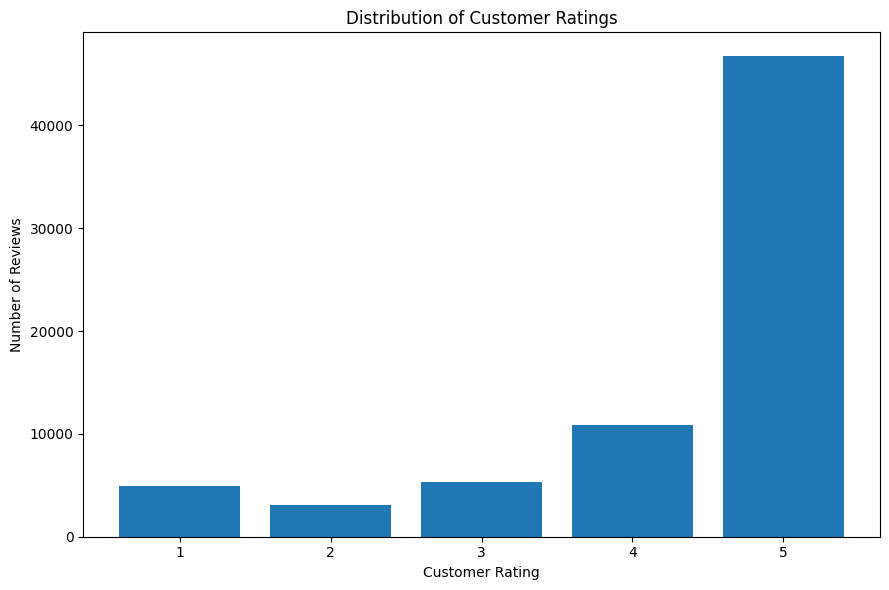

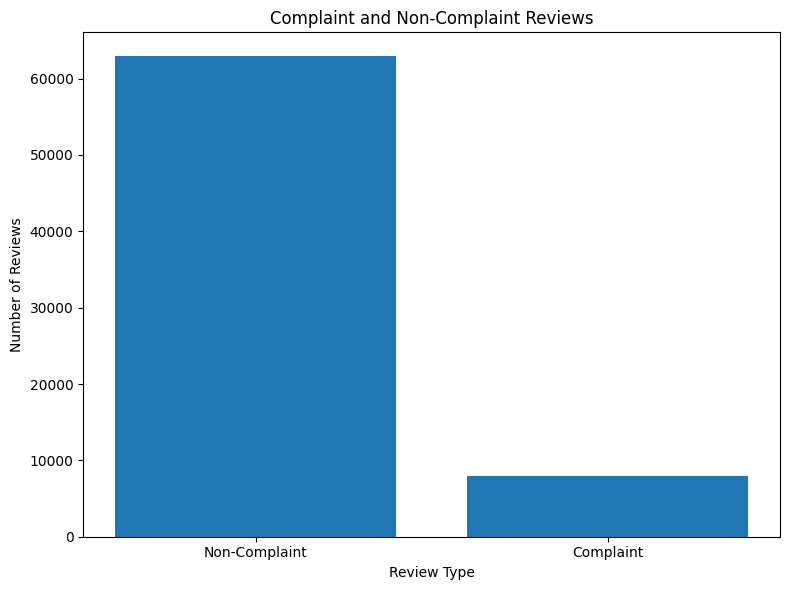



TABLE 4.4 — COMPLAINT TEXT LENGTH
         Statistic    Value
             Count  7933.00
              Mean   538.49
Standard deviation   762.00
           Minimum     5.00
   25th percentile   155.00
            Median   316.00
   75th percentile   633.00
           Maximum 23538.00


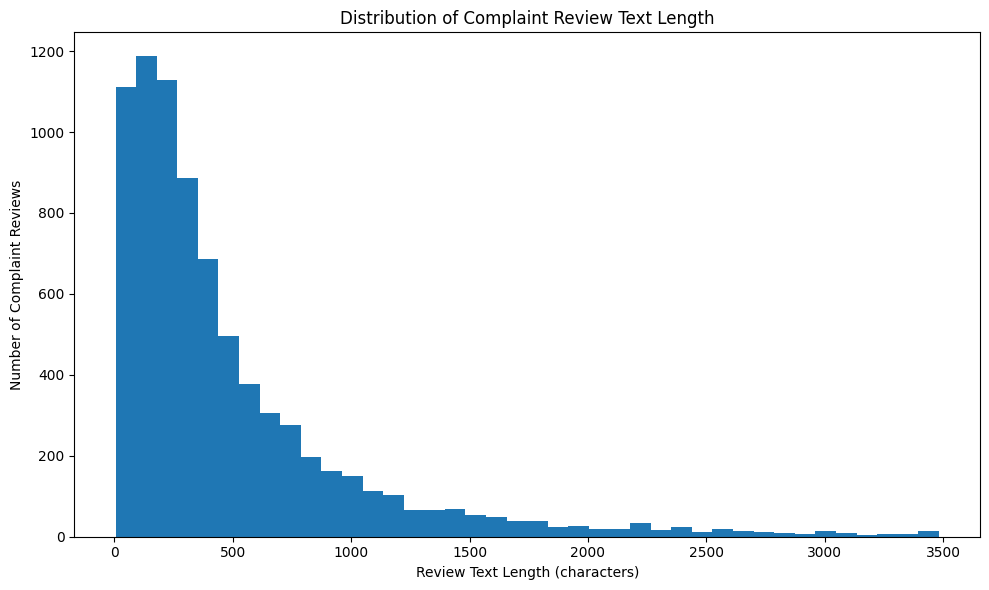



TABLE 4.5 — EMOTION DISTRIBUTION
 Emotion  Reviews  Percentage
 neutral     2767       34.88
 sadness     2319       29.23
 disgust     1129       14.23
surprise      843       10.63
   anger      471        5.94
    fear      323        4.07
     joy       81        1.02


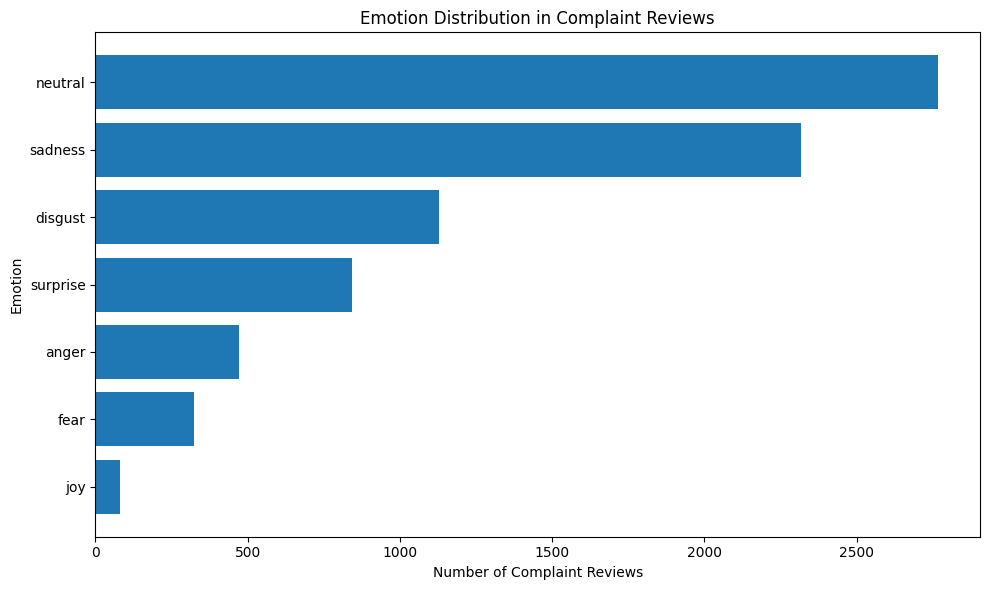



TABLE 4.6 — COMPLAINT ASPECT DISTRIBUTION
  Primary Aspect  Reviews  Percentage
 product_quality     2717       34.25
           other     2034       25.64
       usability     1338       16.87
           price     1066       13.44
customer_service      332        4.19
       packaging      262        3.30
        delivery      184        2.32


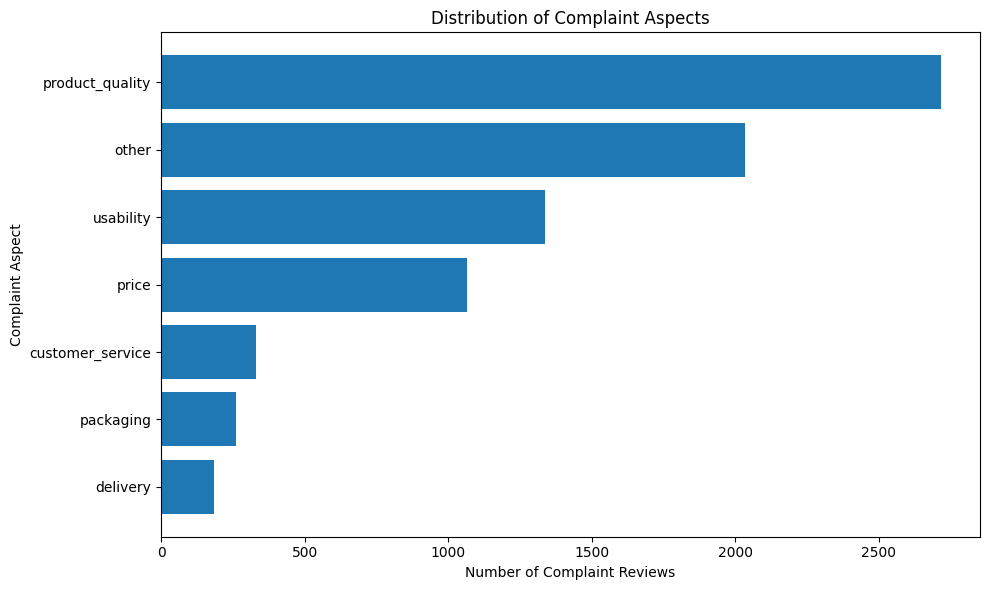



TABLE 4.7 — COMPLAINT INTENSITY SUMMARY
         Statistic  Value
              Mean 0.7666
Standard deviation 0.1368
           Minimum 0.2573
            Median 0.8064
           Maximum 0.9999


Intensity Category  Reviews  Percentage
              High     5929       74.74
            Medium     1934       24.38
               Low       70        0.88


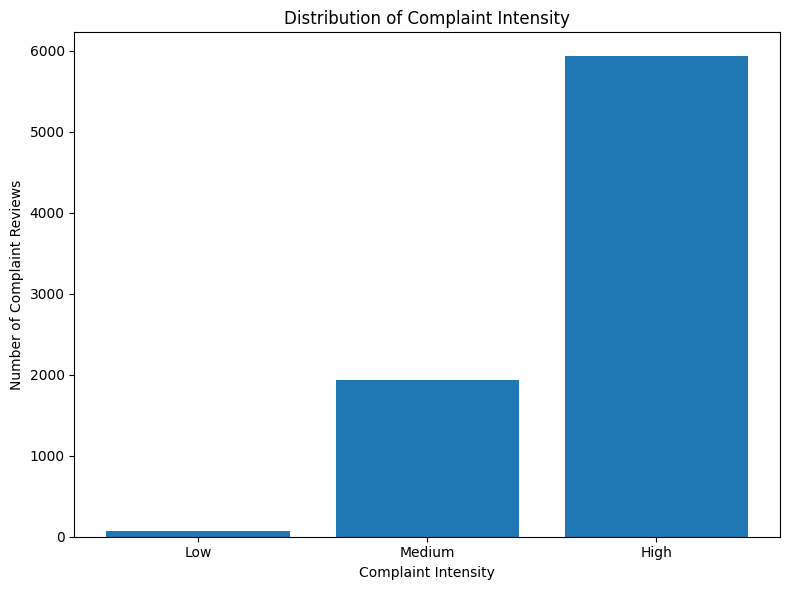



TABLE 4.9 — IMAGE COVERAGE BY RATING
 rating  total_reviews  image_reviews  image_percentage
    1.0           4893            161              3.29
    2.0           3040             61              2.01
    3.0           5308             86              1.62
    4.0          10908            181              1.66
    5.0          46705            692              1.48


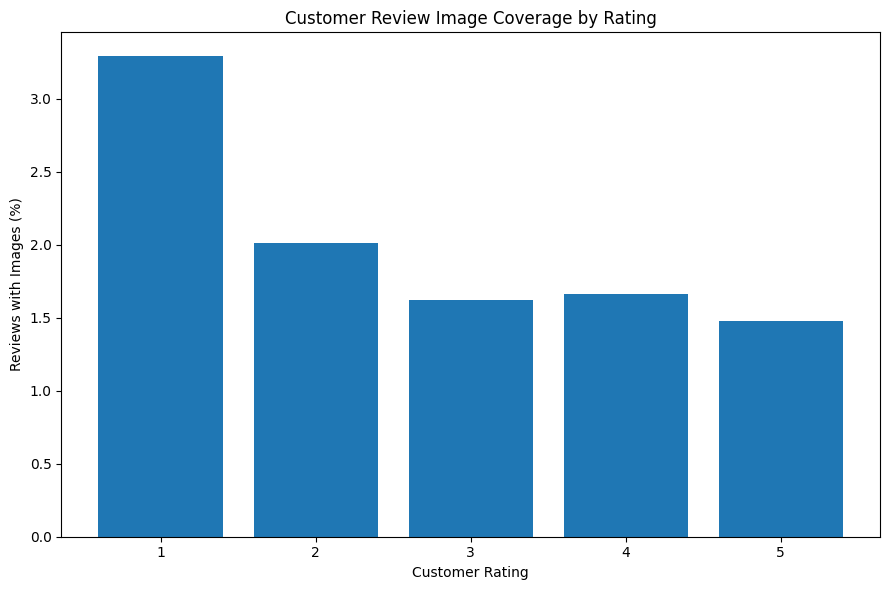



TABLE 4.10 — IMAGE COVERAGE BY COMPLAINT STATUS
  Review Type  total_reviews  image_reviews  image_percentage
Non-Complaint          62921            959              1.52
    Complaint           7933            222              2.80


TABLE 4.13 — IMAGE PROCESSING SUMMARY
                  Measure   Value
            Image records 2259.00
  Successfully downloaded 2251.00
         Failed downloads    8.00
Download success rate (%)   99.65


CHAPTER 4 ANALYSIS COMPLETE

Output folder:
/kaggle/working/chapter4_analysis

ZIP:
/kaggle/working/Chapter4_Analysis.zip


CHAPTER 4 — VERIFIED STATISTICS
Total reviews: 70854
Unique users: 20765
Unique products: 2815
Complaint reviews: 7933
Non-complaint reviews: 62921
Complaint percentage: 11.20%
Reviews with usable images: 1181
Image coverage: 1.67%
Mean complaint intensity: 0.7666

No separate CLIP visual-signal analysis was performed because review_visual_features.csv was not available in the current Kaggle session.

Generated files:
 - Cha

In [11]:
# ============================================================
# CHAPTER 4 — ANALYSIS
# SELF-CONTAINED KAGGLE VERSION
#
# DATA SOURCES:
# 1. final_multimodal_dataset.csv
# 2. review_images_downloaded.csv
#
# NOTE:
# review_visual_features.csv is intentionally NOT used.
# CLIP visual-signal analysis is therefore excluded from
# Chapter 4 in this version.
# ============================================================

import os
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# 1. EXACT KAGGLE PATHS
# ============================================================

BASE_PATH = (
    "/kaggle/input/datasets/"
    "vrindabhatia108/thesis-data"
)

MAIN_FILE = os.path.join(
    BASE_PATH,
    "final_multimodal_dataset.csv"
)

IMAGE_FILE = os.path.join(
    BASE_PATH,
    "review_images_downloaded.csv"
)

OUTPUT_DIR = "/kaggle/working/chapter4_analysis"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 2. VERIFY FILES
# ============================================================

print("=" * 75)
print("CHAPTER 4 — ANALYSIS")
print("=" * 75)

print("\nChecking files...")

if not os.path.exists(MAIN_FILE):

    raise FileNotFoundError(
        f"\nMain dataset not found:\n{MAIN_FILE}"
    )

if not os.path.exists(IMAGE_FILE):

    raise FileNotFoundError(
        f"\nImage dataset not found:\n{IMAGE_FILE}"
    )

print("Main dataset   :", MAIN_FILE)
print("Image dataset  :", IMAGE_FILE)


# ============================================================
# 3. LOAD DATA
# ============================================================

df = pd.read_csv(
    MAIN_FILE
)

images_df = pd.read_csv(
    IMAGE_FILE
)

print("\nMain dataset shape :", df.shape)
print("Image dataset shape:", images_df.shape)


# ============================================================
# 4. REQUIRED COLUMN CHECK
# ============================================================

required_main = [
    "user_id",
    "asin",
    "rating",
    "complaint",
    "review_text"
]

missing_main = [
    col for col in required_main
    if col not in df.columns
]

if missing_main:

    raise ValueError(
        "Missing columns in final_multimodal_dataset.csv:\n"
        + str(missing_main)
    )


# ============================================================
# 5. STANDARDISE DATA TYPES
# ============================================================

df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

df["complaint"] = pd.to_numeric(
    df["complaint"],
    errors="coerce"
).fillna(0).astype(int)

df["review_text"] = (
    df["review_text"]
    .fillna("")
    .astype(str)
)

df["user_id"] = (
    df["user_id"]
    .astype(str)
)

df["asin"] = (
    df["asin"]
    .astype(str)
)


# ============================================================
# 6. IMAGE INDICATOR
# ============================================================

if "visual_image_count" in df.columns:

    df["usable_image"] = (
        pd.to_numeric(
            df["visual_image_count"],
            errors="coerce"
        )
        .fillna(0)
        .gt(0)
        .astype(int)
    )

elif "has_image" in df.columns:

    df["usable_image"] = (
        df["has_image"]
        .astype(str)
        .str.lower()
        .isin([
            "true",
            "1",
            "yes"
        ])
        .astype(int)
    )

else:

    df["usable_image"] = 0


# ============================================================
# 7. BASIC DATASET STATISTICS
# ============================================================

total_reviews = len(df)

unique_users = df[
    "user_id"
].nunique()

unique_products = df[
    "asin"
].nunique()

complaint_count = int(
    df["complaint"].sum()
)

non_complaint_count = (
    total_reviews -
    complaint_count
)

complaint_percentage = (
    complaint_count /
    total_reviews *
    100
)

image_review_count = int(
    df["usable_image"].sum()
)

image_review_percentage = (
    image_review_count /
    total_reviews *
    100
)


# ============================================================
# 8. TABLE 4.1 — FINAL DATASET SUMMARY
# ============================================================

dataset_summary = pd.DataFrame({
    "Measure": [
        "Total review interactions",
        "Unique users",
        "Unique products",
        "Complaint reviews",
        "Non-complaint reviews",
        "Complaint proportion (%)",
        "Reviews with usable images",
        "Image review coverage (%)"
    ],
    "Value": [
        total_reviews,
        unique_users,
        unique_products,
        complaint_count,
        non_complaint_count,
        round(complaint_percentage, 2),
        image_review_count,
        round(image_review_percentage, 2)
    ]
})

dataset_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_1_Final_Dataset_Summary.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print("TABLE 4.1 — FINAL DATASET SUMMARY")
print("=" * 75)

print(
    dataset_summary.to_string(
        index=False
    )
)


# ============================================================
# 9. RATING DISTRIBUTION
# ============================================================

rating_counts = (
    df["rating"]
    .value_counts()
    .sort_index()
)

rating_table = pd.DataFrame({
    "Rating": rating_counts.index.astype(int),
    "Reviews": rating_counts.values
})

rating_table["Percentage"] = (
    rating_table["Reviews"] /
    total_reviews *
    100
).round(2)

rating_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_2_Rating_Distribution.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print("TABLE 4.2 — RATING DISTRIBUTION")
print("=" * 75)

print(
    rating_table.to_string(
        index=False
    )
)


# ============================================================
# 10. FIGURE 4.1 — RATING DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    rating_table["Rating"].astype(str),
    rating_table["Reviews"]
)

plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")

plt.title(
    "Distribution of Customer Ratings"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_1_Rating_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 11. COMPLAINT DISTRIBUTION
# ============================================================

complaint_table = pd.DataFrame({
    "Review Type": [
        "Non-Complaint",
        "Complaint"
    ],
    "Reviews": [
        non_complaint_count,
        complaint_count
    ]
})

complaint_table["Percentage"] = (
    complaint_table["Reviews"] /
    total_reviews *
    100
).round(2)

complaint_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_3_Complaint_Distribution.csv"
    ),
    index=False
)


# ============================================================
# 12. FIGURE 4.2 — COMPLAINT DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.bar(
    complaint_table["Review Type"],
    complaint_table["Reviews"]
)

plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")

plt.title(
    "Complaint and Non-Complaint Reviews"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_2_Complaint_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 13. COMPLAINT TEXT LENGTH
# ============================================================

complaints_df = df[
    df["complaint"] == 1
].copy()

complaints_df[
    "text_length_chars"
] = (
    complaints_df[
        "review_text"
    ]
    .str.len()
)

text_length_stats = (
    complaints_df[
        "text_length_chars"
    ]
    .describe()
)

text_length_table = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Standard deviation",
        "Minimum",
        "25th percentile",
        "Median",
        "75th percentile",
        "Maximum"
    ],
    "Value": [
        text_length_stats["count"],
        text_length_stats["mean"],
        text_length_stats["std"],
        text_length_stats["min"],
        text_length_stats["25%"],
        text_length_stats["50%"],
        text_length_stats["75%"],
        text_length_stats["max"]
    ]
})

text_length_table["Value"] = (
    text_length_table[
        "Value"
    ].round(2)
)

text_length_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_4_Complaint_Text_Length.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print("TABLE 4.4 — COMPLAINT TEXT LENGTH")
print("=" * 75)

print(
    text_length_table.to_string(
        index=False
    )
)


# ============================================================
# 14. FIGURE 4.3 — TEXT LENGTH
# ============================================================

upper_limit = complaints_df[
    "text_length_chars"
].quantile(0.99)

text_length_plot = complaints_df[
    complaints_df[
        "text_length_chars"
    ] <= upper_limit
]["text_length_chars"]

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    text_length_plot,
    bins=40
)

plt.xlabel(
    "Review Text Length (characters)"
)

plt.ylabel(
    "Number of Complaint Reviews"
)

plt.title(
    "Distribution of Complaint Review Text Length"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_3_Complaint_Text_Length.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 15. EMOTION DISTRIBUTION
# ============================================================

if "emotion" in df.columns:

    emotion_counts = (
        complaints_df[
            "emotion"
        ]
        .fillna("Unknown")
        .astype(str)
        .value_counts()
    )

    emotion_table = (
        emotion_counts
        .rename_axis("Emotion")
        .reset_index(
            name="Reviews"
        )
    )

    emotion_table["Percentage"] = (
        emotion_table["Reviews"] /
        emotion_table["Reviews"].sum() *
        100
    ).round(2)

    emotion_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_5_Emotion_Distribution.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 75)
    print("TABLE 4.5 — EMOTION DISTRIBUTION")
    print("=" * 75)

    print(
        emotion_table.to_string(
            index=False
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    emotion_plot = (
        emotion_table
        .sort_values(
            "Reviews",
            ascending=True
        )
    )

    plt.barh(
        emotion_plot["Emotion"],
        emotion_plot["Reviews"]
    )

    plt.xlabel(
        "Number of Complaint Reviews"
    )

    plt.ylabel(
        "Emotion"
    )

    plt.title(
        "Emotion Distribution in Complaint Reviews"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Figure_4_4_Emotion_Distribution.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 16. COMPLAINT ASPECT DISTRIBUTION
# ============================================================

if "primary_aspect" in df.columns:

    aspect_counts = (
        complaints_df[
            "primary_aspect"
        ]
        .fillna("other")
        .astype(str)
        .value_counts()
    )

    aspect_table = (
        aspect_counts
        .rename_axis(
            "Primary Aspect"
        )
        .reset_index(
            name="Reviews"
        )
    )

    aspect_table["Percentage"] = (
        aspect_table["Reviews"] /
        aspect_table["Reviews"].sum() *
        100
    ).round(2)

    aspect_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_6_Complaint_Aspect_Distribution.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 75)
    print(
        "TABLE 4.6 — COMPLAINT ASPECT DISTRIBUTION"
    )
    print("=" * 75)

    print(
        aspect_table.to_string(
            index=False
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    aspect_plot = (
        aspect_table
        .sort_values(
            "Reviews",
            ascending=True
        )
    )

    plt.barh(
        aspect_plot[
            "Primary Aspect"
        ],
        aspect_plot[
            "Reviews"
        ]
    )

    plt.xlabel(
        "Number of Complaint Reviews"
    )

    plt.ylabel(
        "Complaint Aspect"
    )

    plt.title(
        "Distribution of Complaint Aspects"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Figure_4_5_Complaint_Aspects.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 17. COMPLAINT INTENSITY
# ============================================================

if "complaint_intensity" in df.columns:

    complaints_df[
        "complaint_intensity"
    ] = pd.to_numeric(
        complaints_df[
            "complaint_intensity"
        ],
        errors="coerce"
    )

    intensity_stats = (
        complaints_df[
            "complaint_intensity"
        ]
        .describe()
    )

    intensity_summary = pd.DataFrame({
        "Statistic": [
            "Mean",
            "Standard deviation",
            "Minimum",
            "Median",
            "Maximum"
        ],
        "Value": [
            intensity_stats["mean"],
            intensity_stats["std"],
            intensity_stats["min"],
            intensity_stats["50%"],
            intensity_stats["max"]
        ]
    })

    intensity_summary["Value"] = (
        intensity_summary[
            "Value"
        ].round(4)
    )

    intensity_summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_7_Complaint_Intensity_Summary.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 75)
    print(
        "TABLE 4.7 — COMPLAINT INTENSITY SUMMARY"
    )
    print("=" * 75)

    print(
        intensity_summary.to_string(
            index=False
        )
    )


# ============================================================
# 18. INTENSITY CATEGORY
# ============================================================

if "intensity_category" in df.columns:

    category_counts = (
        complaints_df[
            "intensity_category"
        ]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .value_counts()
    )

    intensity_category = pd.DataFrame({
        "Intensity Category":
            category_counts.index,
        "Reviews":
            category_counts.values
    })

    intensity_category["Percentage"] = (
        intensity_category["Reviews"] /
        intensity_category["Reviews"].sum() *
        100
    ).round(2)

    intensity_category.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_8_Intensity_Category_Distribution.csv"
        ),
        index=False
    )

    print("\n")
    print(
        intensity_category.to_string(
            index=False
        )
    )


    preferred_order = [
        "Low",
        "Medium",
        "High"
    ]

    available = [
        x for x in preferred_order
        if x in intensity_category[
            "Intensity Category"
        ].values
    ]

    if available:

        plot_values = []

        for category in available:

            value = intensity_category.loc[
                intensity_category[
                    "Intensity Category"
                ] == category,
                "Reviews"
            ].iloc[0]

            plot_values.append(
                value
            )

        plt.figure(
            figsize=(8, 6)
        )

        plt.bar(
            available,
            plot_values
        )

        plt.xlabel(
            "Complaint Intensity"
        )

        plt.ylabel(
            "Number of Complaint Reviews"
        )

        plt.title(
            "Distribution of Complaint Intensity"
        )

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                "Figure_4_6_Complaint_Intensity.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()


# ============================================================
# 19. IMAGE COVERAGE BY RATING
# ============================================================

rating_image = (
    df.groupby("rating")
    .agg(
        total_reviews=(
            "asin",
            "size"
        ),
        image_reviews=(
            "usable_image",
            "sum"
        )
    )
    .reset_index()
)

rating_image[
    "image_percentage"
] = (
    rating_image[
        "image_reviews"
    ]
    /
    rating_image[
        "total_reviews"
    ]
    *
    100
).round(2)

rating_image.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_9_Image_Coverage_by_Rating.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print(
    "TABLE 4.9 — IMAGE COVERAGE BY RATING"
)
print("=" * 75)

print(
    rating_image.to_string(
        index=False
    )
)


# ============================================================
# 20. FIGURE 4.7 — IMAGE COVERAGE BY RATING
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    rating_image[
        "rating"
    ].astype(int).astype(str),
    rating_image[
        "image_percentage"
    ]
)

plt.xlabel(
    "Customer Rating"
)

plt.ylabel(
    "Reviews with Images (%)"
)

plt.title(
    "Customer Review Image Coverage by Rating"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_7_Image_Coverage_by_Rating.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 21. IMAGE COVERAGE BY COMPLAINT STATUS
# ============================================================

complaint_image = (
    df.groupby("complaint")
    .agg(
        total_reviews=(
            "asin",
            "size"
        ),
        image_reviews=(
            "usable_image",
            "sum"
        )
    )
    .reset_index()
)

complaint_image[
    "image_percentage"
] = (
    complaint_image[
        "image_reviews"
    ]
    /
    complaint_image[
        "total_reviews"
    ]
    *
    100
).round(2)

complaint_image[
    "Review Type"
] = complaint_image[
    "complaint"
].map({
    0: "Non-Complaint",
    1: "Complaint"
})

complaint_image = complaint_image[
    [
        "Review Type",
        "total_reviews",
        "image_reviews",
        "image_percentage"
    ]
]

complaint_image.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_10_Image_Coverage_by_Complaint_Status.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print(
    "TABLE 4.10 — IMAGE COVERAGE BY COMPLAINT STATUS"
)
print("=" * 75)

print(
    complaint_image.to_string(
        index=False
    )
)


# ============================================================
# 22. IMAGE DOWNLOAD / QUALITY ANALYSIS
# ============================================================

image_stats = {}

image_stats[
    "Image records"
] = len(images_df)

if "downloaded" in images_df.columns:

    downloaded_bool = (
        images_df[
            "downloaded"
        ]
        .fillna(False)
        .astype(bool)
    )

    image_stats[
        "Successfully downloaded"
    ] = int(
        downloaded_bool.sum()
    )

    image_stats[
        "Failed downloads"
    ] = int(
        (~downloaded_bool).sum()
    )

    image_stats[
        "Download success rate (%)"
    ] = round(
        downloaded_bool.mean() * 100,
        2
    )


if "format" in images_df.columns:

    format_counts = (
        images_df[
            images_df[
                "downloaded"
            ].fillna(False).astype(bool)
        ]["format"]
        .fillna("Unknown")
        .value_counts()
    )

    format_table = (
        format_counts
        .rename_axis("Format")
        .reset_index(
            name="Images"
        )
    )

    format_table["Percentage"] = (
        format_table["Images"] /
        format_table["Images"].sum() *
        100
    ).round(2)

    format_table.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_11_Image_Format_Distribution.csv"
        ),
        index=False
    )

if (
    "width" in images_df.columns and
    "height" in images_df.columns
):

    valid_dimensions = images_df[
        images_df[
            "downloaded"
        ].fillna(False).astype(bool)
    ].copy()

    valid_dimensions[
        "width"
    ] = pd.to_numeric(
        valid_dimensions[
            "width"
        ],
        errors="coerce"
    )

    valid_dimensions[
        "height"
    ] = pd.to_numeric(
        valid_dimensions[
            "height"
        ],
        errors="coerce"
    )

    valid_dimensions[
        "pixels"
    ] = (
        valid_dimensions[
            "width"
        ]
        *
        valid_dimensions[
            "height"
        ]
    )

    image_dimension_summary = (
        valid_dimensions[
            [
                "width",
                "height",
                "pixels"
            ]
        ]
        .describe()
        .round(2)
    )

    image_dimension_summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Table_4_12_Image_Dimension_Summary.csv"
        )
    )


# Display image summary

image_summary_table = pd.DataFrame({
    "Measure": list(
        image_stats.keys()
    ),
    "Value": list(
        image_stats.values()
    )
})

image_summary_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_4_13_Image_Processing_Summary.csv"
    ),
    index=False
)

print("\n")
print("=" * 75)
print(
    "TABLE 4.13 — IMAGE PROCESSING SUMMARY"
)
print("=" * 75)

print(
    image_summary_table.to_string(
        index=False
    )
)


# ============================================================
# 23. FINAL VERIFIED STATISTICS
# ============================================================

summary_lines = [
    "CHAPTER 4 — VERIFIED STATISTICS",
    "=" * 50,
    f"Total reviews: {total_reviews}",
    f"Unique users: {unique_users}",
    f"Unique products: {unique_products}",
    f"Complaint reviews: {complaint_count}",
    f"Non-complaint reviews: {non_complaint_count}",
    f"Complaint percentage: {complaint_percentage:.2f}%",
    f"Reviews with usable images: {image_review_count}",
    f"Image coverage: {image_review_percentage:.2f}%"
]

if (
    "complaint_intensity" in complaints_df.columns
):

    summary_lines.append(
        "Mean complaint intensity: "
        +
        f"{complaints_df['complaint_intensity'].mean():.4f}"
    )

summary_lines.append(
    "\nNo separate CLIP visual-signal analysis was "
    "performed because review_visual_features.csv "
    "was not available in the current Kaggle session."
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "Chapter4_Verified_Statistics.txt"
    ),
    "w"
) as f:

    f.write(
        "\n".join(summary_lines)
    )


# ============================================================
# 24. FILE INDEX
# ============================================================

generated_files = sorted(
    os.listdir(
        OUTPUT_DIR
    )
)

pd.DataFrame({
    "Generated File": generated_files
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Chapter4_File_Index.csv"
    ),
    index=False
)


# ============================================================
# 25. ZIP
# ============================================================

zip_base = (
    "/kaggle/working/Chapter4_Analysis"
)

shutil.make_archive(
    zip_base,
    "zip",
    OUTPUT_DIR
)


# ============================================================
# 26. FINAL PRINT
# ============================================================

print("\n")
print("=" * 75)
print("CHAPTER 4 ANALYSIS COMPLETE")
print("=" * 75)

print("\nOutput folder:")
print(OUTPUT_DIR)

print("\nZIP:")
print(
    zip_base + ".zip"
)

print("\n")
print(
    "\n".join(summary_lines)
)

print("\nGenerated files:")

for filename in generated_files:

    print(
        " -",
        filename
    )

print("\nDONE.")

Output directory: /kaggle/working/chapter5_results

TABLE 5.1


,Parameter,Value
0,Dataset size,"70,854 reviews"
1,Number of users,"20,765"
2,Number of products,"2,815"
3,Train/test split,80% training / 20% test
4,Evaluation users,500
5,SVD latent factors,30
6,Candidate generation,Top-50 SVD candidates
7,Ranking model,XGBRanker
8,Ranking objective,Pairwise ranking objective
9,Evaluation metrics,"Precision@5, Recall@5, NDCG@5, Precision@10, R..."



TABLE 5.2


,Model,P@5,R@5,NDCG@5,P@10,R@10,NDCG@10
0,SVD,0.0148,0.0577,0.0438,0.0102,0.0802,0.0515
1,SVD + Text XGBRanker,0.0116,0.0418,0.0284,0.0078,0.0565,0.0334
2,SVD + Image XGBRanker,0.0052,0.0207,0.0135,0.0052,0.0412,0.0206
3,SVD + Multimodal XGBRanker,0.0108,0.0408,0.0294,0.0072,0.0548,0.0342



TABLE 5.3


,Feature Group,Aggregate Importance (%)
0,Collaborative / SVD,2.5939
1,Text,52.4262
2,Visual,44.9800


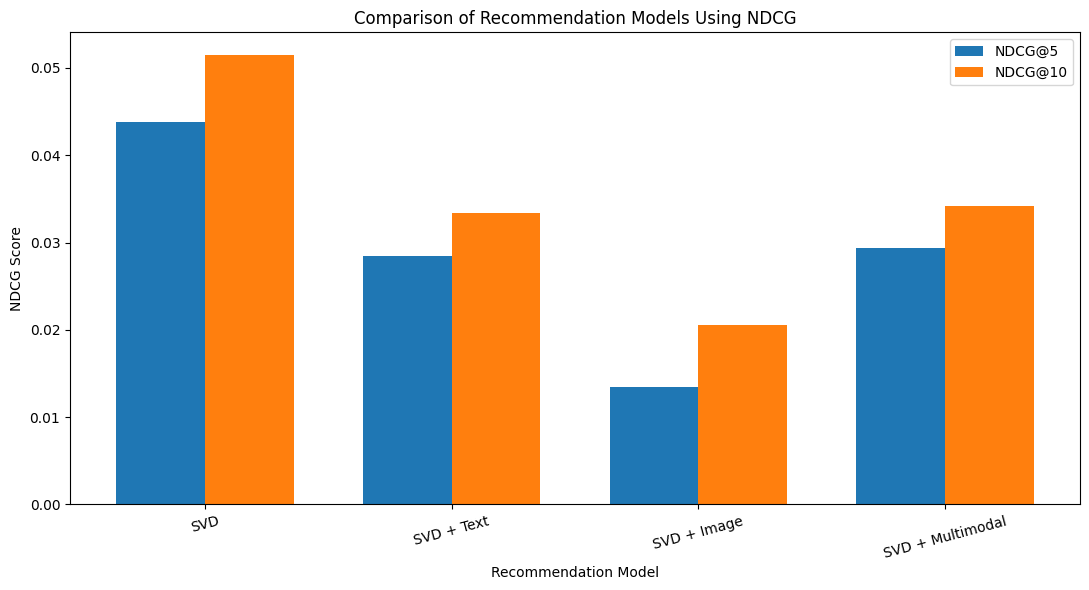

Saved: /kaggle/working/chapter5_results/Figure_5_1_NDCG_Model_Comparison.png

TOP FEATURES


,Feature,Importance
0,product_visual_good_condition_mean,0.0473
1,product_visual_normal_product_mean,0.0435
2,product_visual_poor_condition_mean,0.0360
3,product_visual_opened_packaging_mean,0.0342
4,user_sentiment_negativity,0.0338
5,product_visual_damaged_packaging_mean,0.0326
6,product_sentiment_negativity,0.0309
7,product_visual_defective_product_mean,0.0308
8,product_sentiment_encoded,0.0305
9,product_aspect_contribution,0.0305


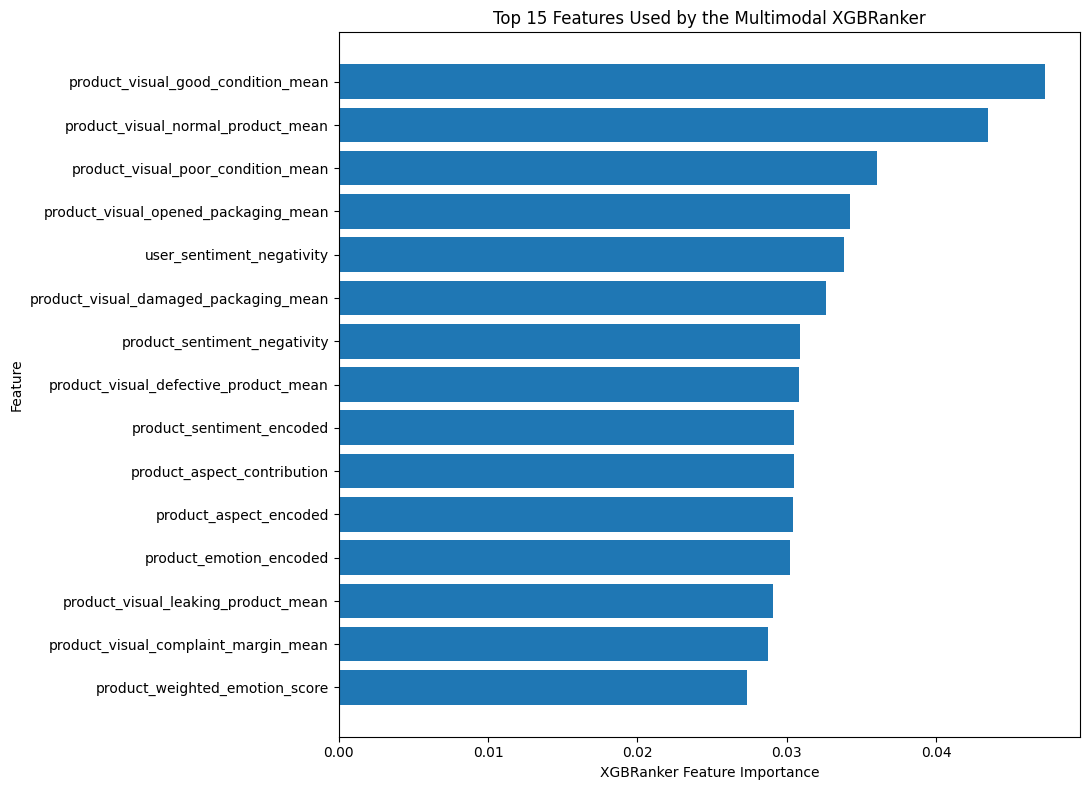

Saved: /kaggle/working/chapter5_results/Figure_5_2_XGBRanker_Feature_Importance.png

Excel file saved: /kaggle/working/chapter5_results/Chapter_5_Results_Tables.xlsx

CHAPTER 5 FILES CREATED
Chapter_5_Results_Tables.xlsx
Figure_5_1_NDCG_Model_Comparison.png
Figure_5_2_XGBRanker_Feature_Importance.png
Table_5_1_Experimental_Setup.csv
Table_5_2_Recommendation_Performance.csv
Table_5_3_Feature_Group_Importance.csv
Table_5_4_Top_Feature_Importance.csv

All files are in:
/kaggle/working/chapter5_results


In [1]:
# ============================================================
# CHAPTER 5 — RESULTS TABLES + FIGURES
# Creates:
#   Table 5.1 - Experimental Setup
#   Table 5.2 - Recommendation Performance
#   Table 5.3 - Feature Group Importance
#   Figure 5.1 - NDCG Model Comparison
#   Figure 5.2 - XGBRanker Feature Importance
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------
OUTPUT_DIR = "/kaggle/working/chapter5_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)


# ============================================================
# TABLE 5.1 — EXPERIMENTAL SETUP
# ============================================================

experimental_setup = pd.DataFrame({
    "Parameter": [
        "Dataset size",
        "Number of users",
        "Number of products",
        "Train/test split",
        "Evaluation users",
        "SVD latent factors",
        "Candidate generation",
        "Ranking model",
        "Ranking objective",
        "Evaluation metrics"
    ],
    "Value": [
        "70,854 reviews",
        "20,765",
        "2,815",
        "80% training / 20% test",
        "500",
        "30",
        "Top-50 SVD candidates",
        "XGBRanker",
        "Pairwise ranking objective",
        "Precision@5, Recall@5, NDCG@5, Precision@10, Recall@10, NDCG@10"
    ]
})

experimental_setup.to_csv(
    f"{OUTPUT_DIR}/Table_5_1_Experimental_Setup.csv",
    index=False
)

print("\nTABLE 5.1")
display(experimental_setup)


# ============================================================
# TABLE 5.2 — FINAL RECOMMENDATION RESULTS
# ============================================================

results = pd.DataFrame([
    {
        "Model": "SVD",
        "P@5": 0.0148,
        "R@5": 0.0577,
        "NDCG@5": 0.0438,
        "P@10": 0.0102,
        "R@10": 0.0802,
        "NDCG@10": 0.0515
    },
    {
        "Model": "SVD + Text XGBRanker",
        "P@5": 0.0116,
        "R@5": 0.0418,
        "NDCG@5": 0.0284,
        "P@10": 0.0078,
        "R@10": 0.0565,
        "NDCG@10": 0.0334
    },
    {
        "Model": "SVD + Image XGBRanker",
        "P@5": 0.0052,
        "R@5": 0.0207,
        "NDCG@5": 0.0135,
        "P@10": 0.0052,
        "R@10": 0.0412,
        "NDCG@10": 0.0206
    },
    {
        "Model": "SVD + Multimodal XGBRanker",
        "P@5": 0.0108,
        "R@5": 0.0408,
        "NDCG@5": 0.0294,
        "P@10": 0.0072,
        "R@10": 0.0548,
        "NDCG@10": 0.0342
    }
])

results.to_csv(
    f"{OUTPUT_DIR}/Table_5_2_Recommendation_Performance.csv",
    index=False
)

print("\nTABLE 5.2")
display(
    results.style.format({
        "P@5": "{:.4f}",
        "R@5": "{:.4f}",
        "NDCG@5": "{:.4f}",
        "P@10": "{:.4f}",
        "R@10": "{:.4f}",
        "NDCG@10": "{:.4f}"
    })
)


# ============================================================
# TABLE 5.3 — FEATURE GROUP IMPORTANCE
# ============================================================

feature_groups = pd.DataFrame({
    "Feature Group": [
        "Collaborative / SVD",
        "Text",
        "Visual"
    ],
    "Aggregate Importance (%)": [
        2.5939,
        52.4262,
        44.9800
    ]
})

feature_groups.to_csv(
    f"{OUTPUT_DIR}/Table_5_3_Feature_Group_Importance.csv",
    index=False
)

print("\nTABLE 5.3")
display(
    feature_groups.style.format({
        "Aggregate Importance (%)": "{:.4f}"
    })
)


# ============================================================
# FIGURE 5.1 — MODEL PERFORMANCE COMPARISON
# NDCG@5 AND NDCG@10
# ============================================================

plot_results = results.copy()

models = plot_results["Model"]
ndcg5 = plot_results["NDCG@5"]
ndcg10 = plot_results["NDCG@10"]

x = range(len(models))
width = 0.36

plt.figure(figsize=(11, 6))

plt.bar(
    [i - width/2 for i in x],
    ndcg5,
    width=width,
    label="NDCG@5"
)

plt.bar(
    [i + width/2 for i in x],
    ndcg10,
    width=width,
    label="NDCG@10"
)

plt.xticks(
    list(x),
    [
        "SVD",
        "SVD + Text",
        "SVD + Image",
        "SVD + Multimodal"
    ],
    rotation=15
)

plt.ylabel("NDCG Score")
plt.xlabel("Recommendation Model")
plt.title("Comparison of Recommendation Models Using NDCG")
plt.legend()
plt.tight_layout()

fig1_path = f"{OUTPUT_DIR}/Figure_5_1_NDCG_Model_Comparison.png"

plt.savefig(
    fig1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig1_path)


# ============================================================
# FIGURE 5.2 — XGBRANKER FEATURE IMPORTANCE
# TOP 15 FEATURES
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": [
        "product_visual_good_condition_mean",
        "product_visual_normal_product_mean",
        "product_visual_poor_condition_mean",
        "product_visual_opened_packaging_mean",
        "user_sentiment_negativity",
        "product_visual_damaged_packaging_mean",
        "product_sentiment_negativity",
        "product_visual_defective_product_mean",
        "product_sentiment_encoded",
        "product_aspect_contribution",
        "product_aspect_encoded",
        "product_emotion_encoded",
        "product_visual_leaking_product_mean",
        "product_visual_complaint_margin_mean",
        "product_weighted_emotion_score"
    ],
    "Importance": [
        0.047254,
        0.043489,
        0.036009,
        0.034196,
        0.033803,
        0.032641,
        0.030875,
        0.030817,
        0.030505,
        0.030459,
        0.030412,
        0.030196,
        0.029086,
        0.028705,
        0.027301
    ]
})

# Sort so the most important feature appears at the top
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=True
)

feature_importance.to_csv(
    f"{OUTPUT_DIR}/Table_5_4_Top_Feature_Importance.csv",
    index=False
)

print("\nTOP FEATURES")
display(
    feature_importance.sort_values(
        "Importance",
        ascending=False
    ).style.format({
        "Importance": "{:.4f}"
    })
)


plt.figure(figsize=(11, 8))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("XGBRanker Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Used by the Multimodal XGBRanker")

plt.tight_layout()

fig2_path = f"{OUTPUT_DIR}/Figure_5_2_XGBRanker_Feature_Importance.png"

plt.savefig(
    fig2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig2_path)


# ============================================================
# SAVE ALL RESULTS TO ONE EXCEL FILE
# ============================================================

excel_path = f"{OUTPUT_DIR}/Chapter_5_Results_Tables.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    experimental_setup.to_excel(
        writer,
        sheet_name="Table 5.1 Setup",
        index=False
    )

    results.to_excel(
        writer,
        sheet_name="Table 5.2 Results",
        index=False
    )

    feature_groups.to_excel(
        writer,
        sheet_name="Table 5.3 Groups",
        index=False
    )

    feature_importance.sort_values(
        "Importance",
        ascending=False
    ).to_excel(
        writer,
        sheet_name="Table 5.4 Features",
        index=False
    )

print("\nExcel file saved:", excel_path)


# ============================================================
# FINAL FILE LIST
# ============================================================

print("\n==============================")
print("CHAPTER 5 FILES CREATED")
print("==============================")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(file)

print("\nAll files are in:")
print(OUTPUT_DIR)